# Romper una molécula, un qubit a la vez: H₄ con VQE

**Quantum Jam 2026 · equipo quantum-toffolis** (Octavio, Gonzalo, Santino, Joaquín)

### Resumen

Calculamos con VQE la curva de energía de la cadena lineal H₄ (base STO-3G, 8 qubits con Jordan-Wigner) en 18 distancias entre 0,6 y 3,0 Å. Todas las energías reportadas se **miden** con `SamplerV2` de `qiskit_aer` (8 M de shots por punto, σ = 0,50–0,60 mHa), con una barra de error calibrada con 3600 repeticiones. El ansatz es ADAPT-VQE con una lista común de 15 excitaciones: **194 CZ** (378 con qubits en línea, gracias a un ruteo propio con fSWAP), contra 582 (1648) del UCCSD ×2 "de libro". En la zona estirada (d ≥ 1,8 Å), donde CCSD queda entre 9 y 31 mHa por debajo de la energía exacta, el VQE tiene un error de 0,56 mHa como máximo: le gana a CCSD en 7 de 7 puntos contando la σ y tiene **precisión química en las 18 distancias**. Obtenemos $R_e$ = 0,8873 ± 0,0018 Å (FCI: 0,8886 Å) y $D_e$ = 313,00 ± 0,66 mHa (FCI: 313,21 mHa). La confiabilidad se argumenta sin mirar FCI, con cantidades medidas: la varianza de la energía (por eco de Loschmidt), las simetrías $N_\alpha$, $N_\beta$ y $S^2$, y la convergencia con la profundidad del ansatz. Como extras, con un modelo de ruido de 0,1 % por CZ, bajamos a 5 qubits por simetrías y llegamos a precisión química con 16 CZ y mitigación de errores. También corrimos un punto en una copia simulada de un chip de IBM (FakeFez), probamos otras geometrías, comparamos ansätze y estimamos cuánto costaría escalar el método hasta FeMoco.

Este notebook cuenta **cómo llegamos**: arranca de lo mínimo que pide la consigna (un VQE con UCCSD que ya le ganaba a CCSD, pero con 1648 CZ en línea) y sigue el orden en que fuimos encontrando problemas. Cada capítulo tiene la misma estructura: **qué observamos → qué hipótesis planteamos → qué hicimos → qué dio y por qué funcionó (o no)**.

### Qué pide la consigna y dónde está

| pedido de la consigna | dónde | resultado |
|---|---|---|
| Curva $E(d)$ con ≥ 10 distancias entre 0,6 y 3,0 Å, con $\pm\sigma$, contra CCSD y FCI | §5 | 18 distancias, $\sigma$ = 0,50–0,60 mHa |
| Energías medidas con `SamplerV2` de `qiskit_aer` (no leyendo el estado) | §2.3, §4, §5 | todas las energías reportadas |
| $R_e$ y $D_e = E(3{,}0\ \text{Å}) - E(R_e)$ | §5 | $R_e$ = 0,8873 ± 0,0018 Å (FCI: 0,8886); $D_e$ = 313,00 ± 0,66 mHa (FCI: 313,21) |
| Ganarle a CCSD para $d \ge 1{,}8$ Å contando la barra de error | §5 | 7 de 7 puntos |
| Meta máxima: precisión química (< 1,6 mHa) en esa zona | §5 | 7 de 7 puntos (error máximo: 0,56 mHa) |
| Argumentar la confiabilidad **antes** de comparar con FCI | §6 | varianza medida (eco de Loschmidt), simetrías, profundidad y límite físico |
| Tabla con energía, error, shots y CZ por punto | §5 | columnas `E_vqe`, `sigma_mHa`, `shots`, `cz_all`, `cz_line_fswap` |
| Qué decidimos, por qué y qué no funcionó | cada capítulo y §13 | |
| Extras (opcionales) | §7–§12 | ruido, mitigación, FakeFez, 5 qubits, precisión química con ruido, comparar ansätze, otra geometría y escalado a FeMoco |

### El recorrido

1. **El problema** (§1): el hamiltoniano de H₄ escrito en qubits, término por término, y por qué CCSD falla al estirar.
2. **Lo mínimo** (§2): VQE con UCCSD. Cumple la consigna, pero deja **cinco problemas** a la vista, y cada uno se vuelve una hipótesis.
3. **Problema 1, demasiadas CZ** (§3): ADAPT-VQE elige solo las excitaciones que hacen falta, y un ruteo propio con fSWAP baja las CZ con qubits en línea: de 1648 a 378.
4. **Problema 2, demasiados shots y una σ dudosa** (§4): mejor agrupamiento y reparto de Neyman (hasta 1,9× menos shots) y 3600 repeticiones para calibrar la σ.
5. **Resultado central** (§5): la curva, la tabla, $R_e$ y $D_e$. **Problema 3**: el ajuste del mínimo tenía un sesgo de +8 mÅ.
6. **Problema 4, confiabilidad sin FCI** (§6): todo medido con shots, incluida la varianza por eco de Loschmidt.
7. **Problema 5, el ruido** (§7–§9): con 0,1 % de error por CZ, el VQE "de libro" es peor que no hacer nada. Simetrías (8 → 5 qubits), un ansatz de 16 CZ, mitigación y una copia de un chip de IBM.
8. **Más allá de la consigna** (§10–§12): otras geometrías, comparación de ansätze y cuánto costaría la molécula real (FeMoco).
9. **Resumen final** (§13): lo mínimo contra lo final, número por número, y las decisiones que explican la mejora.

> **Para correrlo:** *Entorno de ejecución → Ejecutar todo*. Instala sus dependencias, escribe el paquete `h4vqe/` y recalcula todo. Es largo: el resumen final (§13) dice cuánto tardó (en Colab gratis tarda bastante más que en una PC). Las energías reportadas salen siempre de medir circuitos con shots. Los cálculos con el estado exacto (sin shots) solo se usan para buscar parámetros y elegir entre alternativas, como permite la consigna, y están marcados como tales.


## 0 · Instalación y código

La primera celda instala lo que falte (Qiskit 2.6, Qiskit Aer 0.18, PySCF 2.15 y `qiskit-ibm-runtime` para FakeFez). La segunda escribe el paquete `h4vqe/`, así el notebook corre de punta a punta en un Colab nuevo. Las dos tienen el código oculto: con doble clic (o *Mostrar código* en Colab) se ve. Los módulos:

| módulo | qué hace | capítulo |
|---|---|---|
| `config` | distancias, shots por punto, ansatz de la curva | — |
| `hamiltonian` | PySCF → Ĥ en qubits (Jordan-Wigner); HF, FCI y CCSD de referencia | §1 |
| `ansatz`, `optimize` | excitaciones (UCCSD) como circuito, simulador numpy exacto y búsqueda de θ con gradiente analítico | §2, §3 |
| `adapt`, `routing` | ADAPT-VQE con lista común y ruteo fSWAP para qubits en línea | §3 |
| `estimator` | energía **medida** con `SamplerV2` de Aer: grupos, reparto de shots y σ | §2, §4 |
| `analysis`, `pipeline` | curva con warm start, tabla, $R_e$, $D_e$ y diagnósticos medidos | §5, §6 |
| `reduction`, `noise` | tapering 8 → 6 → 5 qubits, ansatz compacto y modelo de ruido | §7 |
| `mitigation` | corrección de lectura, post-selección por simetría y ZNE | §8 |
| `hardware`, `geometry` | FakeFez y otras geometrías | §9, §10 |
| `scaling` | escalado H₄ → H₁₄ → FeMoco | §12 |
| `historia` | diagnósticos de este relato (lo mínimo, ADAPT, shots, ruido por ansatz) | §1–§7, §13 |


In [1]:
# @title Instala las dependencias (código oculto)
# Instala dependencias si faltan (Colab arranca sin Qiskit ni PySCF).
import importlib.util, os, subprocess, sys
REQS = {"qiskit": "qiskit==2.6.2", "qiskit_aer": "qiskit-aer==0.18.4", "pyscf": "pyscf==2.15.0",
        "qiskit_ibm_runtime": "qiskit-ibm-runtime==0.52.1"}   # este último, solo para FakeFez (§9)
missing = [pip for mod, pip in REQS.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
os.makedirs("h4vqe", exist_ok=True)
import time; T_INICIO = time.time()   # el resumen final dice cuánto tardó todo
print("python", sys.version.split()[0], "- instalado:", missing or "nada (ya estaba)")

python 3.12.14 - instalado: nada (ya estaba)


In [2]:
# @title Paquete `h4vqe/`: escribe los módulos (código oculto, doble clic para verlo)
import os
os.makedirs("h4vqe", exist_ok=True)
ARCHIVOS = {
    '__init__.py': '''"""VQE para la curva de disociación de H4 lineal (Quantum Jam 2026)."""
''',
    'config.py': '''"""Configuración compartida. Cambiar acá, no en los módulos.

"""

BASIS = "sto-3g"

# Distancias H-H (Å). La consigna pide >= 10 puntos entre 0,6 y 3,0 Å.
# Hay puntos densos cerca del mínimo (~0,9 Å) para ajustar R_e.
DISTANCES = [0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 1.0, 1.1, 1.2, 1.4, 1.6,
             1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0]

STRETCHED_FROM = 1.8          # zona donde hay que ganarle a CCSD
CHEM_ACC = 1.6e-3             # Ha

# Presupuesto de shots por punto de la curva (estimación final, no optimización).
SHOTS_PER_POINT = 8_000_000   # σ ≈ 0,5 mHa en la zona estirada (QWC con sorted insertion + Neyman)

# Compuertas nativas que fija la consigna para el extra con ruido: cz, sx, x y rz.
# (ruido.py no se distribuye; el modelo de ruido propio está en noise.py.)
BASIS_GATES = ["cz", "rz", "sx", "x"]

SEED = 1234

# Ansatz de la curva principal:
#   "adapt": ADAPT-VQE fermiónico, lista común de 15 operadores (adapt.ADAPT_FERMIONIC).
#            194 CZ todos con todos, 378 en línea con el ruteo fSWAP de routing.py.
#            Error sin ruido ≤ 0,38 mHa en toda la curva.
#   "uccsd": UCCSD con ANSATZ_REPS pasos de Trotter (582 CZ con 2 pasos; < 1 µHa sin ruido).
ANSATZ = "adapt"

# Pasos de Trotter de UCCSD. Con ANSATZ = "adapt", UCCSD ×2 queda como referencia más
# profunda (prueba de profundidad, comparación de ansätze, geometría y FakeFez).
# Con 1 paso el error máximo es ~4,5 mHa (a 2,0 Å): le gana a CCSD pero sin precisión química.
ANSATZ_REPS = 2
''',
    'hamiltonian.py': '''"""Molécula H4 lineal -> hamiltoniano de qubits + referencias clásicas.

Convención de qubits (Jordan-Wigner, little-endian de Qiskit):
    qubits 0..norb-1      -> espín-orbitales alfa (orbital 0 = el de menor energía)
    qubits norb..2norb-1  -> espín-orbitales beta
El estado HF ocupa los qubits 0,1 (alfa) y 4,5 (beta): bitstring '00110011'.
"""
from __future__ import annotations

import numpy as np
from pyscf import gto, scf, mcscf, ao2mo, cc
from qiskit.quantum_info import SparsePauliOp

from .config import BASIS


ZIGZAG_ANGLE = 120.0   # ángulo H-H-H de la cadena en zigzag (grados)


def h4_geometry(d: float, shape: str = "linear") -> str:
    """4 H con vecinos a d Å: cadena recta (la del desafío), cadena en zigzag o cuadrado de lado d."""
    if shape == "linear":
        xyz = [(0, 0, i * d) for i in range(4)]
    elif shape == "zigzag":
        a = np.radians(ZIGZAG_ANGLE / 2)
        xyz = [(i * d * np.sin(a), (i % 2) * d * np.cos(a), 0) for i in range(4)]
    elif shape == "square":
        xyz = [(0, 0, 0), (d, 0, 0), (d, d, 0), (0, d, 0)]
    else:
        raise ValueError(f"forma desconocida: {shape!r}")
    return "; ".join(f"H {x:.6f} {y:.6f} {z:.6f}" for x, y, z in xyz)


def stable_rhf(mol, max_iter: int = 10):
    """RHF que sigue las inestabilidades internas hasta llegar a una solución estable.

    En el H4 cuadrado hay orbitales degenerados y el SCF puede terminar en un punto silla, según el
    entorno (hilos, versión de Python): a 1,2 Å queda 76 mHa por encima del RHF estable, y con esa
    referencia CCSD daba +180 mHa en vez de −6,5 mHa. En la cadena recta y en el zigzag RHF ya es
    estable en las 18 distancias, así que ahí esto no cambia nada.
    """
    hf = scf.RHF(mol)
    hf.conv_tol = 1e-10
    hf.kernel()
    for _ in range(max_iter):
        mo, _, stable, _ = hf.stability(return_status=True)
        if stable:
            break
        hf.kernel(dm0=hf.make_rdm1(mo, hf.mo_occ))
    return hf


def molecule(d: float, basis: str = BASIS, shape: str = "linear") -> dict:
    """Integrales en base de orbitales HF + energías HF, FCI y CCSD."""
    mol = gto.M(atom=h4_geometry(d, shape), basis=basis, unit="Angstrom", verbose=0)
    hf = stable_rhf(mol)
    norb = mol.nao_nr()
    nelec = mol.nelectron
    cas = mcscf.CASCI(hf, norb, nelec)
    h1, ecore = cas.get_h1cas()
    g = ao2mo.restore(1, cas.get_h2cas(), norb)
    e_fci = cas.kernel()[0]

    ccsd = cc.CCSD(hf)
    ccsd.conv_tol = 1e-9
    ccsd.max_cycle = 500
    ccsd.kernel()

    return {
        "d": d, "shape": shape, "mol": mol, "hf": hf, "norb": norb,
        "nelec": (nelec // 2, nelec // 2),
        "h": h1, "g": g, "constante": ecore,
        "e_hf": hf.e_tot, "e_fci": e_fci,
        "e_ccsd": ccsd.e_tot, "ccsd_converged": bool(ccsd.converged),
    }


def _annihilation_jw(p: int, n_qubits: int) -> SparsePauliOp:
    return SparsePauliOp.from_sparse_list(
        [("Z" * p + "X", list(range(p + 1)), 0.5),
         ("Z" * p + "Y", list(range(p + 1)), 0.5j)], n_qubits)


def annihilation_ops(n_qubits: int) -> list[SparsePauliOp]:
    return [_annihilation_jw(p, n_qubits) for p in range(n_qubits)]


def qubit_hamiltonian(m: dict) -> SparsePauliOp:
    """Ĥ = E_core + Σ h_pq a†_p a_q + ½ Σ g_pqrs a†_p a†_r a_s a_q  (Jordan-Wigner)."""
    norb = m["norb"]
    nq = 2 * norb
    h, g = m["h"], m["g"]
    a = annihilation_ops(nq)
    ad = [op.adjoint() for op in a]
    hop = [[[ad[s * norb + p].dot(a[s * norb + q]).simplify() for q in range(norb)]
            for p in range(norb)] for s in range(2)]
    terms = [SparsePauliOp("I" * nq, m["constante"])]
    for s in range(2):
        for p in range(norb):
            for q in range(norb):
                terms.append(h[p, q] * hop[s][p][q])
    for s in range(2):
        for t in range(2):
            for p in range(norb):
                for q in range(norb):
                    second = SparsePauliOp.sum([g[p, q, r, u] * hop[t][r][u]
                                                for r in range(norb) for u in range(norb)])
                    terms.append(0.5 * hop[s][p][q].dot(second))
                    if s == t:
                        for u in range(norb):
                            terms.append(-0.5 * g[p, q, q, u] * hop[s][p][u])
    return SparsePauliOp.sum(terms).simplify(atol=1e-10).chop(1e-10)


def number_operators(norb: int) -> dict[str, SparsePauliOp]:
    """N_alfa, N_beta y S^2 en qubits, para chequear simetrías del estado."""
    nq = 2 * norb
    a = annihilation_ops(nq)
    n = [a[p].adjoint().dot(a[p]).simplify() for p in range(nq)]
    na = SparsePauliOp.sum(n[:norb]).simplify()
    nb = SparsePauliOp.sum(n[norb:]).simplify()
    sz = 0.5 * (na - nb)
    sp = SparsePauliOp.sum([a[p].adjoint().dot(a[norb + p]) for p in range(norb)]).simplify()
    s2 = (sp.dot(sp.adjoint()) + sz.dot(sz) - sz).simplify(atol=1e-12)
    return {"N_alpha": na, "N_beta": nb, "S2": s2}


def exact_ground_energy(H: SparsePauliOp) -> float:
    """Diagonalización completa (256x256). Solo como chequeo contra FCI."""
    return float(np.linalg.eigvalsh(H.to_matrix())[0])


def sector_indices(norb: int, nelec: tuple[int, int]) -> np.ndarray:
    """Índices de la base computacional con N_alfa y N_beta fijos (bit q = ocupación del qubit q)."""
    i = np.arange(2 ** (2 * norb))
    bits = (i[:, None] >> np.arange(2 * norb)) & 1
    return i[(bits[:, :norb].sum(1) == nelec[0]) & (bits[:, norb:].sum(1) == nelec[1])]


def hf_index(norb: int, nelec: tuple[int, int]) -> int:
    """Índice del determinante HF: los n_alfa y n_beta orbitales más bajos ocupados."""
    return sum(1 << q for q in range(nelec[0])) + sum(1 << (norb + q) for q in range(nelec[1]))


def sector_ground_state(H: SparsePauliOp, norb: int, nelec: tuple[int, int]) -> tuple[float, np.ndarray]:
    """Estado fundamental de Ĥ solo en el sector (N_alfa, N_beta): 36x36 para H4 en vez de 256x256."""
    idx = sector_indices(norb, nelec)
    w, v = np.linalg.eigh(H.to_matrix(sparse=True)[idx][:, idx].toarray())
    psi = np.zeros(2 ** (2 * norb), dtype=complex)
    psi[idx] = v[:, 0]
    return float(w[0]), psi


def validation_table(distances) -> list[dict]:
    """Por distancia: chequeo de Ĥ contra PySCF (HF y FCI), peso de HF en FCI y error de CCSD."""
    rows = []
    s2_op = None
    for d in distances:
        m = molecule(d)
        H = qubit_hamiltonian(m)
        k = hf_index(m["norb"], m["nelec"])
        e_hf_q = H.to_matrix(sparse=True)[k, k].real
        e_sec, psi = sector_ground_state(H, m["norb"], m["nelec"])
        if s2_op is None:
            s2_op = number_operators(m["norb"])["S2"].to_matrix(sparse=True)
        rows.append({
            "d": d, "n_paulis": len(H),
            "err_hf": e_hf_q - m["e_hf"],             # <HF|Ĥ|HF> − E_HF(PySCF)
            "err_fci": e_sec - m["e_fci"],            # E_0(Ĥ, sector 2α2β) − E_FCI(PySCF)
            "s2": float(np.vdot(psi, s2_op @ psi).real),  # 0 = singulete
            "w_hf": abs(psi[k]) ** 2,                 # peso del determinante HF en el estado FCI
            "ccsd_minus_fci_mHa": 1e3 * (m["e_ccsd"] - m["e_fci"]),
            "ccsd_converged": m["ccsd_converged"],
        })
    return rows
''',
    'ansatz.py': '''"""Ansatz que conserva el número de partículas (UCCSD con Trotter, 1 paso por defecto).

Cada excitación k es una compuerta exp(-i θ_k G_k) con G_k = i(T_k - T_k†).
Los términos de Pauli de un mismo G_k conmutan entre sí, así que el circuito
implementa EXACTAMENTE Π_k exp(-i θ_k G_k). Eso permite optimizar con un
simulador numpy rápido (`FastAnsatz`) y después medir el MISMO circuito con shots.

Interfaz que usan los otros módulos (no romperla):
    build_ansatz(m, ...) -> Ansatz   con .circuit (parametrizado), .fast, .excitations
    cz_count(circuit, coupling="all"|"line") -> int
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import CouplingMap

from .config import BASIS_GATES, SEED
from .hamiltonian import annihilation_ops


def hf_occupation(m: dict) -> list[int]:
    norb = m["norb"]
    na, nb = m["nelec"]
    return list(range(na)) + [norb + i for i in range(nb)]


def uccsd_excitations(m: dict) -> list[tuple[tuple[int, ...], tuple[int, ...]]]:
    """Simples y dobles ocupado -> vacío que conservan S_z."""
    norb = m["norb"]
    na, nb = m["nelec"]
    occ = [list(range(na)), [norb + i for i in range(nb)]]
    vac = [list(range(na, norb)), [norb + i for i in range(nb, norb)]]
    ex = [((i,), (a,)) for s in range(2) for i in occ[s] for a in vac[s]]
    ex += [((i, j), (a, b)) for i in occ[0] for j in occ[1] for a in vac[0] for b in vac[1]]
    for s in range(2):
        for x, i in enumerate(occ[s]):
            for j in occ[s][x + 1:]:
                for y, a in enumerate(vac[s]):
                    for b in vac[s][y + 1:]:
                        ex.append(((i, j), (a, b)))
    return ex


def qubit_annihilation_ops(nq: int) -> list[SparsePauliOp]:
    """Q_p = (X_p + iY_p)/2, SIN cadena de Z (excitaciones de qubit, QEB)."""
    return [SparsePauliOp.from_sparse_list([("X", [p], 0.5), ("Y", [p], 0.5j)], nq)
            for p in range(nq)]


def excitation_generator(exc, nq: int, a=None, kind: str = "fermionic") -> SparsePauliOp:
    """G = i(T - T†), con T = a†_a a†_b a_j a_i.

    kind="fermionic": a_p de Jordan-Wigner (con cadenas Z).
    kind="qeb": excitación de qubit, Q_p sin cadenas Z (Yordanov et al., 2020/2021).
    Conserva N_alfa y N_beta igual, pero toca solo 2 o 4 qubits, así que
    cuesta menos CZ, sobre todo con qubits en línea.
    """
    if a is None:
        a = annihilation_ops(nq) if kind == "fermionic" else qubit_annihilation_ops(nq)
    src, dst = exc
    T = SparsePauliOp("I" * nq)
    for p in dst:
        T = T.dot(a[p].adjoint())
    for p in reversed(src):
        T = T.dot(a[p])
    return (1j * (T - T.adjoint())).simplify(atol=1e-12)


def _multiplexor_weights(n_ctrl: int) -> tuple[list[int], np.ndarray]:
    """RY multicontrolada (todos los controles en 1) con 2^n RY y 2^n CNOT (código Gray).

    Devuelve el orden de controles de las CNOT y los pesos w_k: RY(w_k φ) antes de la
    CNOT k. Con X^m antes de una RY(α), el ángulo efectivo es (−1)^m α, así que el
    ángulo total para los controles c es Σ_k (−1)^{m_k(c)} w_k φ. Se pide φ si c = 1…1
    y 0 si no (sistema lineal de ±1, invertible).
    """
    n = 2 ** n_ctrl
    order = [(k & -k).bit_length() - 1 if k < n else n_ctrl - 1 for k in range(1, n + 1)]
    M = np.zeros((n, n))
    for c in range(n):
        m = 0
        for k in range(n):
            M[c, k] = (-1) ** m
            m ^= (c >> order[k]) & 1
    f = np.zeros(n)
    f[n - 1] = 1.0
    return order, np.linalg.solve(M, f)


def excitation_circuit(exc, nq: int, theta, kind: str = "fermionic") -> QuantumCircuit:
    """Circuito compacto que implementa EXACTAMENTE exp(−iθG) para una excitación.

    Simple ((i,), (a,)):     CNOT(a→i), RY(2σθ) en a controlada por i, CNOT(a→i).
    Doble ((i, j), (a, b)):  escalera CNOT(i→j), CNOT(a→b), CNOT(a→i) que lleva el par
    |s1⟩ = |ij ocupados⟩, |s2⟩ = |ab ocupados⟩ a dos estados que difieren solo en a;
    después, RY(2σθ) en a controlada por i = 1, j = 0, b = 0 (8 CNOT); después, la
    escalera inversa. Total: 14 CNOT para la doble y 4 para la simple, actuando SOLO
    sobre los qubits de la excitación, lo que se rutea mucho mejor en línea que
    PauliEvolutionGate.
    Fermiónica: el signo σ de T|s1⟩ depende de la paridad de algunos qubits espectadores
    (cadenas Z de Jordan-Wigner). Se implementa con CNOT(q→a) antes y después de la
    rotación (X en el blanco invierte el ángulo de la RY).
    """
    src, dst = exc
    G = excitation_generator(exc, nq, kind=kind).to_matrix(sparse=True)
    s1 = sum(1 << q for q in src)
    s2 = sum(1 << q for q in dst)
    spect = [q for q in range(nq) if q not in src + dst]
    # -iθG = θ(T − T†): s1 -> cos θ s1 + σ sin θ s2, con σ = <s2|(-iG)|s1> = <s2|T|s1>
    sigma0 = np.real(-1j * G[s2, s1])
    parity = [q for q in spect
              if np.real(-1j * G[s2 | (1 << q), s1 | (1 << q)]) * sigma0 < 0]
    if len(src) == 1:
        (i,), (a,) = src, dst
        ladder = [(a, i)]
        ctrls, vals, target = [i], [1], a
    else:
        (i, j), (a, b) = src, dst
        ladder = [(i, j), (a, b), (a, i)]
        ctrls, vals, target = [i, j, b], [1, 0, 0], a
    order, w = _multiplexor_weights(len(ctrls))
    qc = QuantumCircuit(nq)
    for c, t in ladder:
        qc.cx(c, t)
    neg = [c for c, v in zip(ctrls, vals) if v == 0]
    for q in parity:
        qc.cx(q, target)
    if neg:
        qc.x(neg)
    for k, wk in enumerate(w):
        qc.ry(2.0 * sigma0 * wk * theta, target)
        qc.cx(ctrls[order[k]], target)
    if neg:
        qc.x(neg)
    for q in parity:
        qc.cx(q, target)
    for c, t in reversed(ladder):
        qc.cx(c, t)
    return qc


class FastAnsatz:
    """Simulador numpy exacto de Π_k exp(-i θ_k G_k)|HF> (solo para OPTIMIZAR)."""

    def __init__(self, generators: list[SparsePauliOp], hf_index: int, nq: int):
        self.G = [g.to_matrix(sparse=False) for g in generators]
        self.G2 = [G @ G for G in self.G]
        for G, G2 in zip(self.G, self.G2):  # exp cerrada requiere G^3 = G
            assert np.allclose(G2 @ G, G, atol=1e-10), "G^3 != G"
        self.psi0 = np.zeros(2 ** nq, dtype=complex)
        self.psi0[hf_index] = 1.0

    @classmethod
    def from_matrices(cls, G: list, G2: list, psi0: np.ndarray) -> "FastAnsatz":
        """Igual que el constructor, pero con matrices ya calculadas (lo usa ADAPT)."""
        obj = cls.__new__(cls)
        obj.G, obj.G2, obj.psi0 = list(G), list(G2), psi0
        return obj

    def state(self, theta) -> np.ndarray:
        psi = self.psi0
        for t, G, G2 in zip(theta, self.G, self.G2):
            # exp(-i t G) = I + (cos t - 1) G^2 - i sin t G
            psi = psi + (np.cos(t) - 1.0) * (G2 @ psi) - 1j * np.sin(t) * (G @ psi)
        return psi

    def energy_and_grad(self, theta, Hm: np.ndarray):
        """Energía y gradiente analítico (barrido hacia atrás)."""
        n = len(theta)
        states = [self.psi0]
        for t, G, G2 in zip(theta, self.G, self.G2):
            p = states[-1]
            states.append(p + (np.cos(t) - 1.0) * (G2 @ p) - 1j * np.sin(t) * (G @ p))
        psi = states[-1]
        lam = Hm @ psi
        e = float(np.real(np.vdot(psi, lam)))
        grad = np.zeros(n)
        for k in reversed(range(n)):
            # dE/dθ_k = 2 Re <λ| (-i G_k) |ψ_k>, con ψ_k el estado después de la compuerta k
            grad[k] = 2.0 * np.real(np.vdot(lam, -1j * (self.G[k] @ states[k + 1])))
            t, G, G2 = theta[k], self.G[k], self.G2[k]
            # λ <- U_k† λ
            lam = lam + (np.cos(t) - 1.0) * (G2 @ lam) + 1j * np.sin(t) * (G @ lam)
        return e, grad


@dataclass
class Ansatz:
    circuit: QuantumCircuit          # parametrizado, en compuertas nativas (sin acoplamiento)
    excitations: list
    fast: FastAnsatz
    params: ParameterVector
    meta: dict = field(default_factory=dict)

    @property
    def num_parameters(self) -> int:
        return len(self.params)


def build_ansatz(m: dict, excitations=None, reps: int = 1, kind: str = "fermionic") -> Ansatz:
    """UCCSD (o la lista de excitaciones que se pase, p. ej. la de ADAPT).

    kind="fermionic" (default) o "qeb" (excitaciones de qubit, ver excitation_generator).
    """
    norb = m["norb"]
    nq = 2 * norb
    excitations = list(excitations or uccsd_excitations(m)) * reps
    a = annihilation_ops(nq) if kind == "fermionic" else qubit_annihilation_ops(nq)
    gens = [excitation_generator(e, nq, a, kind) for e in excitations]
    theta = ParameterVector("θ", len(gens))
    qc = QuantumCircuit(nq)
    occ = hf_occupation(m)
    for q in occ:
        qc.x(q)
    for t, G in zip(theta, gens):
        qc.append(PauliEvolutionGate(G, time=t), range(nq))
    native = transpile(qc, basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=SEED)
    hf_index = sum(1 << q for q in occ)
    return Ansatz(native, excitations, FastAnsatz(gens, hf_index, nq), theta,
                  {"reps": reps, "n_qubits": nq, "kind": kind})


def cz_count(circuit: QuantumCircuit, coupling: str = "all", seed: int = SEED) -> int:
    """CZ después de transpilar. coupling='line' = qubits en línea (modelo de ruido)."""
    kw = {}
    if coupling == "line":
        kw["coupling_map"] = CouplingMap.from_line(circuit.num_qubits)
    t = transpile(circuit, basis_gates=BASIS_GATES, optimization_level=3,
                  seed_transpiler=seed, **kw)
    return int(t.count_ops().get("cz", 0))
''',
    'optimize.py': '''"""Búsqueda de parámetros SIN ruido (permitido por la consigna).

Los θ* se buscan con el simulador numpy exacto del ansatz. La energía que se
REPORTA no sale de acá: sale de medir el circuito con shots (estimator.py).
"""
from __future__ import annotations

import numpy as np
from scipy.optimize import minimize

from .ansatz import Ansatz


def optimize_params(ans: Ansatz, H, x0=None, tol: float = 1e-10, maxiter: int = 2000,
                    n_restarts: int = 0, seed: int = 0) -> dict:
    """L-BFGS-B con gradiente analítico. Devuelve dict con x, energy, nfev.

    Siempre prueba también θ = 0 (|HF⟩), además del x0 dado (warm start de la distancia
    anterior), y se queda con la energía más baja (es variacional, así que el mínimo es el
    mejor). Con la lista ADAPT de 15 operadores, el warm start solo cae en mínimos malos
    a 2,6-3,0 Å (hasta 2 mHa), y desde θ = 0 da 0,05-0,15 mHa.
    """
    Hm = H.to_matrix(sparse=True)
    fun = lambda x: ans.fast.energy_and_grad(x, Hm)
    zero = np.zeros(ans.num_parameters)
    bases = [zero] if x0 is None else [np.asarray(x0, float), zero]
    rng = np.random.default_rng(seed)
    starts = list(bases)
    starts += [b + rng.normal(0, 0.1, ans.num_parameters) for b in bases for _ in range(n_restarts)]
    best = None
    for s in starts:
        r = minimize(fun, s, jac=True, method="L-BFGS-B",
                     options={"maxiter": maxiter, "ftol": tol, "gtol": 1e-8})
        if best is None or r.fun < best.fun:
            best = r
    return {"x": best.x, "energy": float(best.fun), "nfev": int(best.nfev),
            "success": bool(best.success)}


def exact_state(ans: Ansatz, x) -> np.ndarray:
    """Solo para diagnóstico (fidelidad, varianza). NUNCA para la energía reportada."""
    return ans.fast.state(x)
''',
    'estimator.py': '''"""Energía MEDIDA con SamplerV2 de qiskit_aer, con barra de error ±σ.

Método:
  1. Se agrupan los términos de Pauli que conmutan qubit a qubit (QWC).
  2. Cada grupo se mide en su base (H para X, S†H para Y) con N_g shots.
  3. Cada shot da UNA muestra del observable del grupo O_g = Σ c_k P_k,
     así que E_g = media muestral y σ_g² = var muestral / N_g
     (las covarianzas dentro del grupo quedan incluidas).
  4. E = constante + Σ_g E_g ;  σ² = Σ_g σ_g²  (grupos independientes).

Interfaz: measure_energy(circuit_bound, H, total_shots, ...) -> dict

Asignación de shots en dos etapas (piloto + Neyman), ver measure_energy.

Implementación: para cada grupo se precalcula una tabla con el valor de O_g para
cada bitstring posible (2^n entradas). Los conteos se hacen con np.bincount
sobre el arreglo de bits del SamplerV2 (mucho más rápido que get_counts con
millones de shots). Los circuitos de medición se transpilan una sola vez
(`prepare_measurement`) y se pueden reusar entre llamadas.
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Pauli, SparsePauliOp, StabilizerState
from qiskit_aer.primitives import SamplerV2 as AerSampler

from .config import BASIS_GATES, SEED


def split_constant(H: SparsePauliOp) -> tuple[float, SparsePauliOp]:
    ident = "I" * H.num_qubits
    const = sum(c for p, c in H.to_list() if p == ident)
    rest = SparsePauliOp.from_list([(p, c) for p, c in H.to_list() if p != ident])
    return float(np.real(const)), rest


def measurement_groups(H: SparsePauliOp, method: str = "sorted",
                       grouping: str = "qwc") -> list[SparsePauliOp]:
    """Grupos de términos que se miden juntos.
    grouping="qwc": conmutan qubit a qubit (se miden con H / S†H por qubit).
    grouping="gc":  conmutan en general (se miden con un Clifford, ver diagonalize_group).
    method="sorted": sorted insertion (Crawford et al., Quantum 5, 385 (2021)): se recorren
        los términos por |c| decreciente y cada uno va al primer grupo compatible. Pone los
        términos grandes juntos y sus covarianzas se compensan: para H4 baja la σ²·N
        de Neyman ~1,9× (QWC) contra el coloreo (scripts/shots_study.py).
    method="coloring": group_commuting de qiskit (lo que se usaba antes)."""
    _, rest = split_constant(H)
    if method == "coloring":
        return rest.group_commuting(qubit_wise=(grouping == "qwc"))
    labels = [p.to_label() for p in rest.paulis]
    groups: list[tuple[list[str], list[int]]] = []  # (base común por qubit, índices)
    for k in np.argsort(-np.abs(rest.coeffs), kind="stable"):
        lab = labels[k]
        for basis, idx in groups:
            if grouping == "qwc":
                ok = all(a == "I" or b == "I" or a == b for a, b in zip(lab, basis))
            else:
                ok = all(rest.paulis[k].commutes(rest.paulis[j]) for j in idx)
            if ok:
                for q, a in enumerate(lab):
                    if a != "I":
                        basis[q] = a
                idx.append(k)
                break
        else:
            groups.append((list(lab), [k]))
    return [rest[idx] for _, idx in groups]


def _independent_generators(paulis) -> list:
    """Subconjunto independiente (en GF(2), vectores simplécticos [x|z]) que genera el grupo."""
    rows, gens = [], []
    for p in paulis:
        v = np.concatenate([p.x, p.z]).astype(np.uint8)
        for r, piv in rows:  # reducir contra los ya elegidos
            if v[piv]:
                v ^= r
        if v.any():
            piv = int(np.flatnonzero(v)[0])
            rows = [(r ^ v if r[piv] else r, pv) for r, pv in rows]
            rows.append((v, piv))
            gens.append(p)
    return gens


def diagonalize_group(group: SparsePauliOp) -> tuple[QuantumCircuit, SparsePauliOp]:
    """Clifford U tal que U P U† es un string de Z (con signo) para todo P del grupo.
    Se completa un conjunto independiente de generadores a un estado estabilizador
    C|0>; entonces C† P C = ±Z... y medir O_g en |ψ> = medir Σ c ±Z en C†|ψ>.
    Devuelve (circuito C†, O_g reescrito en Z con los signos en los coeficientes)."""
    gens = _independent_generators(group.paulis)
    C = StabilizerState.from_stabilizer_list([g.to_label() for g in gens],
                                             allow_underconstrained=True).clifford
    labels, coeffs = [], []
    for p, c in zip(group.paulis, group.coeffs):
        q = p.evolve(C, frame="h")  # C† P C
        assert not q.x.any() and q.phase in (0, 2), (p, q)
        labels.append(Pauli((q.z, np.zeros_like(q.x))).to_label())
        coeffs.append(c * (-1 if q.phase == 2 else 1))
    return C.adjoint().to_circuit(), SparsePauliOp(labels, coeffs)


def group_basis(group: SparsePauliOp) -> str:
    """Base común del grupo: por qubit X, Y, Z o I (string little-endian como Pauli)."""
    nq = group.num_qubits
    basis = ["I"] * nq
    for p in group.paulis:
        lab = p.to_label()  # lab[-1-q] es el qubit q
        for q in range(nq):
            ch = lab[-1 - q]
            if ch != "I":
                basis[q] = ch
    return "".join(reversed(basis))


def rotate_and_measure(circ: QuantumCircuit, basis: str) -> QuantumCircuit:
    qc = circ.copy()
    nq = qc.num_qubits
    for q in range(nq):
        ch = basis[-1 - q]
        if ch == "X":
            qc.h(q)
        elif ch == "Y":
            qc.sdg(q)
            qc.h(q)
    qc.measure_all()
    return qc


def value_table(group: SparsePauliOp) -> np.ndarray:
    """table[x] = valor de O_g = Σ c_k P_k cuando se mide el bitstring x (bit q = qubit q),
    ya rotado a la base del grupo (cada P_k actúa como Z en su soporte)."""
    nq = group.num_qubits
    xs = np.arange(2 ** nq, dtype=np.uint64)
    table = np.zeros(2 ** nq)
    for p, c in zip(group.paulis, np.real(group.coeffs)):
        mask = np.uint64(int(np.dot(p.z | p.x, 1 << np.arange(nq, dtype=np.int64))))
        parity = np.bitwise_count(xs & mask) & 1
        table += c * (1 - 2 * parity.astype(float))
    return table


def group_outcome_values(group: SparsePauliOp) -> np.ndarray:
    """Alias de value_table (nombre que usa h4vqe/noise.py)."""
    return value_table(group)


@dataclass
class MeasurementPlan:
    """Lo que no depende de los shots: grupos, circuitos transpilados y tablas de valores."""
    const: float
    groups: list
    circuits: list
    tables: list
    num_qubits: int

    @property
    def n_groups(self) -> int:
        return len(self.groups)


def prepare_measurement(circuit: QuantumCircuit, H: SparsePauliOp,
                        grouping: str = "qwc") -> MeasurementPlan:
    """grouping="qwc": rotaciones de 1 qubit (sin CZ extra).
    grouping="gc": un Clifford por grupo (menos shots, pero agrega CZ al circuito medido)."""
    const, _ = split_constant(H)
    groups = measurement_groups(H, grouping=grouping)
    if grouping == "qwc":
        circs = [rotate_and_measure(circuit, group_basis(g)) for g in groups]
        tables = [value_table(g) for g in groups]
    else:
        circs, tables = [], []
        for g in groups:
            diag, gz = diagonalize_group(g)
            qc = circuit.compose(diag)
            qc.measure_all()
            circs.append(qc)
            tables.append(value_table(gz))
    circs = transpile(circs, basis_gates=BASIS_GATES + ["measure"], optimization_level=1,
                      seed_transpiler=SEED)
    return MeasurementPlan(const, groups, circs, tables, circuit.num_qubits)


def allocate_shots(groups, total_shots: int, weights=None) -> list[int]:
    """Por defecto: N_g ∝ Σ|c_k| (proxy de la desviación del grupo).
    Con weights = σ_g estimadas -> asignación de Neyman (N_g ∝ σ_g)."""
    if weights is None:
        weights = np.array([np.sum(np.abs(g.coeffs)) for g in groups])
    w = np.asarray(weights, float)
    w = w / w.sum()
    shots = np.maximum(100, np.floor(w * total_shots)).astype(int)
    return shots.tolist()


def _bitarray_to_int(bitarray) -> np.ndarray:
    """BitArray del SamplerV2 -> entero por shot (bit q = qubit q)."""
    arr = bitarray.array  # (shots, nbytes) uint8, big-endian
    x = np.zeros(arr.shape[0], dtype=np.int64)
    for i in range(arr.shape[1]):
        x = (x << 8) | arr[:, i]
    return x


def _outcome_hist(bitarray, nq: int) -> np.ndarray:
    """Histograma de resultados (2^nq entradas) de un BitArray del SamplerV2. Lo usa noise.py."""
    return np.bincount(_bitarray_to_int(bitarray), minlength=2 ** nq)


def _sample_counts(plan: MeasurementPlan, shots, seed) -> np.ndarray:
    """Corre un circuito por grupo; devuelve conteos por bitstring, shape (n_groups, 2^n)."""
    # Una semilla INDEPENDIENTE por grupo. Con una sola corrida y seed fija, Aer usa
    # semillas consecutivas por circuito y vimos errores correlacionados entre grupos
    # (σ subestimada, desvíos de 4σ). SeedSequence da flujos independientes.
    ss = seed if isinstance(seed, np.random.SeedSequence) else np.random.SeedSequence(seed)
    seeds = ss.generate_state(plan.n_groups)
    counts = np.zeros((plan.n_groups, 2 ** plan.num_qubits))
    for i, (c, n, sd) in enumerate(zip(plan.circuits, shots, seeds)):
        r = AerSampler(seed=int(sd)).run([(c, None, int(n))]).result()[0]
        counts[i] = _outcome_hist(r.data.meas, plan.num_qubits)
    return counts


def _combine(const, hists, values):
    """E = const + Σ_g media_g ; σ² = Σ_g var_g / N_g, a partir de los histogramas
    hists (G, 2^n) y las tablas de valores values (G, 2^n). Firma usada también por noise.py."""
    hists, values = np.asarray(hists, float), np.asarray(values, float)
    n = hists.sum(axis=1)
    mean = np.einsum("gx,gx->g", hists, values) / n
    svar = np.einsum("gx,gx->g", hists, (values - mean[:, None]) ** 2) / (n - 1)
    return const + mean.sum(), np.sqrt(np.sum(svar / n)), np.sqrt(svar)


def bootstrap_sigma(plan: MeasurementPlan, stage_counts: list[np.ndarray], n_boot: int = 200,
                    seed: int = 0) -> float:
    """σ por bootstrap: se re-muestrean los shots de cada grupo y de cada etapa
    (multinomial con las frecuencias observadas, mismo N) y se recalcula E.
    Chequeo cruzado de la σ analítica, sin suponer normalidad."""
    rng = np.random.default_rng(seed)
    T = np.array(plan.tables)
    n_tot = sum(c.sum(1) for c in stage_counts)                    # (n_groups,)
    E_b = np.zeros(n_boot)
    for g in range(plan.n_groups):
        s = np.zeros(n_boot)
        for counts in stage_counts:
            n = int(counts[g].sum())
            if n == 0:
                continue
            p = counts[g] / n
            s += rng.multinomial(n, p / p.sum(), size=n_boot) @ T[g]
        E_b += s / n_tot[g]
    return float(np.std(E_b, ddof=1))


def measure_energy(circuit: QuantumCircuit, H: SparsePauliOp, total_shots: int,
                   seed: int = SEED, pilot_fraction: float = 0.1,
                   return_details: bool = False, plan: MeasurementPlan | None = None,
                   weights=None, n_boot: int = 0, grouping: str = "qwc") -> dict:
    """circuit: ansatz con parámetros YA asignados, sin mediciones.

    Dos etapas:
      1. piloto (pilot_fraction del presupuesto) con N_g ∝ Σ|c_k|  -> estima σ_g;
      2. resto con asignación de Neyman N_g ∝ σ_g (minimiza σ total para N fijo).
    Las muestras de ambas etapas se juntan (misma distribución).
    pilot_fraction=1 -> una sola etapa con N_g ∝ Σ|c_k|.
    weights=array -> una sola etapa con N_g ∝ weights (p. ej. σ_g teóricas).

    plan: resultado de prepare_measurement(circuit, H) para no re-transpilar
          (si se pasa, circuit y H no se usan).
    n_boot > 0: agrega "sigma_boot" (σ por bootstrap con n_boot réplicas).
    grouping: "qwc" (default) o "gc" (conmutación general + Clifford), ver prepare_measurement.
    """
    plan = plan or prepare_measurement(circuit, H, grouping=grouping)
    seed_pilot, seed_rest, seed_boot = np.random.SeedSequence(seed).spawn(3)
    if weights is not None:
        pilot_fraction, w_pilot = 1.0, weights
    else:
        w_pilot = None
    T = np.array(plan.tables)
    stage_counts = [_sample_counts(plan, allocate_shots(plan.groups, int(total_shots * pilot_fraction),
                                                        weights=w_pilot), seed_pilot)]
    counts = stage_counts[0]
    rest = total_shots - int(counts.sum())
    if rest > 0 and pilot_fraction < 1:
        _, _, sg = _combine(plan.const, counts, T)
        stage_counts.append(_sample_counts(plan, allocate_shots(plan.groups, rest, weights=sg + 1e-12),
                                           seed_rest))
        counts = counts + stage_counts[1]
    E, sigma, sg = _combine(plan.const, counts, T)
    n = counts.sum(axis=1)
    out = {"energy": float(E), "sigma": float(sigma), "shots": int(n.sum()),
           "n_groups": plan.n_groups}
    if n_boot:
        out["sigma_boot"] = bootstrap_sigma(plan, stage_counts, n_boot,
                                            int(seed_boot.generate_state(1)[0]))
    if return_details:
        out["groups"] = [{"n_terms": len(g), "shots": int(ng), "mean": float(c @ t / ng), "std_sample": s}
                         for g, c, t, ng, s in zip(plan.groups, counts, T, n, sg)]
    return out
''',
    'adapt.py': '''"""ADAPT-VQE: arma el ansatz agregando de a una excitación (la de gradiente máximo).

Idea (Grimsley et al., Nat. Commun. 10, 3007, 2019):
    1. Arrancar de |HF> con el ansatz vacío.
    2. Para cada operador G_k del pool, el gradiente de agregar exp(-i θ G_k) al final
       (con θ = 0) es  g_k = <ψ| i[G_k, H] |ψ> = 2 Re <Hψ| -i G_k ψ>.
    3. Agregar el de |g_k| máximo y reoptimizar TODOS los parámetros (warm start).
    4. Repetir hasta que max|g_k| < grad_tol (criterio que NO usa FCI).
       Ojo: con 1e-4 se traba en mesetas: a 1,6, 2,8 y 3,0 Å se detiene con 0,6 a 2 mHa
       de error, y después el gradiente vuelve a crecer. Con 1e-5 llega a FCI en toda la curva.

Un mismo operador se puede elegir más de una vez.

La búsqueda es sin ruido con `FastAnsatz` (permitido por la consigna). La lista que
devuelve se pasa a `build_ansatz(m, excitations=lista)`, que arma el circuito
que después se mide con shots.

Funciones:
    adapt_vqe(m, H, ...)         -> lista propia para UNA geometría
    adapt_vqe_multi(ms, Hs, ...) -> UNA lista común para varias geometrías
"""
from __future__ import annotations

import numpy as np
from scipy.optimize import minimize

from .ansatz import (FastAnsatz, excitation_generator, hf_occupation, qubit_annihilation_ops,
                     uccsd_excitations)
from .hamiltonian import annihilation_ops


def fermionic_pool(m: dict) -> list:
    """Las 26 excitaciones simples y dobles ocupado -> vacío de UCCSD (conservan S_z)."""
    return uccsd_excitations(m)


class _Pool:
    """Matrices G_k y G_k² del pool y estado HF, calculadas una sola vez."""

    def __init__(self, m: dict, excitations: list, kind: str = "fermionic"):
        nq = 2 * m["norb"]
        a = annihilation_ops(nq) if kind == "fermionic" else qubit_annihilation_ops(nq)
        self.excitations = list(excitations)
        self.G = [excitation_generator(e, nq, a, kind).to_matrix(sparse=False)
                  for e in excitations]
        self.G2 = [G @ G for G in self.G]
        self.psi0 = np.zeros(2 ** nq, dtype=complex)
        self.psi0[sum(1 << q for q in hf_occupation(m))] = 1.0

    def fast(self, idx: list[int]) -> FastAnsatz:
        return FastAnsatz.from_matrices([self.G[i] for i in idx], [self.G2[i] for i in idx],
                                        self.psi0)

    def gradients(self, psi: np.ndarray, Hpsi: np.ndarray) -> np.ndarray:
        return np.array([2.0 * np.real(np.vdot(Hpsi, -1j * (G @ psi))) for G in self.G])


def _reoptimize(fast: FastAnsatz, Hm, x0: np.ndarray) -> tuple[np.ndarray, float]:
    r = minimize(lambda x: fast.energy_and_grad(x, Hm), x0, jac=True, method="L-BFGS-B",
                 options={"maxiter": 5000, "ftol": 1e-14, "gtol": 1e-9})
    return r.x, float(r.fun)


def adapt_vqe(m: dict, H, pool: list | None = None, grad_tol: float = 1e-5,
              max_ops: int = 40, e_ref: float | None = None, err_tol: float | None = None,
              kind: str = "fermionic", verbose: bool = False) -> dict:
    """ADAPT-VQE para una geometría.

    Criterio de parada principal: max|g_k| < grad_tol (no usa FCI).
    `e_ref`/`err_tol` (por ejemplo FCI y 0,5 mHa) son opcionales y solo para diagnóstico.
    """
    pool = _Pool(m, pool or fermionic_pool(m), kind)
    Hm = H.to_matrix(sparse=True)
    idx: list[int] = []
    x = np.zeros(0)
    psi = pool.psi0
    energy = float(np.real(np.vdot(psi, Hm @ psi)))
    history = [{"n_ops": 0, "energy": energy, "max_grad": None, "added": None}]
    reason = "max_ops"
    for _ in range(max_ops):
        g = pool.gradients(psi, Hm @ psi)
        k = int(np.argmax(np.abs(g)))
        history[-1]["max_grad"] = float(abs(g[k]))
        if abs(g[k]) < grad_tol:
            reason = "grad_tol"
            break
        if e_ref is not None and err_tol is not None and energy - e_ref < err_tol:
            reason = "err_tol"
            break
        idx.append(k)
        fast = pool.fast(idx)
        x, energy = _reoptimize(fast, Hm, np.append(x, 0.0))
        psi = fast.state(x)
        history.append({"n_ops": len(idx), "energy": energy, "max_grad": None,
                        "added": pool.excitations[k]})
        if verbose:
            err = f"  err={1e3 * (energy - e_ref):.4f} mHa" if e_ref is not None else ""
            print(f"  op {len(idx):2d}: {pool.excitations[k]}  |g|={abs(g[k]):.2e}  "
                  f"E={energy:.8f}{err}")
    return {"excitations": [pool.excitations[i] for i in idx], "x": x, "energy": energy,
            "history": history, "stop": reason}


def line_cost(order: list[int], exc) -> tuple[float, list[int]]:
    """Costo en CZ de agregar `exc` con qubits en línea (ruteo con fSWAP de routing.py).

    Devuelve (CZ aproximadas, nuevo orden de modos). Doble en línea ≈ 18 CZ, simple ≈ 2,
    cada fSWAP ≈ 2.
    """
    from qiskit import QuantumCircuit
    from .routing import _gather
    new = list(order)
    n_sw = _gather(QuantumCircuit(len(order)), new, list(exc[0]) + list(exc[1]))
    return (18.0 if len(exc[0]) == 2 else 2.0) + 2.0 * n_sw, new


def adapt_vqe_multi(ms: list[dict], Hs: list, pool: list | None = None,
                    grad_tol: float = 1e-5, max_ops: int = 40, kind: str = "fermionic",
                    init_order: list[int] | None = None, cost_power: float = 0.0,
                    verbose: bool = False) -> dict:
    """UNA lista de excitaciones común a varias geometrías.

    En cada paso se calcula el gradiente de cada operador en TODAS las geometrías y se
    agrega el de mayor max_d |g_k(d)|; después se reoptimiza cada geometría por separado
    (sus θ son distintos, pero el circuito y la cantidad de CZ son los mismos).
    Para cuando el gradiente máximo es < grad_tol en todas las geometrías.

    Co-ADAPT (Ramôa et al. 2026): con cost_power > 0 el puntaje es
    max_d|g_k| / costo_k^cost_power, donde costo_k son las CZ en línea de agregar el
    operador dado el orden actual de modos (seguido como en routing.routed_ansatz,
    arrancando en init_order). Así la lista sale barata de rutear EN ESE ORDEN.
    """
    pools = [_Pool(m, pool or fermionic_pool(m), kind) for m in ms]
    Hms = [H.to_matrix(sparse=True) for H in Hs]
    idx: list[int] = []
    xs = [np.zeros(0) for _ in ms]
    psis = [p.psi0 for p in pools]
    energies = [float(np.real(np.vdot(s, Hm @ s))) for s, Hm in zip(psis, Hms)]
    history = []
    reason = "max_ops"
    order = list(init_order or range(2 * ms[0]["norb"]))
    for _ in range(max_ops):
        G = np.array([p.gradients(s, Hm @ s) for p, s, Hm in zip(pools, psis, Hms)])
        gmax = np.max(np.abs(G), axis=0)
        if gmax.max() < grad_tol:
            reason = "grad_tol"
            break
        if cost_power > 0:
            costs = [line_cost(order, e) for e in pools[0].excitations]
            score = gmax / np.array([c for c, _ in costs]) ** cost_power
            score[gmax < grad_tol] = -1.0
        else:
            costs, score = None, gmax
        k = int(np.argmax(score))
        if costs is not None:
            order = costs[k][1]
        idx.append(k)
        for j, (p, Hm) in enumerate(zip(pools, Hms)):
            fast = p.fast(idx)
            xs[j], energies[j] = _reoptimize(fast, Hm, np.append(xs[j], 0.0))
            psis[j] = fast.state(xs[j])
        history.append({"n_ops": len(idx), "added": pools[0].excitations[k],
                        "max_grad": float(gmax[k]),
                        "line_cost": costs[k][0] if costs is not None else None,
                        "energies": list(energies)})
        if verbose:
            extra = f"  costo línea≈{costs[k][0]:.0f}" if costs is not None else ""
            print(f"  op {len(idx):2d}: {pools[0].excitations[k]}  max|g|={gmax[k]:.2e}{extra}")
    return {"excitations": [pools[0].excitations[i] for i in idx], "xs": xs,
            "energies": energies, "history": history, "stop": reason}


# --------------------------------------------------------------------------------------
# Listas ya calculadas (para no correr ADAPT en Colab). Se regeneran con:
#   adapt_vqe_multi([molecule(d) for d in DISTANCES], [...], kind=..., grad_tol=1e-5)
# y truncando a los primeros k operadores. Excitaciones: ((ocupados), (vacíos)),
# qubits 0-3 = alfa, 4-7 = beta (convención de hamiltonian.py).
# --------------------------------------------------------------------------------------

# Recomendado (15 ops). La lista común de ADAPT truncada en 13 operadores, más las dos
# simples que completan los PARES DE ESPÍN (β 4→6 junto a α 0→2, α 1→3 junto a β 5→7).
# Sin ruido, con optimize_params (warm start + θ = 0): error máx. 0,38 mHa en TODA la
# curva, S² ≤ 6,5e-3; 194 CZ todos con todos; 378 en línea con routing.routed_ansatz + LINE_ORDER
# (~530 con el transpiler común). Var(H) exacta máx. sobre la curva: 1,9e-4 Ha².
# Las simples agregadas AL FINAL, en cambio, caen en un mínimo malo (2,5 mHa, S² = 0,52).
ADAPT_FERMIONIC = [
    ((1, 5), (3, 7)), ((0, 5), (3, 6)), ((0, 4), (2, 6)), ((1, 4), (2, 7)),
    ((1, 5), (2, 6)), ((0, 5), (2, 7)), ((0, 4), (3, 7)), ((1, 4), (3, 6)),
    ((0, 1), (2, 3)), ((4, 5), (6, 7)),
    ((0,), (2,)), ((4,), (6,)), ((5,), (7,)), ((1,), (3,)),
    ((0, 5), (2, 7)),
]

# Lista original de ADAPT truncada en 13 operadores (sin completar los pares de espín).
# Error máx. 0,59 mHa (2,0 Å); S² ≤ 0,013; 185 CZ / 370 en línea.
# Corte elegido por la varianza ⟨H²⟩ − ⟨H⟩² calculada con el estado (cae de 3,2e-3 a
# 2,6e-4 Ha² en k = 13); el eco de Loschmidt de analysis.py la confirma MEDIDA con shots.
ADAPT_FERMIONIC_13 = [
    ((1, 5), (3, 7)), ((0, 5), (3, 6)), ((0, 4), (2, 6)), ((1, 4), (2, 7)),
    ((1, 5), (2, 6)), ((0, 5), (2, 7)), ((0, 4), (3, 7)), ((1, 4), (3, 6)),
    ((0, 1), (2, 3)), ((4, 5), (6, 7)), ((0,), (2,)), ((5,), (7,)), ((0, 5), (2, 7)),
]

# Extra. Pool QEB (excitaciones de qubit), primeros 15 operadores: 159 CZ / ~451 en línea.
# Con optimize_params (warm start + θ = 0): error máx. 0,81 mHa, S² ≤ 0,074. Solo con warm
# start caía en un mínimo malo a 2,0 Å (9,8 mHa, S² = 0,78).
# Usar con build_ansatz(m, excitations=ADAPT_QEB, kind="qeb").
ADAPT_QEB = [
    ((1, 5), (3, 7)), ((0, 5), (3, 6)), ((0, 4), (2, 6)), ((1, 4), (2, 7)),
    ((1, 5), (2, 6)), ((0, 5), (2, 7)), ((0, 4), (3, 7)), ((1, 4), (3, 6)),
    ((0, 1), (2, 3)), ((4, 5), (6, 7)), ((0,), (2,)), ((5,), (7,)), ((4,), (6,)),
    ((1,), (3,)), ((0, 5), (2, 7)),
]
''',
    'routing.py': '''"""Ruteo manual para qubits EN LÍNEA con fSWAP y orden de modos seguido clásicamente.

Idea (Co-ADAPT, Ramôa et al., arXiv:2601.20681, 2026; redes fSWAP, Kivlichan et al. 2018):
    - El transpiler con SWAP comunes multiplica las CZ ~2,8× en línea (194 → ~530).
    - Un fSWAP entre qubits vecinos intercambia dos MODOS fermiónicos (incluido el signo
      de Jordan-Wigner) y cuesta 2 CZ (es iSWAP salvo fases locales). Un SWAP cuesta 3.
    - Antes de cada excitación juntamos sus modos en qubits contiguos con fSWAP y NO
      deshacemos la permutación: llevamos clásicamente el orden `order[q] = modo en el
      qubit q`. Con los modos contiguos, la excitación fermiónica no necesita CNOT de
      paridad (no hay espectadores en el medio).
    - Al final, el estado está escrito en Jordan-Wigner con el orden final de modos, así
      que la energía se mide con `hamiltonian_in_order(m, order_final)`.

Los θ son los MISMOS que los del ansatz sin rutear (las fSWAP solo reetiquetan modos),
así que se optimiza con FastAnsatz como siempre y se mide este circuito.
"""
from __future__ import annotations

import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp

from .ansatz import _multiplexor_weights, excitation_circuit, excitation_generator, hf_occupation
from .hamiltonian import annihilation_ops


def fswap(qc: QuantumCircuit, q: int) -> None:
    """fSWAP entre q y q+1: SWAP seguido de CZ (2 CZ después de transpilar)."""
    qc.swap(q, q + 1)
    qc.cz(q, q + 1)


def hamiltonian_in_order(m: dict, order: list[int]) -> SparsePauliOp:
    """Ĥ en Jordan-Wigner con el espín-orbital order[q] en el qubit q.

    Misma fórmula que hamiltonian.qubit_hamiltonian (espín-orbital = s*norb + p), pero
    con los modos reordenados. Con order = range(2*norb) da el mismo Ĥ.
    """
    norb = m["norb"]
    nq = 2 * norb
    pos = np.argsort(order)                     # pos[modo] = qubit
    a_q = annihilation_ops(nq)
    a = [a_q[pos[so]] for so in range(nq)]
    ad = [op.adjoint() for op in a]
    h, g = m["h"], m["g"]
    hop = [[[ad[s * norb + p].dot(a[s * norb + q]).simplify() for q in range(norb)]
            for p in range(norb)] for s in range(2)]
    terms = [SparsePauliOp("I" * nq, m["constante"])]
    for s in range(2):
        for p in range(norb):
            for q in range(norb):
                terms.append(h[p, q] * hop[s][p][q])
    for s in range(2):
        for t in range(2):
            for p in range(norb):
                for q in range(norb):
                    second = SparsePauliOp.sum([g[p, q, r, u] * hop[t][r][u]
                                                for r in range(norb) for u in range(norb)])
                    terms.append(0.5 * hop[s][p][q].dot(second))
                    if s == t:
                        for u in range(norb):
                            terms.append(-0.5 * g[p, q, q, u] * hop[s][p][u])
    return SparsePauliOp.sum(terms).simplify(atol=1e-10).chop(1e-10)


def line_double_circuit(exc, nq: int, theta) -> QuantumCircuit:
    """Doble fermiónica sobre 4 qubits CONTIGUOS q0<q1<q2<q3 con CNOT casi solo entre vecinos.

    Escalera (q1→q0), (q2→q3), (q2→q1): todas entre vecinos. Lleva |s1⟩, |s2⟩ a dos
    estados que difieren solo en q2. Después, RY sobre q2 controlada por q1 (4 CNOT,
    vecino), q3 (2 CNOT, vecino) y q0 (2 CNOT a distancia 2). Después, la escalera
    inversa. Con modos contiguos no hay espectadores en el medio: el signo de JW es fijo.
    """
    src, dst = exc
    q0, q1, q2, q3 = sorted(src + dst)
    G = excitation_generator(exc, nq, kind="fermionic").to_matrix(sparse=True)
    s1 = sum(1 << q for q in src)
    s2 = sum(1 << q for q in dst)
    sigma = np.real(-1j * G[s2, s1])           # s1 -> cos θ s1 + σ sin θ s2
    ladder = [(q1, q0), (q2, q3), (q2, q1)]
    bits = {q: (s1 >> q) & 1 for q in (q0, q1, q2, q3)}
    for c, t in ladder:
        bits[t] ^= bits[c]
    ctrls = [q1, q3, q0]                       # bit 0 (4 CNOT), bit 1 (2), bit 2 (2)
    neg = [c for c in ctrls if bits[c] == 0]
    sign = -1.0 if bits[q2] == 1 else 1.0      # s1 en |1> del blanco -> girar al revés
    order, w = _multiplexor_weights(3)
    qc = QuantumCircuit(nq)
    for c, t in ladder:
        qc.cx(c, t)
    if neg:
        qc.x(neg)
    for k, wk in enumerate(w):
        qc.ry(2.0 * sign * sigma * wk * theta, q2)
        qc.cx(ctrls[order[k]], q2)
    if neg:
        qc.x(neg)
    for c, t in reversed(ladder):
        qc.cx(c, t)
    return qc


def _gather(qc: QuantumCircuit, order: list[int], modes: list[int]) -> int:
    """Junta `modes` en qubits contiguos con fSWAP vecinos (sin cruzarlos entre sí).

    Elige la ventana que minimiza los movimientos y devuelve la cantidad de fSWAP.
    """
    pos = sorted(order.index(md) for md in modes)
    k = len(pos)
    best = min(range(len(order) - k + 1),
               key=lambda w: sum(abs(p - (w + i)) for i, p in enumerate(pos)))
    n_sw = 0
    # Mover primero los que van a la izquierda (de izquierda a derecha) y después los que
    # van a la derecha (de derecha a izquierda), para no cruzar los modos.
    targets = [best + i for i in range(k)]
    for i in range(k):
        while pos[i] > targets[i]:
            q = pos[i] - 1
            fswap(qc, q)
            order[q], order[q + 1] = order[q + 1], order[q]
            pos[i] -= 1
            n_sw += 1
    for i in reversed(range(k)):
        while pos[i] < targets[i]:
            q = pos[i]
            fswap(qc, q)
            order[q], order[q + 1] = order[q + 1], order[q]
            pos[i] += 1
            n_sw += 1
    return n_sw


def routed_ansatz(m: dict, excitations: list, init_order: list[int] | None = None):
    """Circuito para qubits en línea + orden final de modos.

    Devuelve (circuit, final_order, n_fswap). Medir con hamiltonian_in_order(m, final_order).
    """
    nq = 2 * m["norb"]
    order = list(init_order or range(nq))
    theta = ParameterVector("θ", len(excitations))
    qc = QuantumCircuit(nq)
    for md in hf_occupation(m):
        qc.x(order.index(md))
    n_sw = 0
    for t, (src, dst) in zip(theta, excitations):
        n_sw += _gather(qc, order, list(src) + list(dst))
        pos = {md: order.index(md) for md in list(src) + list(dst)}
        exc = (tuple(pos[x] for x in src), tuple(pos[x] for x in dst))
        block = (line_double_circuit(exc, nq, t) if len(src) == 2
                 else excitation_circuit(exc, nq, t, "fermionic"))
        qc.compose(block, inplace=True)
    return qc, order, n_sw


# Mejor orden inicial encontrado para ADAPT_FERMIONIC y ADAPT_FERMIONIC_13 (72 órdenes:
# 24 permutaciones espaciales × {bloques, intercalado, bloques espejados}).
# Orden intercalado por orbital espacial: [α3 β3 α1 β1 α2 β2 α0 β0].
LINE_ORDER = [3, 7, 1, 5, 2, 6, 0, 4]


def line_cz_count(circuit: QuantumCircuit, seeds: int = 3) -> int:
    """CZ del circuito ya ruteado, con layout trivial en línea (el mínimo de varias semillas)."""
    from qiskit import transpile
    from qiskit.transpiler import CouplingMap

    from .config import BASIS_GATES
    cm = CouplingMap.from_line(circuit.num_qubits)
    return min(transpile(circuit, basis_gates=BASIS_GATES, coupling_map=cm,
                         initial_layout=list(range(circuit.num_qubits)),
                         optimization_level=3, seed_transpiler=s).count_ops().get("cz", 0)
               for s in range(seeds))
''',
    'analysis.py': '''"""Tabla, R_e, D_e, comparación contra CCSD, gráficos y diagnósticos de confiabilidad.

Todo lo que se reporta sale de medir circuitos con shots (SamplerV2 de Aer).
Lo que usa el estado exacto (`variance`) queda solo como chequeo cruzado.
"""
from __future__ import annotations

import warnings

import numpy as np
import pandas as pd
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.synthesis import SuzukiTrotter
from qiskit_aer.primitives import SamplerV2 as AerSampler
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar
from scipy.stats import beta

from .config import BASIS_GATES, CHEM_ACC, STRETCHED_FROM, SEED
from .estimator import measure_energy, split_constant


# ---------------------------------------------------------------- tabla y gráfico

def results_table(rows: list[dict]) -> pd.DataFrame:
    df = pd.DataFrame(rows).sort_values("d").reset_index(drop=True)
    df["err_vqe_mHa"] = 1e3 * (df["E_vqe"] - df["E_fci"]).abs()
    df["err_ccsd_mHa"] = 1e3 * (df["E_ccsd"] - df["E_fci"]).abs()
    df["sigma_mHa"] = 1e3 * df["sigma"]
    stretched = df["d"] >= STRETCHED_FROM - 1e-9
    df["beats_ccsd"] = np.where(stretched, df["err_vqe_mHa"] + df["sigma_mHa"] < df["err_ccsd_mHa"], np.nan)
    df["chem_acc"] = df["err_vqe_mHa"] < 1e3 * CHEM_ACC
    return df


def plot_curve(df: pd.DataFrame, path: str | None = None):
    import matplotlib.pyplot as plt
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(df.d, df.E_fci, "k-", label="FCI (exacta)")
    ax1.plot(df.d, df.E_ccsd, "s--", ms=4, label="CCSD")
    ax1.plot(df.d, df.E_hf, ":", label="HF")
    ax1.errorbar(df.d, df.E_vqe, yerr=df.sigma, fmt="o", ms=4, capsize=3, label="VQE (shots)")
    ax1.set_xlabel("d (Å)"); ax1.set_ylabel("E (Ha)"); ax1.legend(); ax1.set_title("H₄ lineal, STO-3G")
    ax2.errorbar(df.d, df.err_vqe_mHa, yerr=df.sigma_mHa, fmt="o", capsize=3, label="|VQE − FCI|")
    ax2.plot(df.d, df.err_ccsd_mHa, "s--", label="|CCSD − FCI|")
    ax2.axhline(1e3 * CHEM_ACC, color="g", ls=":", label="precisión química")
    ax2.axvspan(STRETCHED_FROM, df.d.max(), color="0.9")
    ax2.set_yscale("log"); ax2.set_xlabel("d (Å)"); ax2.set_ylabel("error (mHa)"); ax2.legend()
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig


# ---------------------------------------------------------------- R_e y D_e
#
# Modelos para el mínimo: (tipo, grado, cantidad de puntos alrededor del punto más bajo).
# Elegimos el default aplicando cada modelo a las energías FCI de la MISMA grilla y
# comparando con el mínimo FCI verdadero (minimizando PySCF): el cuadrático de 5 puntos
# (el que usábamos) tiene un sesgo de +8 mÅ en R_e, mayor que su σ estadística.
# El cuártico sobre 7 puntos (0,7–1,1 Å) tiene sesgo < 1 mÅ y < 20 µHa en E_min.
FIT_MODELS = {
    "cuadrático 3": ("poly", 2, 3),
    "cuadrático 5": ("poly", 2, 5),
    "cúbico 6": ("poly", 3, 6),
    "cúbico 7": ("poly", 3, 7),
    "cuártico 7": ("poly", 4, 7),
    "cuártico 8": ("poly", 4, 8),
    "spline 0,6–1,6 Å": ("spline", 3, None),
}
DEFAULT_FIT = "cuártico 7"


def _window(d, E, n):
    """Índices de los n puntos de la grilla más cercanos al punto de E más baja."""
    k = int(np.argmin(E))
    order = np.argsort(np.abs(d - d[k]) + 1e-9 * np.arange(len(d)), kind="stable")
    return np.sort(order[:n])


def _fit_once(d, E, sigma, model):
    kind, deg, n = FIT_MODELS[model]
    if kind == "spline":
        m = (d >= 0.6 - 1e-9) & (d <= 1.6 + 1e-9)
        if m.sum() < 4:
            return np.nan, np.nan
        cs = CubicSpline(d[m], E[m])
        k = int(np.argmin(E[m]))
        lo, hi = d[m][max(k - 1, 0)], d[m][min(k + 1, m.sum() - 1)]
        r = minimize_scalar(cs, bounds=(lo, hi), method="bounded")
        return float(r.x), float(cs(r.x))
    n = min(n, len(d))
    deg = min(deg, n - 1)
    if deg < 2:
        return np.nan, np.nan
    i = _window(d, E, n)
    c = np.polyfit(d[i], E[i], deg, w=1 / np.maximum(sigma[i], 1e-12))
    roots = np.roots(np.polyder(c))
    roots = roots[np.abs(roots.imag) < 1e-9].real
    roots = roots[(roots > d[i].min()) & (roots < d[i].max()) & (np.polyval(np.polyder(c, 2), roots) > 0)]
    if len(roots) == 0:
        return np.nan, np.nan
    r = roots[np.argmin(np.polyval(c, roots))]
    return float(r), float(np.polyval(c, r))


def fit_minimum(d, E, sigma, model: str = DEFAULT_FIT, n_mc: int = 2000, seed: int = SEED) -> dict:
    """R_e y E(R_e) con el modelo `model` (ver FIT_MODELS).
    Incertidumbre por Monte Carlo: se re-muestrean las energías con sus σ y se re-ajusta
    (incluida la elección de la ventana de puntos)."""
    d, E, sigma = (np.asarray(v, float) for v in (d, E, sigma))
    re, emin = _fit_once(d, E, sigma, model)
    rng = np.random.default_rng(seed)
    mc = np.array([_fit_once(d, E + rng.normal(0, sigma), sigma, model) for _ in range(n_mc)])
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        s_re, s_e = float(np.nanstd(mc[:, 0])), float(np.nanstd(mc[:, 1]))
    kind, _, n = FIT_MODELS[model]
    used = d[_window(d, E, min(n, len(d)))] if kind == "poly" else d[(d >= 0.6 - 1e-9) & (d <= 1.6 + 1e-9)]
    return {"model": model, "R_e": re, "R_e_sigma": s_re, "E_min": emin,
            "E_min_sigma": s_e, "fit_points": used.tolist(),
            "mc_failures": int(np.isnan(mc[:, 0]).sum())}


def dissociation_energy(E_far: float, sigma_far: float, fit: dict) -> dict:
    """D_e = E(3,0 Å) − E(R_e). Los dos son independientes (circuitos distintos)."""
    De = E_far - fit["E_min"]
    return {"D_e": De, "D_e_sigma": float(np.hypot(sigma_far, fit["E_min_sigma"]))}


def fci_minimum(d0: float = 0.89) -> dict:
    """Mínimo FCI verdadero (minimizando PySCF en d). SOLO como referencia para comparar."""
    from .hamiltonian import molecule
    r = minimize_scalar(lambda x: molecule(x)["e_fci"], bracket=(d0 - 0.05, d0, d0 + 0.05), tol=1e-6)
    return {"R_e": float(r.x), "E_min": float(r.fun)}


def compare_fits(df: pd.DataFrame, fci_ref: dict | None = None, n_mc: int = 1000) -> pd.DataFrame:
    """Aplica todos los modelos a VQE (con σ) y a FCI en la misma grilla.

    sesgo = (modelo aplicado a FCI) − (mínimo FCI verdadero): mide el error del MÉTODO de
    ajuste, independiente del VQE. Sirve para elegir el modelo sin mirar los datos del VQE.
    """
    d, far = df.d.to_numpy(), df[df.d == df.d.max()].iloc[0]
    tiny = np.full(len(df), 1e-6)
    out = []
    for model in FIT_MODELS:
        v = fit_minimum(d, df.E_vqe, df.sigma, model, n_mc=n_mc)
        if np.isnan(v["R_e"]):
            continue
        de = dissociation_energy(far.E_vqe, far.sigma, v)
        row = {"modelo": model, "n_puntos": len(v["fit_points"]),
               "R_e (Å)": v["R_e"], "σ R_e (mÅ)": 1e3 * v["R_e_sigma"],
               "D_e (mHa)": 1e3 * de["D_e"], "σ D_e (mHa)": 1e3 * de["D_e_sigma"]}
        if fci_ref is not None:
            f_re, f_e = _fit_once(d, df.E_fci.to_numpy(), tiny, model)
            row["sesgo R_e (mÅ)"] = 1e3 * (f_re - fci_ref["R_e"])
            row["sesgo E_min (µHa)"] = 1e6 * (f_e - fci_ref["E_min"])
            row["R_e − R_e(FCI) (mÅ)"] = 1e3 * (v["R_e"] - fci_ref["R_e"])
            row["D_e − D_e(FCI) (mHa)"] = 1e3 * (de["D_e"] - (far.E_fci - fci_ref["E_min"]))
        out.append(row)
    return pd.DataFrame(out)


# ---------------------------------------------------------------- confiabilidad (medida)

def variance(psi: np.ndarray, Hm) -> float:
    """⟨H²⟩ − ⟨H⟩² con el estado exacto. SOLO chequeo cruzado de las versiones medidas."""
    hpsi = Hm @ psi
    e = np.real(np.vdot(psi, hpsi))
    return float(np.real(np.vdot(hpsi, hpsi)) - e ** 2)


def measured_variance(circuit: QuantumCircuit, H: SparsePauliOp, shots: int, E: float, sigma_E: float,
                      seed: int = SEED) -> dict:
    """Var(H) = ⟨(H−c)²⟩ − (⟨H⟩−c)², con ⟨(H−c)²⟩ MEDIDO con shots (grupos QWC del estimador).

    c = término constante de H: minimiza (casi) la σ de la estimación (probado a 2,0 Å:
    σ es la mitad que con c = E). E y σ_E vienen de la medición de energía (independiente).
    """
    c, _ = split_constant(H)
    K = H - c * SparsePauliOp("I" * H.num_qubits)
    K2 = K.dot(K).simplify(atol=1e-12)
    r = measure_energy(circuit, K2, shots, seed=seed)
    var = r["energy"] - (E - c) ** 2
    sig = float(np.hypot(r["sigma"], 2 * abs(E - c) * sigma_E))
    return {"var": float(var), "var_sigma": sig, "shots": r["shots"], "n_groups": r["n_groups"]}


def echo_circuit(circuit: QuantumCircuit, H: SparsePauliOp, t: float, trotter_reps: int = 4) -> QuantumCircuit:
    """U(θ) → e^{−iHt} (Suzuki-Trotter de 2º orden) → U(θ)† → medir todo."""
    _, H0 = split_constant(H)  # la constante solo da una fase global
    ev = PauliEvolutionGate(H0, time=t, synthesis=SuzukiTrotter(order=2, reps=trotter_reps))
    qc = circuit.copy()
    qc.append(ev, range(H.num_qubits))
    qc.compose(circuit.inverse(), inplace=True)
    qc.measure_all()
    return transpile(qc, basis_gates=BASIS_GATES + ["measure"], optimization_level=1, seed_transpiler=SEED)


def echo_variance(circuit: QuantumCircuit, H: SparsePauliOp, shots: int, t: float = 1.0,
                  trotter_reps: int = 4, seed: int = SEED) -> dict:
    """Eco de Loschmidt: 1 − |⟨ψ|e^{−iHt}|ψ⟩|² = Var(H)·t² + O(t⁴).

    Se prepara ψ, se evoluciona y se des-prepara: la probabilidad de NO volver a |0…0⟩
    estima Var·t². Es mucho más sensible que medir ⟨H²⟩ por grupos, porque cuenta eventos
    raros (≈ 0 para un autoestado) en vez de restar dos números grandes.
    Por Mandelstam-Tamm, 1−P₀ ≤ Var·t²: subestima un poco (≈ 8 % a t = 1 para UCCSD×1).
    Cota superior del 95 % por Clopper-Pearson (con 0 eventos, ≈ 3/shots).
    Error de Trotter (2º orden, t = 1, a 2,0 Å, estado convergido): 1−P₀ = 1,3e-6 con 2 pasos
    y 9e-8 con 4 (∝ 1/n⁴). Con 4 pasos queda debajo de la resolución de 1M shots.
    """
    qc = echo_circuit(circuit, H, t, trotter_reps)
    counts = AerSampler(seed=seed).run([(qc, None, int(shots))]).result()[0].data.meas.get_counts()
    k = shots - counts.get("0" * H.num_qubits, 0)
    p = k / shots
    up = beta.ppf(0.95, k + 1, shots - k) if k < shots else 1.0
    return {"var_echo": p / t ** 2, "var_echo_sigma": np.sqrt(max(p * (1 - p), 1 / shots) / shots) / t ** 2,
            "var_echo_up95": up / t ** 2, "echo_events": int(k), "echo_shots": int(shots),
            "echo_cz": int(qc.count_ops().get("cz", 0))}


def measured_symmetries(circuit: QuantumCircuit, ops: dict, shots: int, seed: int = SEED) -> dict:
    """⟨N_α⟩, ⟨N_β⟩, ⟨S²⟩ MEDIDOS con shots (mismo estimador que la energía)."""
    out = {}
    for name, op in ops.items():
        r = measure_energy(circuit, op, shots, seed=seed)
        out[name], out[name + "_sigma"] = r["energy"], r["sigma"]
    return out
''',
    'pipeline.py': '''"""Une todo: para cada d -> hamiltoniano, ansatz, θ*, energía medida con shots.

"""
from __future__ import annotations

import time
from functools import lru_cache

import numpy as np

from .adapt import ADAPT_FERMIONIC, ADAPT_FERMIONIC_13
from .ansatz import Ansatz, build_ansatz, cz_count
from .config import ANSATZ, ANSATZ_REPS, DISTANCES, SHOTS_PER_POINT, SEED
from .estimator import measure_energy
from .hamiltonian import molecule, qubit_hamiltonian
from .optimize import optimize_params


def curve_ansatz_kwargs() -> dict:
    """Argumentos de build_ansatz para el ansatz de la curva (config.ANSATZ)."""
    if ANSATZ == "adapt":
        return {"excitations": ADAPT_FERMIONIC, "reps": 1}
    if ANSATZ == "uccsd":
        return {"reps": ANSATZ_REPS}
    raise ValueError(f"config.ANSATZ desconocido: {ANSATZ!r}")


@lru_cache(maxsize=8)
def _routed_line_cz(excitations: tuple, norb: int, nelec: tuple) -> int:
    from .routing import LINE_ORDER, line_cz_count, routed_ansatz
    qc, _, _ = routed_ansatz({"norb": norb, "nelec": nelec}, list(excitations), LINE_ORDER)
    return line_cz_count(qc)


def line_cz_fswap(m: dict, ans: Ansatz) -> int | None:
    """CZ con qubits en línea usando el ruteo fSWAP de routing.py (None si no aplica).

    El circuito ruteado prepara el MISMO estado con los modos reordenados (se mide con
    routing.hamiltonian_in_order). La curva se mide con el circuito sin rutear y Ĥ original
    porque Ĥ reordenado necesita ~1,9× más grupos QWC; la energía esperada es la misma.
    Depende solo de la lista de excitaciones, así que se calcula una vez por lista.
    """
    if ans.meta.get("kind", "fermionic") != "fermionic" or not ans.excitations:
        return None
    exc = tuple((tuple(a), tuple(b)) for a, b in ans.excitations)
    return _routed_line_cz(exc, m["norb"], tuple(m["nelec"]))


def run_point(d: float, x0=None, shots: int = SHOTS_PER_POINT, seed: int = SEED,
              ansatz_kwargs=None) -> tuple[dict, dict]:
    t0 = time.time()
    m = molecule(d)
    H = qubit_hamiltonian(m)
    ans = build_ansatz(m, **(curve_ansatz_kwargs() | (ansatz_kwargs or {})))
    if x0 is not None and len(x0) != ans.num_parameters:
        x0 = None
    opt = optimize_params(ans, H, x0=x0, n_restarts=2)
    bound = ans.circuit.assign_parameters(opt["x"])
    meas = measure_energy(bound, H, shots, seed=seed)
    row = {
        "d": d, "E_vqe": meas["energy"], "sigma": meas["sigma"], "shots": meas["shots"],
        "n_groups": meas["n_groups"],
        "cz_all": cz_count(ans.circuit), "cz_line": cz_count(ans.circuit, "line"),
        "cz_line_fswap": line_cz_fswap(m, ans),
        "n_params": ans.num_parameters, "E_opt_exact": opt["energy"],
        "E_hf": m["e_hf"], "E_fci": m["e_fci"], "E_ccsd": m["e_ccsd"],
        "ccsd_converged": m["ccsd_converged"], "seconds": time.time() - t0,
    }
    ctx = {"m": m, "H": H, "ansatz": ans, "opt": opt}
    return row, ctx


# Paso entre semillas de puntos distintos. El estimador usa seed y seed+1 (piloto y Neyman)
# y run_reliability usa offsets < 1000: con un paso de 1000 ninguna semilla se repite.
SEED_STRIDE = 1000


def run_curve(distances=DISTANCES, shots: int = SHOTS_PER_POINT, verbose: bool = True,
              ansatz_kwargs=None, seed: int = SEED):
    """Barre las distancias con warm start (θ* del punto anterior como x0).

    Cada punto usa su PROPIA semilla. Con la misma semilla en todos, el ruido de shots
    queda correlacionado entre distancias vecinas (vimos ~3σ seguidos en 0,7–0,9 Å) y el
    Monte Carlo de R_e, que supone errores independientes, subestima la σ.
    """
    rows, ctxs, x0 = [], {}, None
    for i, d in enumerate(distances):
        row, ctx = run_point(d, x0=x0, shots=shots, seed=seed + SEED_STRIDE * i,
                             ansatz_kwargs=ansatz_kwargs)
        x0 = ctx["opt"]["x"]
        rows.append(row)
        ctxs[d] = ctx
        if verbose:
            print(f"d={d:4.2f} Å  E={row['E_vqe']:.6f} ± {1e3*row['sigma']:.2f} mHa  "
                  f"|E-FCI|={1e3*abs(row['E_vqe']-row['E_fci']):.2f} mHa  "
                  f"|CCSD-FCI|={1e3*abs(row['E_ccsd']-row['E_fci']):.2f} mHa  "
                  f"CZ={row['cz_all']}  ({row['seconds']:.0f}s)")
    return rows, ctxs


def depth_references(m: dict) -> list[tuple[str, str, Ansatz]]:
    """(rol, nombre, ansatz) para la prueba de profundidad, además del ansatz de la curva.

    Con ADAPT: el paso anterior al corte de ADAPT (12 operadores) y UCCSD ×ANSATZ_REPS,
    mucho más profundo. Con UCCSD: UCCSD ×1.
    """
    if ANSATZ == "adapt":
        return [("menos profundo", "ADAPT 12 ops", build_ansatz(m, excitations=ADAPT_FERMIONIC_13[:12])),
                ("más profundo", f"UCCSD ×{ANSATZ_REPS}", build_ansatz(m, reps=ANSATZ_REPS))]
    return [("menos profundo", "UCCSD ×1", build_ansatz(m, reps=1))]


def run_reliability(ctxs: dict, distances, shots: int = SHOTS_PER_POINT, var_shots: int = 2_000_000,
                    echo_shots: int = 1_000_000, sym_shots: int = 200_000, seed: int = SEED,
                    verbose: bool = True) -> list[dict]:
    """Diagnósticos de confiabilidad MEDIDOS con shots, sin usar FCI.

    Para cada d compara: HF (θ = 0), un ansatz menos profundo, el de la curva (ctx) y, con
    ADAPT, uno más profundo (ver depth_references). Para cada estado:
      - energía medida E ± σ (convergencia con la profundidad),
      - Var(H) medida por grupos: ⟨(H−c)²⟩ − (⟨H⟩−c)²,
      - Var(H) por eco de Loschmidt (mucho más sensible),
      - ⟨N_α⟩, ⟨N_β⟩, ⟨S²⟩ medidos.
    `var_exacta` (con el estado) queda solo como chequeo cruzado de las mediciones.
    """
    from .analysis import echo_variance, measured_symmetries, measured_variance, variance
    from .hamiltonian import number_operators

    out = []
    for j, d in enumerate(distances):
        c = ctxs[d]
        m, H = c["m"], c["H"]
        Hm = H.to_matrix(sparse=True)
        ops = number_operators(m["norb"])
        refs = depth_references(m)
        shallow = refs[0][2]
        states = [("HF", "HF", shallow, np.zeros(shallow.num_parameters))]
        for rol, name, ans in refs:
            x = optimize_params(ans, H, n_restarts=2)["x"]
            states.append((rol, f"{name} ({ans.num_parameters} θ)", ans, x))
        states.append(("curva", f"curva ({c['ansatz'].num_parameters} θ)", c["ansatz"], c["opt"]["x"]))
        order = {"HF": 0, "menos profundo": 1, "curva": 2, "más profundo": 3}
        states.sort(key=lambda st: order[st[0]])
        for k, (rol, name, ans, x) in enumerate(states):
            t0 = time.time()
            # semilla propia por (distancia, estado), separada de las de run_curve
            sd = seed + 100 * SEED_STRIDE + SEED_STRIDE * j + 100 * k
            circ = ans.circuit.assign_parameters(x)
            e = measure_energy(circ, H, shots, seed=sd)
            row = {"d": d, "rol": rol, "estado": name, "E": e["energy"], "sigma": e["sigma"],
                   "cz": 0 if rol == "HF" else cz_count(ans.circuit)}
            row |= measured_variance(circ, H, var_shots, e["energy"], e["sigma"], seed=sd + 7)
            row |= echo_variance(circ, H, echo_shots, seed=sd + 11)
            row |= measured_symmetries(circ, ops, sym_shots, seed=sd + 13)
            row["var_exacta"] = variance(ans.fast.state(x), Hm)
            row["seconds"] = time.time() - t0
            out.append(row)
            if verbose:
                print(f"d={d:4.2f} {name:20s} E={row['E']:.6f}±{1e3*row['sigma']:.2f} mHa  "
                      f"Var(grupos)={row['var']:.1e}±{row['var_sigma']:.0e}  "
                      f"Var(eco)={row['var_echo']:.1e} (≤{row['var_echo_up95']:.0e})  "
                      f"N_α={row['N_alpha']:.3f} N_β={row['N_beta']:.3f} S²={row['S2']:.3f}  "
                      f"({row['seconds']:.0f}s)")
    return out
''',
    'reduction.py': '''"""Reducción por simetrías (8 -> 6 o 5 qubits) y ansatz compacto nativo de la línea.

Simetrías Z2 del H4 lineal en Jordan-Wigner (todas de tipo Z; conmutan con H, N, S_z y S^2):
    P_alfa = Z0 Z1 Z2 Z3                  paridad de N_alfa
    P_beta = Z4 Z5 Z6 Z7                  paridad de N_beta
    P_u    = Π Z sobre los orbitales impares ante la inversión de la cadena (σu), α y β
Tapering (Bravyi, Gambetta, Mezzacapo, Temme 2017): se lleva el conjunto de generadores a forma
escalonada sobre GF(2), así cada generador g_i tiene un qubit "exclusivo" q_i. Con
U_i = (X_{q_i} + g_i)/√2 se cumple U_i g_i U_i = X_{q_i}; en U H U el qubit q_i solo aparece como
I o X, y X_{q_i} se reemplaza por el autovalor de g_i en el sector del estado HF.
El estado HF reducido sigue siendo un bitstring (los bits HF de los qubits que quedan).

Dos niveles (`n_qubits`):
    6  solo P_alfa y P_beta (equivale al mapeo de paridad con la reducción de 2 qubits). Toda
       excitación conserva N_alfa y N_beta, así que los 26 generadores del pool de UCCSD/ADAPT se
       reducen con .apply(G). No usa la inversión: sirve también con orbitales rotados o localizados.
       Es la versión para el ansatz de excitaciones (ADAPT).
    5  además P_u (default). Solo se reducen las excitaciones simétricas ante la inversión (14 de 26)
       y exige orbitales canónicos (con paridad definida). Es la del ansatz compacto de 16 CZ.

Ansatz compacto ("brickwork"): X en HF, una capa de RY y L capas de [CZ en ladrillo + RY].
CZ solo entre vecinos (qubits en línea: 0 SWAP). En 5 qubits cada capa tiene 2 CZ: con L = 8 son
16 CZ y 45 parámetros, y llega a FCI (< 0,001 mHa) en toda la curva. OJO: la versión con TODAS las
CZ en cada capa (cadena 0-1,1-2,2-3,3-4 simultánea) tiene un techo de fidelidad 0,961 que no mejora
con más capas.

Interfaz (la misma que ansatz.Ansatz, así optimize/pipeline/estimator funcionan igual):
    tapering(m, n_qubits=5) -> Tapering    .apply(op8) -> op reducido, .hf_index, .removed, .kept
    reduced_hamiltonian(m, n_qubits=5) -> SparsePauliOp
    reduced_number_operators(m, n_qubits=5) -> {"N_alpha","N_beta","S2"} reducidos
    build_compact_ansatz(m, layers=None, n_qubits=5) -> Ansatz  (layers=None: COMPACT_LAYERS)
    optimize_compact(ans, H, S2=None, mu=0.5, x0=None, n_random=3) -> dict como optimize_params
    neyman_cost(H, psi) -> (Σ_g √Var_g)²: shots · σ² con los grupos y el reparto de estimator.py
"""
from __future__ import annotations

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from scipy.optimize import minimize

from .ansatz import (Ansatz, build_ansatz, cz_count, excitation_generator, hf_occupation,
                     uccsd_excitations)
from .config import ANSATZ_REPS, BASIS_GATES, SEED
from .estimator import measurement_groups
from .hamiltonian import molecule, number_operators, qubit_hamiltonian, sector_ground_state
from .optimize import optimize_params


# --------------------------------------------------------------------------- simetrías
def inversion_parities(m: dict) -> np.ndarray:
    """+1 / -1 para cada orbital molecular ante la inversión de la cadena (átomo i <-> átomo 3-i).
    En STO-3G cada H aporta un solo orbital 1s, así que invertir = dar vuelta los coeficientes."""
    C = m["hf"].mo_coeff
    S = m["mol"].intor("int1e_ovlp")
    par = np.einsum("ip,ij,jp->p", C[::-1, :], S, C)        # <φ_p | Inv | φ_p>
    out = np.sign(np.round(par, 6))
    if not np.allclose(np.abs(par), 1, atol=1e-5):
        raise ValueError(f"orbitales sin paridad definida ante inversión: {par}")
    return out


def _zstring(qubits, n):
    return SparsePauliOp.from_sparse_list([("Z" * len(qubits), sorted(qubits), 1.0)], n)


def z2_symmetries(m: dict, n_qubits: int = 5) -> list[SparsePauliOp]:
    """Generadores que se eliminan: las 2 paridades (-> 6 qubits) o también la inversión (-> 5)."""
    norb = m["norb"]
    nq = 2 * norb
    gens = [_zstring(range(norb), nq), _zstring(range(norb, nq), nq)]
    if n_qubits == nq - 2:
        return gens
    if n_qubits != nq - 3:
        raise ValueError(f"n_qubits tiene que ser {nq - 2} o {nq - 3}, no {n_qubits}")
    u = [p for p, s in enumerate(inversion_parities(m)) if s < 0]
    return gens + [_zstring(u + [norb + p for p in u], nq)]


def _commutes(A: SparsePauliOp, B: SparsePauliOp) -> bool:
    c = (A.dot(B) - B.dot(A)).simplify(atol=1e-10)
    return bool(np.allclose(c.coeffs, 0, atol=1e-10))


def _rref_gf2(rows: np.ndarray):
    """Forma escalonada reducida sobre GF(2). Devuelve (filas, columnas pivote)."""
    R = rows.copy() % 2
    pivots, r = [], 0
    for c in range(R.shape[1]):
        hit = [i for i in range(r, R.shape[0]) if R[i, c]]
        if not hit:
            continue
        R[[r, hit[0]]] = R[[hit[0], r]]
        for i in range(R.shape[0]):
            if i != r and R[i, c]:
                R[i] ^= R[r]
        pivots.append(c)
        r += 1
        if r == R.shape[0]:
            break
    return R[:r], pivots


# Qubits que se eliminan en cada nivel. 5: la elección validada con el ansatz compacto (ver
# docs/ideas/diferencial.md). 6: la de menos shots para la misma σ con el estimador de main
# (sorted insertion): ×1,02–1,07 de los de 8 qubits a 2,0–2,4 Å, contra ×1,21–1,27 con (0, 4).
PREFERRED_REMOVED = {5: (0, 4, 7), 6: (3, 5)}


class Tapering:
    def __init__(self, generators: list[SparsePauliOp], hf_index: int,
                 prefer_removed=PREFERRED_REMOVED[5]):
        nq = generators[0].num_qubits
        Z = np.array([g.paulis[0].z.astype(np.uint8) for g in generators])
        # Las columnas preferidas van primero: si son independientes, quedan como pivotes (qubits que
        # se eliminan). La elección no cambia la física (todas son unitariamente equivalentes), pero sí
        # la forma de los términos: cuántos grupos de medición hay y qué tan bien entrena el ansatz.
        prefer = [q for q in prefer_removed if q < nq]
        order = prefer + [q for q in range(nq) if q not in prefer]
        R, piv = _rref_gf2(Z[:, order])
        self.removed = [order[p] for p in piv]
        R_cols = np.zeros_like(R)
        R_cols[:, order] = R
        self.generators = [_zstring([q for q in range(nq) if row[q]], nq) for row in R_cols]
        self.sector = [(-1) ** sum((hf_index >> q) & 1 for q in range(nq) if row[q]) for row in R_cols]
        self.kept = [q for q in range(nq) if q not in self.removed]
        self.n_qubits = len(self.kept)
        self.U = []
        for g, q in zip(self.generators, self.removed):
            X = SparsePauliOp.from_sparse_list([("X", [q], 1.0)], nq)
            self.U.append(((X + g) / np.sqrt(2)).simplify())
        self.hf_index = sum(((hf_index >> q) & 1) << k for k, q in enumerate(self.kept))

    def apply(self, op: SparsePauliOp) -> SparsePauliOp:
        """Operador de 8 qubits que conmuta con las simetrías -> operador reducido en el sector HF.
        Si no conmuta (por ejemplo, una excitación σg -> σu en 5 qubits) tira ValueError."""
        for U in self.U:
            op = U.dot(op).dot(U).simplify(atol=1e-12)
        labels, coefs = [], []
        for p, c in zip(op.paulis, op.coeffs):
            for q, s in zip(self.removed, self.sector):
                if p.z[q]:
                    raise ValueError("el operador no conmuta con las simetrías")
                if p.x[q]:
                    c = c * s
            lab = p.to_label()[::-1]                      # lab[k] = letra del qubit k
            labels.append("".join(lab[k] for k in self.kept)[::-1])
            coefs.append(c)
        return SparsePauliOp(labels, coefs).simplify(atol=1e-12).chop(1e-12)


def tapering(m: dict, H: SparsePauliOp | None = None, n_qubits: int = 5) -> Tapering:
    """Tapering a 6 (paridades) o 5 qubits (+ inversión). Orden de qubits: el de qubit_hamiltonian."""
    gens = z2_symmetries(m, n_qubits)
    if H is not None:
        for g in gens:
            assert _commutes(H, g), "una simetría no conmuta con H"
    hf_index = sum(1 << q for q in hf_occupation(m))
    return Tapering(gens, hf_index, prefer_removed=PREFERRED_REMOVED[n_qubits])


def reduced_hamiltonian(m: dict, H: SparsePauliOp | None = None, n_qubits: int = 5) -> SparsePauliOp:
    H = qubit_hamiltonian(m) if H is None else H
    return tapering(m, H, n_qubits).apply(H)


def reduced_number_operators(m: dict, n_qubits: int = 5) -> dict[str, SparsePauliOp]:
    tp = tapering(m, n_qubits=n_qubits)
    return {k: tp.apply(v) for k, v in number_operators(m["norb"]).items()}


# --------------------------------------------------------------------------- ansatz compacto
def brickwork_ops(n: int, layers: int, hf_index: int):
    ops = [("x", q) for q in range(n) if (hf_index >> q) & 1]
    k = 0
    for q in range(n):
        ops.append(("ry", q, k)); k += 1
    for layer in range(layers):
        for q in range(layer % 2, n - 1, 2):
            ops.append(("cz", q, q + 1))
        for q in range(n):
            ops.append(("ry", q, k)); k += 1
    return ops, k


class FastBrickwork:
    """Simulador numpy de estados reales (RY, CZ, X) con gradiente adjunto. Solo para OPTIMIZAR."""

    def __init__(self, n: int, ops, n_params: int, hf_index: int):
        self.n, self.ops, self.n_params = n, ops, n_params
        self.idx = np.arange(2 ** n)
        self.bit = [(self.idx >> q) & 1 for q in range(n)]
        self.cz_sign = {}
        self.psi0 = np.zeros(2 ** n, dtype=complex)
        self.psi0[hf_index] = 1.0

    def _apply(self, v, op, x, inv=False, deriv=False):
        if op[0] == "x":
            return v[self.idx ^ (1 << op[1])]
        if op[0] == "cz":
            key = (op[1], op[2])
            if key not in self.cz_sign:
                self.cz_sign[key] = np.where(self.bit[op[1]] & self.bit[op[2]], -1.0, 1.0)
            return v * self.cz_sign[key]
        q, t = op[1], (-x[op[2]] if inv else x[op[2]])
        c, s = np.cos(t / 2), np.sin(t / 2)
        if deriv:                                        # d/dt RY(t) = RY(t + π) / 2
            c, s = -0.5 * s, 0.5 * c
        w = v.reshape(2 ** (self.n - q - 1), 2, 2 ** q)
        a0, a1 = w[:, 0, :], w[:, 1, :]
        return np.stack([c * a0 - s * a1, s * a0 + c * a1], axis=1).reshape(-1)

    def _state_real(self, x):
        v = np.zeros(2 ** self.n)
        v[0] = 1.0
        for op in self.ops:
            v = self._apply(v, op, x)
        return v

    def state(self, x) -> np.ndarray:
        return self._state_real(np.asarray(x, float)).astype(complex)

    def energy_and_grad(self, x, Hm):
        """Hm: matriz (densa o sparse) del observable de 5 qubits. Gradiente exacto en 3 pasadas."""
        x = np.asarray(x, float)
        phi = self._state_real(x)
        lam = np.real(Hm @ phi)
        e = float(phi @ lam)
        g = np.zeros(self.n_params)
        for op in reversed(self.ops):
            phi = self._apply(phi, op, x, inv=True)
            if op[0] == "ry":
                g[op[2]] += 2.0 * float(lam @ self._apply(phi, op, x, deriv=True))
            lam = self._apply(lam, op, x, inv=True)
        return e, g


COMPACT_LAYERS = {5: 8, 6: 10}   # capas que llegan a FCI en toda la curva (5q: 16 CZ; 6q: 25 CZ)


def build_compact_ansatz(m: dict, layers: int | None = None, n_qubits: int = 5) -> Ansatz:
    tp = tapering(m, n_qubits=n_qubits)
    n = tp.n_qubits
    layers = COMPACT_LAYERS[n_qubits] if layers is None else layers
    ops, n_params = brickwork_ops(n, layers, tp.hf_index)
    theta = ParameterVector("θ", n_params)
    qc = QuantumCircuit(n)
    for op in ops:
        if op[0] == "x":
            qc.x(op[1])
        elif op[0] == "ry":
            qc.ry(theta[op[2]], op[1])
        else:
            qc.cz(op[1], op[2])
    native = transpile(qc, basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=SEED)
    return Ansatz(native, [], FastBrickwork(n, ops, n_params, tp.hf_index), theta,
                  {"kind": f"brickwork-{n}q", "layers": layers, "n_qubits": n, "logical": qc,
                   "removed_qubits": tp.removed, "sector": tp.sector})


def optimize_compact(ans: Ansatz, H5: SparsePauliOp, S2_5: SparsePauliOp | None = None,
                     mu: float = 0.5, x0=None, n_random: int = 3, seed: int = SEED,
                     maxiter: int = 5000) -> dict:
    """Busca θ* SIN ruido (lo permite la consigna). Minimiza <H> + mu <S^2>: la penalización solo
    guía la búsqueda hacia el singlete (a 3 Å el triplete está a 0,95 mHa); la energía que se
    devuelve es <H> sin penalización. Arranca del θ anterior (warm start) y de n_random puntos al azar."""
    Hm = H5.to_matrix(sparse=True)
    C = Hm if (S2_5 is None or mu == 0) else Hm + mu * S2_5.to_matrix(sparse=True)
    rng = np.random.default_rng(seed)
    n = ans.num_parameters
    starts = [np.zeros(n) if x0 is None else np.asarray(x0, float)]
    starts += [rng.uniform(-np.pi, np.pi, n) for _ in range(n_random)]
    best = None
    for s in starts:
        r = minimize(lambda x: ans.fast.energy_and_grad(x, C), s, jac=True, method="L-BFGS-B",
                     options={"maxiter": maxiter, "gtol": 1e-10, "ftol": 1e-15})
        if best is None or r.fun < best.fun:
            best = r
    e = ans.fast.energy_and_grad(best.x, Hm)[0]
    return {"x": best.x, "energy": float(e), "nfev": int(best.nfev), "success": bool(best.success)}


# --------------------------------------------------------------------------- tablas para el notebook
def neyman_cost(H: SparsePauliOp, psi: np.ndarray) -> float:
    """(Σ_g √Var_g)² en el estado psi, con los grupos de estimator.measurement_groups. Con el reparto
    de Neyman, σ² = costo / shots: para la misma σ, los shots son proporcionales a este número."""
    total = 0.0
    for g in measurement_groups(H):
        v = g.to_matrix(sparse=True) @ psi
        total += np.sqrt(max(float(np.vdot(v, v).real - np.vdot(psi, v).real ** 2), 0.0))
    return total ** 2


def reduction_table(distances) -> list[dict]:
    """Por distancia: términos de Pauli y grupos QWC en 8, 6 y 5 qubits, y chequeo de Ĥ₆ y Ĥ₅ contra
    PySCF (fundamental = E_FCI y <HF|Ĥ|HF> = E_HF). err_fci y err_hf: el peor de los dos."""
    rows = []
    for d in distances:
        m = molecule(d)
        H8 = qubit_hamiltonian(m)
        row = {"d": d, "paulis_8q": len(H8), "groups_8q": len(measurement_groups(H8)),
               "err_fci": 0.0, "err_hf": 0.0}
        for n in (6, 5):
            tp = tapering(m, H8, n)
            Hr = tp.apply(H8)
            M = Hr.to_matrix(sparse=True)
            e_fci = float(np.linalg.eigvalsh(M.toarray())[0] - m["e_fci"])
            e_hf = float(M[tp.hf_index, tp.hf_index].real - m["e_hf"])
            row[f"paulis_{n}q"], row[f"groups_{n}q"] = len(Hr), len(measurement_groups(Hr))
            row["err_fci"] = max(row["err_fci"], e_fci, key=abs)
            row["err_hf"] = max(row["err_hf"], e_hf, key=abs)
        rows.append(row)
    return rows


def levels_table(d: float = 2.0) -> list[dict]:
    """8 -> 6 -> 5 qubits en una distancia: términos, grupos, shots para la misma σ (relativos a 8
    qubits, en el estado exacto) y cuántas excitaciones del pool de UCCSD/ADAPT se pueden reducir."""
    m = molecule(d)
    H8 = qubit_hamiltonian(m)
    pool = [excitation_generator(e, H8.num_qubits) for e in uccsd_excitations(m)]
    _, psi8 = sector_ground_state(H8, m["norb"], m["nelec"])
    base = neyman_cost(H8, psi8)
    rows = [{"qubits": H8.num_qubits, "simetrías": "—", "términos de Pauli": len(H8),
             "grupos QWC": len(measurement_groups(H8)), "shots (misma σ)": 1.0,
             "excitaciones del pool": f"{len(pool)}/{len(pool)}"}]
    for n, sym in ((6, "N_α, N_β (paridad)"), (5, "+ inversión")):
        tp = tapering(m, H8, n)
        Hr = tp.apply(H8)
        psi = np.linalg.eigh(Hr.to_matrix())[1][:, 0]
        ok = 0
        for G in pool:
            try:
                tp.apply(G)
                ok += 1
            except ValueError:
                pass
        rows.append({"qubits": n, "simetrías": sym, "términos de Pauli": len(Hr),
                     "grupos QWC": len(measurement_groups(Hr)),
                     "shots (misma σ)": round(neyman_cost(Hr, psi) / base, 2),
                     "excitaciones del pool": f"{ok}/{len(pool)}"})
    return rows


def compare_ansatze(d: float = 2.0, layers: int = 8) -> list[dict]:
    """UCCSD en 8 qubits contra el ansatz compacto en 5: qubits, parámetros, CZ, grupos y error sin ruido."""
    m = molecule(d)
    H8 = qubit_hamiltonian(m)
    H5 = tapering(m, H8).apply(H8)
    u = build_ansatz(m, reps=ANSATZ_REPS)
    eu = optimize_params(u, H8, n_restarts=2)["energy"]
    c = build_compact_ansatz(m, layers=layers)
    ec = optimize_compact(c, H5, reduced_number_operators(m)["S2"])["energy"]
    return [{"ansatz": name, "qubits": a.circuit.num_qubits, "parámetros": a.num_parameters,
             "CZ (todos con todos)": cz_count(a.circuit), "CZ (línea)": cz_count(a.circuit, "line"),
             "grupos QWC": len(measurement_groups(H)), "error sin ruido (mHa)": 1e3 * (e - m["e_fci"])}
            for name, a, H, e in [(f"UCCSD ×{ANSATZ_REPS}", u, H8, eu), (f"compacto L={layers}", c, H5, ec)]]
''',
    'noise.py': '''"""Modelo de ruido propio, medición con ruido y herramientas de escalado de ruido (ZNE).

La consigna ya no incluye ruido.py (los organizadores aclararon que quedó de una versión anterior y
que no entra). Usamos un modelo PROPIO, simple y controlado, con los parámetros que describía esa
versión: base cz, sx, x, rz; qubits en línea; error despolarizante de 0,1 % por cz y 0,005 % por
compuerta de 1 qubit. Sirve para medir cuánto daño hace cada compuerta y para probar la mitigación.

Lo que aprendimos (detalles en docs/ideas/diferencial.md):
  * El sesgo por ruido escala con TODAS las compuertas: el circuito compacto (16 CZ) tiene ~150
    compuertas de 1 qubit, y a 0,005 % c/u pesan casi tanto como las 16 CZ al 0,1 %.
    => ZNE plegando SOLO las CZ deja 4-5 mHa de sesgo; el plegado GLOBAL C (C† C)^k lo deja en
       0,01-0,05 mHa (Richardson con λ = 1, 3, 5).
  * El reescalado depolarizante con la fidelidad del eco C C† (sin datos clásicos) sobrecorrige
    (queda 1-3 mHa POR DEBAJO de FCI) porque el ruido es local, no global. Combinado con ZNE lineal
    (λ = 1, 3) queda en 0,02-0,07 mHa con menos amplificación de σ que Richardson.
"""
from __future__ import annotations

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import CouplingMap
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import SamplerV2 as AerSampler

from .config import BASIS_GATES, SEED
from .estimator import allocate_shots, group_basis, measurement_groups, split_constant

P_CZ = 1e-3
P_1Q = 5e-5


# Copias locales de funciones internas de estimator.py: así noise.py solo depende de su interfaz
# pública (split_constant, measurement_groups, group_basis, allocate_shots), que no cambia.
def group_outcome_values(group: SparsePauliOp) -> np.ndarray:
    """Valor de O_g = Σ c_k P_k para cada uno de los 2^n resultados posibles (entero x = bitstring)."""
    nq = group.num_qubits
    bits = (np.arange(2 ** nq)[:, None] >> np.arange(nq)) & 1
    masks = np.array([[lab[-1 - q] != "I" for q in range(nq)]
                      for lab in (p.to_label() for p in group.paulis)], dtype=int)
    return (1 - 2 * ((bits @ masks.T) & 1)) @ np.real(group.coeffs)


def _outcome_hist(bit_array, n_bits: int) -> np.ndarray:
    """Histograma de resultados leyendo el BitArray con numpy."""
    a = bit_array.array.astype(np.int64)                            # (shots, n_bytes), big-endian
    ints = np.zeros(a.shape[0], dtype=np.int64)
    for k in range(a.shape[1]):
        ints = (ints << 8) | a[:, k]
    return np.bincount(ints, minlength=2 ** n_bits)


def _combine(const, hists, values):
    """E = const + Σ_g media_g ; σ² = Σ_g var_g / N_g, a partir de los histogramas."""
    n = hists.sum(axis=1)
    mean = np.einsum("gx,gx->g", hists, values) / n
    svar = np.einsum("gx,gx->g", hists, (values - mean[:, None]) ** 2) / (n - 1)
    return const + mean.sum(), np.sqrt(np.sum(svar / n)), np.sqrt(svar)


def noise_model(p2: float = P_CZ, p1: float = P_1Q, noisy_rz: bool = True) -> NoiseModel:
    nm = NoiseModel(basis_gates=BASIS_GATES)
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cz"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["sx", "x"] + (["rz"] if noisy_rz else []))
    return nm


def noisy_backend(n_qubits: int, p2: float = P_CZ, p1: float = P_1Q, seed: int | None = None,
                  method: str = "density_matrix") -> AerSimulator:
    return AerSimulator(noise_model=noise_model(p2, p1), coupling_map=CouplingMap.from_line(n_qubits),
                        basis_gates=BASIS_GATES, method=method, seed_simulator=seed)


def noisy_sampler(seed: int | None = None, p2: float = P_CZ, p1: float = P_1Q) -> AerSampler:
    """SamplerV2 de Aer con nuestro modelo de ruido (matriz densidad: exacto y rápido hasta ~10 qubits)."""
    return AerSampler(seed=seed, options={"backend_options": {
        "noise_model": noise_model(p2, p1), "method": "density_matrix"}})


def to_line(circuit: QuantumCircuit, optimization_level: int = 1) -> QuantumCircuit:
    """Circuito ISA para qubits en línea, con layout trivial (el ansatz compacto no necesita SWAP)."""
    n = circuit.num_qubits
    return transpile(circuit, basis_gates=BASIS_GATES, coupling_map=CouplingMap.from_line(n),
                     initial_layout=list(range(n)), optimization_level=optimization_level,
                     seed_transpiler=SEED)


def _inverse(isa: QuantumCircuit) -> QuantumCircuit:
    """C† con las MISMAS compuertas que C (nivel 1 fusiona rotaciones). Con nivel 0 sale con ~5x más rz
    (368 contra 72) y el plegado deja de escalar el ruido exactamente por λ: la extrapolación se pasa
    ~4 mHa. Por eso se verifica que los conteos coincidan."""
    inv = to_line(isa.inverse(), optimization_level=1)
    a, b = isa.count_ops(), inv.count_ops()
    assert all(a.get(g, 0) == b.get(g, 0) for g in ("cz", "sx")), (dict(a), dict(b))
    return inv


def fold_global(isa: QuantumCircuit, k: int) -> QuantumCircuit:
    """C (C† C)^k: misma unitaria, factor de ruido λ = 2k + 1 en TODAS las compuertas.
    Las barreras impiden que el transpilador cancele C† C."""
    inv = _inverse(isa)
    out = isa.copy()
    for _ in range(k):
        out.barrier()
        out.compose(inv, inplace=True)
        out.barrier()
        out.compose(isa, inplace=True)
    return out


def _measurement_circuits(isa: QuantumCircuit, groups) -> list[QuantumCircuit]:
    """Agrega la rotación de base y la medición SIN reoptimizar (no tocar el plegado)."""
    n = isa.num_qubits
    circs = []
    for g in groups:
        b = group_basis(g)
        rot = QuantumCircuit(n)
        for q in range(n):
            ch = b[-1 - q]
            if ch == "X":
                rot.h(q)
            elif ch == "Y":
                rot.sdg(q)
                rot.h(q)
        c = isa.copy()
        c.barrier()
        c.compose(transpile(rot, basis_gates=BASIS_GATES, optimization_level=1), inplace=True)
        c.measure_all()
        circs.append(c)
    return circs


def _sample(circs, shots, seed, make_sampler):
    seeds = np.random.SeedSequence(seed).generate_state(len(circs))
    hists = []
    for c, ns, sd in zip(circs, shots, seeds):
        r = make_sampler(int(sd)).run([(c, None, int(ns))]).result()[0]
        hists.append(_outcome_hist(r.data.meas, c.num_clbits))
    return np.array(hists)


def measure_energy_noisy(isa: QuantumCircuit, H: SparsePauliOp, total_shots: int, seed: int = SEED,
                         pilot_fraction: float = 0.1, p2: float = P_CZ, p1: float = P_1Q,
                         make_sampler=None, to_device=None, readout=None) -> dict:
    """Igual que estimator.measure_energy (QWC + piloto + Neyman, σ de las muestras) pero con ruido.
    isa: circuito YA en compuertas nativas sobre la línea, con parámetros asignados (p. ej. fold_global).
    make_sampler(seed) -> SamplerV2 (por defecto, nuestro modelo con p2, p1); to_device(circs) ->
    circuitos ubicados en un dispositivo (p. ej. hardware.py para FakeFez).
    readout: matrices de confusión por qubit (readout_calibration) para corregir el error de lectura."""
    make_sampler = make_sampler or (lambda sd: noisy_sampler(sd, p2, p1))
    const, _ = split_constant(H)
    groups = measurement_groups(H)
    values = np.array([group_outcome_values(g) for g in groups])
    if readout is not None:
        values = np.array([readout_corrected_values(v, readout) for v in values])
    circs = _measurement_circuits(isa, groups)
    if to_device is not None:
        circs = to_device(circs)
    hists = _sample(circs, allocate_shots(groups, int(total_shots * pilot_fraction)), seed, make_sampler)
    rest = total_shots - int(hists.sum())
    if rest > 0:
        _, _, sg = _combine(const, hists, values)
        hists = hists + _sample(circs, allocate_shots(groups, rest, weights=sg + 1e-12), seed + 1,
                                make_sampler)
    E, sigma, _ = _combine(const, hists, values)
    return {"energy": float(E), "sigma": float(sigma), "shots": int(hists.sum()), "n_groups": len(groups),
            "cz": int(isa.count_ops().get("cz", 0))}


def readout_calibration(n: int, shots: int = 200_000, seed: int = SEED, make_sampler=None,
                        to_device=None, p2: float = P_CZ, p1: float = P_1Q) -> list[np.ndarray]:
    """Matriz de confusión de lectura de cada qubit, A_q[i, j] = P(leer i | preparado j), midiendo
    todo en |0...0> y todo en |1...1> (modelo de lectura independiente por qubit)."""
    make_sampler = make_sampler or (lambda sd: noisy_sampler(sd, p2, p1))
    circs = []
    for prep_one in (False, True):
        c = QuantumCircuit(n)
        if prep_one:
            c.x(range(n))
        c.measure_all()
        circs.append(c)
    if to_device is not None:
        circs = to_device(circs)
    h0, h1 = _sample(circs, [shots, shots], seed, make_sampler)
    bits = (np.arange(2 ** n)[:, None] >> np.arange(n)) & 1          # bit q de cada resultado
    p1_given0 = (h0 @ bits) / shots                                   # P(leer 1 | preparado 0), por qubit
    p0_given1 = (h1 @ (1 - bits)) / shots                             # P(leer 0 | preparado 1), por qubit
    return [np.array([[1 - a, b], [a, 1 - b]]) for a, b in zip(p1_given0, p0_given1)]


def readout_corrected_values(values: np.ndarray, readout: list[np.ndarray]) -> np.ndarray:
    """v' = (A⁻¹)ᵀ v con A = ⊗_q A_q: así Σ_x p_medida(x) v'(x) = Σ_x p_real(x) v(x).
    Corregir los valores (y no los histogramas) deja la σ de las muestras como está."""
    n = len(readout)
    t = values.reshape((2,) * n)                                      # eje k = bit n-1-k
    for q, A in enumerate(readout):
        t = np.moveaxis(np.tensordot(np.linalg.inv(A).T, t, axes=([1], [n - 1 - q])), 0, n - 1 - q)
    return t.reshape(-1)


def echo_fidelity(isa: QuantumCircuit, shots: int = 200_000, seed: int = SEED,
                  p2: float = P_CZ, p1: float = P_1Q) -> dict:
    """Fidelidad por pasada estimada con el eco C C†|0> (ideal: |0...0> con probabilidad 1).
    Modelo depolarizante global: P(0) = F^2 + (1 - F^2)/2^n."""
    n = isa.num_qubits
    eco = isa.copy()
    eco.barrier()
    eco.compose(_inverse(isa), inplace=True)
    eco.measure_all()
    r = noisy_sampler(seed, p2, p1).run([(eco, None, shots)]).result()[0]
    p0 = _outcome_hist(r.data.meas, n)[0] / shots
    d = 2 ** n
    f2 = (p0 - 1 / d) / (1 - 1 / d)
    sp0 = np.sqrt(p0 * (1 - p0) / shots)
    F = float(np.sqrt(max(f2, 1e-12)))
    return {"F": F, "F_sigma": float(sp0 / (1 - 1 / d) / (2 * F)), "p0": float(p0), "shots": shots}


def richardson(lams, energies, sigmas) -> tuple[float, float]:
    """Extrapolación polinomial exacta a λ = 0 por los puntos dados; σ propagada (shots independientes)."""
    lams = np.asarray(lams, float)
    gam = np.array([np.prod([lj / (lj - li) for j, lj in enumerate(lams) if j != i])
                    for i, li in enumerate(lams)])
    return float(gam @ np.asarray(energies)), float(np.sqrt(np.sum((gam * np.asarray(sigmas)) ** 2)))


def identity_coefficient(H: SparsePauliOp) -> float:
    """Tr(H)/2^n = energía del estado totalmente mezclado (no requiere ningún cálculo clásico)."""
    return split_constant(H)[0]


def zne_shot_split(lams, total_shots: int) -> list[int]:
    """Reparto óptimo de shots entre niveles para la extrapolación: N_i ∝ |γ_i| (σ por shot ≈ igual).
    Con λ = (1, 3): 75 % / 25 %. Costo total ≈ (Σ|γ_i|)^2 veces el de una medición sin mitigar
    (4x para λ = 1,3; 12x para λ = 1,3,5)."""
    lams = np.asarray(lams, float)
    gam = np.abs([np.prod([lj / (lj - li) for j, lj in enumerate(lams) if j != i]) for i, li in enumerate(lams)])
    return [int(total_shots * g / gam.sum()) for g in gam]


def zne(isa: QuantumCircuit, H: SparsePauliOp, shots, lams=(1, 3, 5),
        rescale: bool = False, echo_shots: int = 2_000_000, seed: int = SEED, n_mc: int = 4000,
        **meas_kw) -> dict:
    """ZNE con plegado global. shots: total (se reparte con zne_shot_split) o lista por nivel.
    rescale=True: primero reescala cada nivel con la fidelidad del eco,
    E_λ' = (E_λ - (1 - F^λ) E_mix) / F^λ, y después extrapola (con λ = (1, 3) alcanza).
    meas_kw: se pasa a measure_energy_noisy (p. ej. make_sampler/to_device para otro dispositivo;
    el eco usa siempre nuestro modelo, así que rescale=True solo vale con el modelo propio)."""
    per_level = zne_shot_split(lams, shots) if np.isscalar(shots) else list(shots)
    meas = [measure_energy_noisy(fold_global(isa, (l - 1) // 2), H, n, seed=seed + 7 * l, **meas_kw)
            for l, n in zip(lams, per_level)]
    E = np.array([r["energy"] for r in meas])
    S = np.array([r["sigma"] for r in meas])
    out = {"lams": list(lams), "E_levels": E.tolist(), "sigma_levels": S.tolist(),
           "shots": int(sum(r["shots"] for r in meas)), "cz_levels": [r["cz"] for r in meas]}
    if not rescale:
        out["E"], out["sigma"] = richardson(lams, E, S)
        return out
    echo = echo_fidelity(isa, echo_shots, seed=seed + 99)
    emix = identity_coefficient(H)
    lam = np.asarray(lams, float)
    resc = lambda e, F: (e - (1 - F ** lam) * emix) / F ** lam
    out["E"], _ = richardson(lams, resc(E, echo["F"]), S)
    rng = np.random.default_rng(seed)                     # σ por Monte Carlo (E_λ y F con su ruido)
    mc = [richardson(lams, resc(E + rng.normal(0, S), echo["F"] + rng.normal(0, echo["F_sigma"])), S)[0]
          for _ in range(n_mc)]
    out["sigma"] = float(np.std(mc))
    out["F"], out["shots"] = echo["F"], out["shots"] + echo_shots
    return out
''',
    'mitigation.py': '''"""Mitigación de errores sobre el modelo de ruido de noise.py.

Qué agrega (noise.py ya tiene el plegado global, el eco, Richardson y la calibración de lectura):
  * Post-selección por simetría: en los grupos de medición que miden en Z todos los qubits del
    soporte de N_α (o N_β), cada shot da N_α. Los shots con N_α ≠ 2 (o N_β ≠ 2) son errores seguros
    y se descartan. Funciona en 8 qubits (JW) y en 5 qubits (reducción a 5 qubits: N_α y N_β
    siguen siendo diagonales). En los demás grupos no se puede chequear y no se descarta nada.
  * Corrección de lectura COMBINABLE con la post-selección, y error de lectura en el modelo
    (el modelo de noise.py no tiene, así que ahí la corrección no hace nada).
  * ZNE con las dos cosas adentro, y evaluación EXACTA (sin shots, matriz densidad) del sesgo y
    del costo en shots de cada combinación, para elegir la técnica antes de gastar shots.
  * ZNE plegando TAMBIÉN la rotación de base de cada grupo: (R C)((R C)†(R C))^k. noise.zne
    pliega solo C y agrega R después: el ruido de R (2-3 compuertas de 1 qubit por qubit) no escala
    con λ y deja un sesgo que la extrapolación no saca. A 1,8 Å (16 CZ): Richardson (1,3,5)
    +0,163 mHa plegando solo C contra +0,0009 mHa plegando R·C (scripts/mitigation_study.py).

Estimador de cociente por grupo. Para cada resultado x del grupo g hay dos tablas:
    u(x) = keep(x)·v(x),  w(x) = keep(x)        (v = valor de O_g, keep = cumple las simetrías)
    E_g = media(u) / media(w)   = media de v sobre los shots que se quedan.
Con corrección de lectura se reemplazan u y w por A⁻ᵀu y A⁻ᵀw (A = ⊗ matrices de confusión):
así Σ p_medida·(A⁻ᵀu) = Σ p_real·u, y el cociente es la post-selección sobre la distribución
corregida. Sin post-selección ni lectura, u = v y w = 1: el estimador de estimator.py.
σ por el método delta: Var(E_g) = Var(u − E_g·w) / (N_g · media(w)²), con la varianza de las
muestras (sin suponer nada del ruido).
"""
from __future__ import annotations

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import ReadoutError
from qiskit_aer.primitives import SamplerV2 as AerSampler

from .config import BASIS_GATES, SEED
from .estimator import allocate_shots, group_basis, measurement_groups, split_constant, value_table
from .noise import (P_1Q, P_CZ, _measurement_circuits, _sample, fold_global, noise_model, richardson,
                    zne_shot_split)


# --------------------------------------------------------------------------- modelo con lectura
def noise_model_ro(p2: float = P_CZ, p1: float = P_1Q, p_ro: float = 0.0):
    """El modelo de noise.py más un error de lectura simétrico p_ro por qubit (bit-flip al medir)."""
    nm = noise_model(p2, p1)
    if p_ro > 0:
        nm.add_all_qubit_readout_error(ReadoutError([[1 - p_ro, p_ro], [p_ro, 1 - p_ro]]))
    return nm


def sampler(seed=None, p2: float = P_CZ, p1: float = P_1Q, p_ro: float = 0.0) -> AerSampler:
    return AerSampler(seed=seed, options={"backend_options": {
        "noise_model": noise_model_ro(p2, p1, p_ro), "method": "density_matrix"}})


def readout_matrices(n: int, p_ro: float) -> list[np.ndarray]:
    """Matrices de confusión EXACTAS del modelo (para la evaluación sin shots). Con shots se usa
    noise.readout_calibration(n, make_sampler=lambda s: sampler(s, p_ro=...))."""
    A = np.array([[1 - p_ro, p_ro], [p_ro, 1 - p_ro]])
    return [A] * n


def apply_kron(vec: np.ndarray, mats: list[np.ndarray]) -> np.ndarray:
    """(⊗_q M_q) vec, con vec indexado por bitstring (bit q = qubit q, mats[q] actúa en el qubit q)."""
    n = len(mats)
    t = np.asarray(vec, float).reshape((2,) * n)  # eje k = bit n-1-k
    for q, M in enumerate(mats):
        t = np.moveaxis(np.tensordot(M, t, axes=([1], [n - 1 - q])), 0, n - 1 - q)
    return t.reshape(-1)


def measurement_circuits(isa: QuantumCircuit, groups, lam: int = 1, fold_rotations: bool = True):
    """Circuito de medición de cada grupo con factor de ruido λ (impar).
    fold_rotations=True: se pliega R·C entero (C = ansatz, R = rotación a la base del grupo).
    fold_rotations=False: como noise.zne (pliega solo C y agrega R después; deja sesgo)."""
    k = (lam - 1) // 2
    if not fold_rotations:
        return _measurement_circuits(fold_global(isa, k) if k else isa, groups)
    n = isa.num_qubits
    out = []
    for g in groups:
        b = group_basis(g)
        rot = QuantumCircuit(n)
        for q in range(n):
            if b[-1 - q] == "X":
                rot.h(q)
            elif b[-1 - q] == "Y":
                rot.sdg(q)
                rot.h(q)
        c = isa.copy()
        c.barrier()
        c.compose(transpile(rot, basis_gates=BASIS_GATES, optimization_level=1), inplace=True)
        if k:
            c = fold_global(c, k)
        c.measure_all()
        out.append(c)
    return out


# --------------------------------------------------------------------------- simetrías
def symmetry_masks(groups: list[SparsePauliOp], symmetries) -> np.ndarray:
    """keep[g, x] = True si el resultado x del grupo g es compatible con las simetrías que ese
    grupo puede chequear. symmetries: lista de (operador diagonal, autovalor esperado), p. ej.
    [(N_alpha, 2), (N_beta, 2)]. Un grupo chequea S si mide en Z todos los qubits del soporte de S
    (los qubits con I en la base del grupo no se rotan: también se miden en Z)."""
    n = groups[0].num_qubits
    keep = np.ones((len(groups), 2 ** n), bool)
    for S, target in symmetries or []:
        S = S.simplify()
        assert not np.any(S.paulis.x), "la simetría tiene que ser diagonal (solo I/Z)"
        support = np.flatnonzero(np.any(S.paulis.z, axis=0))
        ok = np.abs(value_table(S) - target) < 1e-6
        for i, g in enumerate(groups):
            b = group_basis(g)
            if all(b[-1 - q] in "ZI" for q in support):
                keep[i] &= ok
    return keep


def mitigation_tables(groups, symmetries=None, readout=None) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Tablas (U, W) del estimador de cociente y la máscara keep, shape (G, 2^n)."""
    V = np.array([value_table(g) for g in groups])
    keep = symmetry_masks(groups, symmetries)
    U, W = keep * V, keep.astype(float)
    if readout is not None:
        Ainv_T = [np.linalg.inv(A).T for A in readout]
        U = np.array([apply_kron(u, Ainv_T) for u in U])
        W = np.array([apply_kron(w, Ainv_T) for w in W])
    return U, W, keep


def combine_ratio(const: float, hists: np.ndarray, U: np.ndarray, W: np.ndarray):
    """E = const + Σ_g media(u)/media(w); σ por el método delta. hists pueden ser conteos o
    probabilidades exactas (entonces σ_g es la desviación POR SHOT). Devuelve (E, σ, σ_g por shot)."""
    hists = np.asarray(hists, float)
    n = hists.sum(1)
    mw = (hists * W).sum(1) / n
    R = (hists * U).sum(1) / n / mw
    resid = U - R[:, None] * W
    var = (hists * resid ** 2).sum(1) / np.maximum(n - 1, 1e-300)
    sg_shot = np.sqrt(var) / np.abs(mw)
    return const + R.sum(), float(np.sqrt(np.sum(sg_shot ** 2 / n))), sg_shot


# --------------------------------------------------------------------------- con shots
def measure_energy_mitigated(isa: QuantumCircuit, H: SparsePauliOp, total_shots: int,
                             seed: int = SEED, pilot_fraction: float = 0.1, symmetries=None,
                             readout=None, p2: float = P_CZ, p1: float = P_1Q, p_ro: float = 0.0,
                             make_sampler=None, to_device=None, lam: int = 1,
                             fold_rotations: bool = True) -> dict:
    """Como noise.measure_energy_noisy (QWC + piloto + Neyman, σ de las muestras) pero con
    post-selección por simetría y/o corrección de lectura. isa: circuito nativo en la línea,
    con layout trivial y parámetros asignados (noise.to_line). lam: factor de plegado (ZNE)."""
    make_sampler = make_sampler or (lambda sd: sampler(sd, p2, p1, p_ro))
    const, _ = split_constant(H)
    groups = measurement_groups(H)
    U, W, keep = mitigation_tables(groups, symmetries, readout)
    circs = measurement_circuits(isa, groups, lam, fold_rotations)
    if to_device is not None:
        circs = to_device(circs)
    s1, s2 = (int(s.generate_state(1)[0]) for s in np.random.SeedSequence(seed).spawn(2))
    hists = _sample(circs, allocate_shots(groups, int(total_shots * pilot_fraction)), s1, make_sampler)
    rest = total_shots - int(hists.sum())
    if rest > 0 and pilot_fraction < 1:
        _, _, sg = combine_ratio(const, hists, U, W)
        hists = hists + _sample(circs, allocate_shots(groups, rest, weights=sg + 1e-12), s2, make_sampler)
    E, sigma, _ = combine_ratio(const, hists, U, W)
    checked = ~keep.all(axis=1)
    kept = (hists * keep)[checked].sum() / max(hists[checked].sum(), 1)
    return {"energy": float(E), "sigma": float(sigma), "shots": int(hists.sum()),
            "n_groups": len(groups), "keep_fraction": float(kept),
            "cz": int(circs[0].count_ops().get("cz", 0))}


def zne_mitigated(isa: QuantumCircuit, H: SparsePauliOp, total_shots: int, lams=(1, 3),
                  seed: int = SEED, **kw) -> dict:
    """ZNE con plegado global de R·C (ver measurement_circuits) y, en cada nivel, post-selección
    y/o lectura (kw va a measure_energy_mitigated). Shots por nivel ∝ |γ_λ| (noise.zne_shot_split)."""
    per_level = zne_shot_split(lams, total_shots)
    meas = [measure_energy_mitigated(isa, H, n, seed=seed + 7 * l, lam=l, **kw)
            for l, n in zip(lams, per_level)]
    E, S = [r["energy"] for r in meas], [r["sigma"] for r in meas]
    e, s = richardson(lams, E, S)
    return {"energy": e, "sigma": s, "lams": list(lams), "E_levels": E, "sigma_levels": S,
            "keep_levels": [r["keep_fraction"] for r in meas],
            "shots": int(sum(r["shots"] for r in meas)), "cz_levels": [r["cz"] for r in meas]}


# --------------------------------------------------------------------------- exacto (sin shots)
def exact_probabilities(isa: QuantumCircuit, groups, p2: float = P_CZ, p1: float = P_1Q,
                        p_ro: float = 0.0, lam: int = 1, fold_rotations: bool = True) -> np.ndarray:
    """Probabilidades EXACTAS de cada resultado de cada circuito de medición con ruido (matriz
    densidad). Solo para elegir la técnica: las energías reportadas salen de shots."""
    sim = AerSimulator(method="density_matrix", noise_model=noise_model(p2, p1))
    circs = []
    for c in measurement_circuits(isa, groups, lam, fold_rotations):
        c = c.remove_final_measurements(inplace=False)
        c.save_probabilities()
        circs.append(c)
    res = sim.run(circs).result()
    P = np.array([np.asarray(res.data(i)["probabilities"]) for i in range(len(circs))])
    if p_ro > 0:
        P = np.array([apply_kron(p, readout_matrices(isa.num_qubits, p_ro)) for p in P])
    return P


def exact_estimate(P: np.ndarray, H: SparsePauliOp, U, W) -> dict:
    """Energía a la que converge el estimador con infinitos shots, y su costo: K = σ²·N con
    Neyman (σ_g por shot de combine_ratio). Shots para σ objetivo = K / σ²."""
    const, _ = split_constant(H)
    E, _, sg = combine_ratio(const, P * 1e12, U, W)   # "1e12 shots": n−1 ≈ n
    return {"E": float(E), "K": float(np.sum(sg) ** 2)}


def echo_fidelity_exact(isa: QuantumCircuit, p2: float = P_CZ, p1: float = P_1Q) -> float:
    """F por pasada a partir de P(0) EXACTA del eco C C†|0> (versión sin shots de noise.echo_fidelity)."""
    from .noise import _inverse
    n = isa.num_qubits
    eco = isa.copy()
    eco.barrier()
    eco.compose(_inverse(isa), inplace=True)
    eco.save_probabilities()
    p0 = AerSimulator(method="density_matrix", noise_model=noise_model(p2, p1)).run(eco).result() \\
        .data()["probabilities"][0]
    d = 2 ** n
    return float(np.sqrt(max((p0 - 1 / d) / (1 - 1 / d), 1e-12)))


# --------------------------------------------------------------------------- eco + ZNE con shots
def echo_fidelity_ro(isa: QuantumCircuit, shots: int, seed: int = SEED, readout=None,
                     p2: float = P_CZ, p1: float = P_1Q, p_ro: float = 0.0, make_sampler=None) -> dict:
    """Como noise.echo_fidelity (eco C C†|0>, P(0) = F² + (1 − F²)/2ⁿ) pero midiendo con el
    sampler que tenga error de lectura y corrigiéndolo: P(0) = media de c(x), c = fila 0 de A⁻¹.
    Sin la corrección, el error de lectura se confunde con ruido de compuertas y F sale baja."""
    from .noise import _inverse, _outcome_hist
    make_sampler = make_sampler or (lambda sd: sampler(sd, p2, p1, p_ro))
    n = isa.num_qubits
    eco = isa.copy()
    eco.barrier()
    eco.compose(_inverse(isa), inplace=True)
    eco.measure_all()
    h = _outcome_hist(make_sampler(seed).run([(eco, None, shots)]).result()[0].data.meas, n)
    c = np.zeros(2 ** n)
    c[0] = 1.0
    if readout is not None:  # c(x) = (A⁻¹)[0, x] = ((A⁻¹)ᵀ e_0)(x)
        c = apply_kron(c, [np.linalg.inv(A).T for A in readout])
    p0 = float(h @ c / shots)
    s_p0 = float(np.sqrt(max(h @ c ** 2 / shots - p0 ** 2, 0) / shots))
    d = 2 ** n
    F = float(np.sqrt(max((p0 - 1 / d) / (1 - 1 / d), 1e-12)))
    return {"F": F, "F_sigma": s_p0 / (1 - 1 / d) / (2 * F), "p0": p0, "shots": shots}


def zne_echo(isa: QuantumCircuit, H: SparsePauliOp, total_shots: int, lams=(1, 3),
             echo_shots: int = 2_000_000, seed: int = SEED, n_mc: int = 4000, readout=None, **kw) -> dict:
    """Eco + ZNE (la combinación recomendada) con el plegado de R·C y corrección de lectura:
    cada nivel se reescala E' = (E − (1 − F^λ)·Tr(H)/2ⁿ) / F^λ y después se extrapola.
    Sin post-selección: el reescalado supone que el ruido lleva al estado totalmente mezclado,
    y post-seleccionar cambia esa referencia. σ por Monte Carlo (E_λ y F con su error)."""
    per_level = zne_shot_split(lams, total_shots)
    meas = [measure_energy_mitigated(isa, H, n, seed=seed + 7 * l, lam=l, readout=readout, **kw)
            for l, n in zip(lams, per_level)]
    E = np.array([r["energy"] for r in meas])
    S = np.array([r["sigma"] for r in meas])
    ekw = {k: v for k, v in kw.items() if k in ("p2", "p1", "p_ro", "make_sampler")}
    echo = echo_fidelity_ro(isa, echo_shots, seed=seed + 99, readout=readout, **ekw)
    emix = split_constant(H)[0]
    lam = np.asarray(lams, float)
    resc = lambda e, F: (e - (1 - F ** lam) * emix) / F ** lam
    e, _ = richardson(lams, resc(E, echo["F"]), S)
    rng = np.random.default_rng(seed)
    mc = [richardson(lams, resc(E + rng.normal(0, S), echo["F"] + rng.normal(0, echo["F_sigma"])), S)[0]
          for _ in range(n_mc)]
    return {"energy": float(e), "sigma": float(np.std(mc)), "lams": list(lams), "E_levels": E.tolist(),
            "sigma_levels": S.tolist(), "F": echo["F"], "F_sigma": echo["F_sigma"],
            "shots": int(sum(r["shots"] for r in meas)) + echo_shots}
''',
    'hardware.py': '''"""Extra: ruido de hardware real con FakeFez (IBM Heron r2, 156 qubits, calibración real de IBM).

El ansatz compacto (5 qubits, 16 CZ, reduction.py) solo usa CZ entre vecinos de una línea, así que se
ubica en una línea de 5 qubits físicos de Fez sin agregar SWAP. Elegimos la línea con menos errores
esperados según la calibración del backend (best_line). Se simula con el modelo de ruido completo de
Fez (errores de compuerta, T1/T2 y lectura) usando matriz densidad. La medición y la ZNE son las de
noise.py: solo cambian el sampler y la ubicación en el chip.

    line, info = best_line(isa)
    measure_energy_noisy(isa, H5, shots, **fez_kwargs(line))
    zne(isa, H5, shots, lams=(1, 3), **fez_kwargs(line))
"""
from __future__ import annotations

from functools import lru_cache

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise.device import basic_device_gate_errors, basic_device_readout_errors
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_ibm_runtime.fake_provider import FakeFez

from .ansatz import build_ansatz
from .config import ANSATZ_REPS, SEED
from .hamiltonian import molecule, qubit_hamiltonian
from .noise import measure_energy_noisy, readout_calibration, to_line, zne
from .reduction import build_compact_ansatz, optimize_compact, reduced_number_operators, tapering


@lru_cache(maxsize=1)
def fez():
    """(backend, modelo de ruido) de FakeFez, construidos una sola vez."""
    backend = FakeFez()
    return backend, NoiseModel.from_backend(backend)


def _error(target, name: str, qubits) -> float:
    props = target[name].get(tuple(qubits)) or target[name].get(tuple(reversed(qubits)))
    return props.error if props is not None and props.error is not None else 1.0


def _lines(coupling, n: int) -> list[tuple[int, ...]]:
    """Todos los caminos simples de n qubits físicos (en los dos sentidos)."""
    adj: dict[int, set[int]] = {}
    for a, b in coupling.get_edges():
        adj.setdefault(a, set()).add(b)
        adj.setdefault(b, set()).add(a)
    out = []

    def grow(path):
        if len(path) == n:
            out.append(tuple(path))
            return
        for q in adj[path[-1]]:
            if q not in path:
                grow(path + [q])

    for q in adj:
        grow([q])
    return out


def expected_errors(isa: QuantumCircuit, line, backend=None) -> float:
    """Número esperado de errores (a primer orden): Σ error de cada cz/sx/x en su qubit físico
    + error de lectura de cada qubit, con la calibración del backend."""
    backend = backend or fez()[0]
    t = backend.target
    tot = sum(_error(t, "measure", (q,)) for q in line)
    for inst in isa.data:
        name = inst.operation.name
        if name in ("cz", "sx", "x"):
            tot += _error(t, name, [line[isa.find_bit(q).index] for q in inst.qubits])
    return tot


def best_line(isa: QuantumCircuit) -> tuple[tuple[int, ...], dict]:
    """Línea de qubits físicos de Fez con menos errores esperados para este circuito."""
    backend = fez()[0]
    lines = _lines(backend.coupling_map, isa.num_qubits)
    costs = np.array([expected_errors(isa, ln, backend) for ln in lines])
    k = int(np.argmin(costs))
    return lines[k], {"expected_errors": float(costs[k]), "median_expected_errors": float(np.median(costs)),
                      "n_lines": len(lines)}


@lru_cache(maxsize=8)
def line_noise_model(line: tuple[int, ...]) -> NoiseModel:
    """Ruido de Fez solo en los qubits físicos `line`, renumerados 0..n-1 (qubit i = line[i]).
    Para circuitos que solo usan esos qubits es el mismo modelo que el completo (mismas funciones de
    Aer, mismos errores), pero Aer no tiene que cargar los 156 qubits en cada corrida: ~1 s menos
    por circuito medido."""
    backend = fez()[0]
    idx = {q: i for i, q in enumerate(line)}
    nm = NoiseModel(basis_gates=["cz", "id", "rz", "sx", "x"])
    for name, qubits, err in basic_device_gate_errors(target=backend.target):
        if all(q in idx for q in qubits):
            nm.add_quantum_error(err, name, [idx[q] for q in qubits])
    for qubits, err in basic_device_readout_errors(target=backend.target):
        if all(q in idx for q in qubits):
            nm.add_readout_error(err, [idx[q] for q in qubits])
    return nm


def to_fez(line):
    """Ubica circuitos ya nativos de la línea (cz, rz, sx, x) en los qubits físicos `line` de Fez.
    optimization_level=0: no reoptimiza, así se respeta el plegado de la ZNE."""
    backend = fez()[0]
    return lambda circs: transpile(circs, backend, initial_layout=list(line), optimization_level=0)


def fez_kwargs(line, full: bool = False) -> dict:
    """Argumentos para noise.measure_energy_noisy / noise.zne que miden en la línea `line` de Fez.
    full=True: circuito ubicado en el chip de 156 qubits con el modelo completo (lento; para validar)."""
    if full:
        return {"to_device": to_fez(line), "make_sampler": lambda sd: AerSampler(seed=sd, options={
            "backend_options": {"noise_model": fez()[1], "method": "density_matrix"}})}
    nm = line_noise_model(tuple(line))
    return {"make_sampler": lambda sd: AerSampler(seed=sd, options={
        "backend_options": {"noise_model": nm, "method": "density_matrix"}})}


def run_fez(d: float = 2.4, shots: int = 2_000_000, layers: int = 8, seed: int = SEED) -> dict:
    """Un punto estirado en FakeFez con el ansatz compacto: sin mitigar, corrigiendo la lectura y con
    ZNE global (λ = 1, 3, 5, Richardson) + lectura. La ZNE usa 12× shots para una σ parecida."""
    m = molecule(d)
    H8 = qubit_hamiltonian(m)
    H5 = tapering(m, H8).apply(H8)
    ans = build_compact_ansatz(m, layers=layers)
    opt = optimize_compact(ans, H5, reduced_number_operators(m)["S2"], n_random=3, seed=seed)
    isa = to_line(ans.circuit.assign_parameters(opt["x"]))
    line, info = best_line(isa)
    kw = fez_kwargs(line)
    ro = readout_calibration(isa.num_qubits, 500_000, seed=seed + 1, **kw)
    raw = measure_energy_noisy(isa, H5, shots, seed=seed + 2, **kw)
    rc = measure_energy_noisy(isa, H5, shots, seed=seed + 3, readout=ro, **kw)
    z = zne(isa, H5, 12 * shots, lams=(1, 3, 5), readout=ro, seed=seed + 4, **kw)
    uccsd = build_ansatz(m, reps=ANSATZ_REPS).circuit       # θ ≠ 0: con θ = 0 se borran compuertas
    theta = np.random.default_rng(seed).normal(0, 0.1, uccsd.num_parameters)
    uccsd = transpile(uccsd.assign_parameters(theta), fez()[0], optimization_level=1, seed_transpiler=seed)
    f = m["e_fci"]
    rows = [{"método": name, "E": e, "sigma_mHa": 1e3 * s if s is not None else None,
             "E − FCI (mHa)": 1e3 * (e - f), "shots": n}
            for name, e, s, n in [
                ("VQE en Fez, sin mitigar", raw["energy"], raw["sigma"], raw["shots"]),
                ("VQE en Fez, corrigiendo la lectura", rc["energy"], rc["sigma"], rc["shots"]),
                ("VQE en Fez, ZNE (1,3,5) + lectura", z["E"], z["sigma"], z["shots"]),
                ("CCSD", m["e_ccsd"], None, None),
                ("HF", m["e_hf"], None, None)]]
    return {"d": d, "line": line, **info, "cz": int(isa.count_ops().get("cz", 0)),
            "cz_uccsd_fez": int(uccsd.count_ops().get("cz", 0)),
            "err_exact_mHa": 1e3 * (opt["energy"] - f),
            "readout": [(float(A[1, 0]), float(A[0, 1])) for A in ro], "rows": rows}
''',
    'geometry.py': '''"""Extra: otra geometría de H4 (cuadrado y zigzag) con el mismo flujo que la cadena recta.

Solo cambia la geometría (hamiltonian.h4_geometry). El hamiltoniano, el ansatz, la búsqueda de θ*
y la energía medida con shots son los mismos de la curva principal.
"""
from __future__ import annotations

from .ansatz import build_ansatz, cz_count
from .config import ANSATZ_REPS, SEED
from .estimator import measure_energy
from .hamiltonian import hf_index, molecule, qubit_hamiltonian, sector_ground_state
from .optimize import optimize_params
from .pipeline import SEED_STRIDE


def scan_geometry(shape: str, distances, shots: int, reps: int = ANSATZ_REPS,
                  seed: int = SEED, verbose: bool = True) -> list[dict]:
    """VQE (energía medida ± σ) contra HF, CCSD y FCI para una geometría, en varias distancias."""
    rows, x_prev, cz = [], None, None
    for i, d in enumerate(distances):
        m = molecule(d, shape=shape)
        H = qubit_hamiltonian(m)
        ans = build_ansatz(m, reps=reps)
        if cz is None:   # el circuito tiene la misma estructura en todas las distancias
            cz = {"cz_all": cz_count(ans.circuit), "cz_line": cz_count(ans.circuit, "line")}
        if x_prev is None:   # primer punto: desde HF con reinicios al azar
            opt = optimize_params(ans, H, n_restarts=2)
        else:                # resto: desde el θ* del punto anterior y desde HF; el mejor
            opt = min(optimize_params(ans, H, x0=x_prev), optimize_params(ans, H),
                      key=lambda o: o["energy"])
        x_prev = opt["x"]
        # semilla propia por punto (como run_curve): con la misma en todos, el ruido de shots
        # queda correlacionado entre distancias
        meas = measure_energy(ans.circuit.assign_parameters(opt["x"]), H, shots,
                              seed=seed + SEED_STRIDE * i)
        _, psi = sector_ground_state(H, m["norb"], m["nelec"])
        row = {"shape": shape, "d": d, "E_vqe": meas["energy"], "sigma": meas["sigma"],
               "shots": meas["shots"], "E_opt_exact": opt["energy"],
               "E_hf": m["e_hf"], "E_fci": m["e_fci"], "E_ccsd": m["e_ccsd"],
               "ccsd_converged": m["ccsd_converged"],
               "w_hf": abs(psi[hf_index(m["norb"], m["nelec"])]) ** 2, **cz}
        row["err_vqe_mHa"] = 1e3 * (row["E_vqe"] - row["E_fci"])
        row["err_ccsd_mHa"] = 1e3 * (row["E_ccsd"] - row["E_fci"])
        rows.append(row)
        if verbose:
            print(f"{shape:6s} d={d:4.2f} Å  VQE−FCI = {row['err_vqe_mHa']:+6.2f} ± {1e3*row['sigma']:.2f} mHa  "
                  f"CCSD−FCI = {row['err_ccsd_mHa']:+7.2f} mHa{'' if row['ccsd_converged'] else ' (CCSD no convergió)'}")
    return rows
''',
    'scaling.py': '''"""Extra «¿y la nitrogenasa?»: cómo crecen los recursos de VQE al alargar la cadena H_N.

Cadenas lineales equiespaciadas en STO-3G (como H4): N átomos -> N orbitales, 2N qubits,
N electrones (uno por orbital, igual que el modelo (54e, 54o) de FeMoco de Reiher et al.).

Qué se cuenta para cada N (y qué es exacto):
    términos de Ĥ, grupos QWC, Σ|c_k|      -> se construye Ĥ y se cuenta (N ≤ 14)
    parámetros de UCCSD                     -> fórmula exacta (cualquier N)
    CZ de UCCSD con el circuito compacto   -> fórmula exacta (cualquier N), ver uccsd_cost
    shots por evaluación de energía         -> cota (Σ|c|)²/ε² para todo N y valor exacto
                                               con el estado FCI y los grupos reales (N ≤ 10/12)
    E_HF, E_CCSD, E_FCI                     -> PySCF (N ≤ 14)
La extrapolación a FeMoco (N = 54, 76) usa las fórmulas exactas donde existen y un ajuste
log-log donde no (términos, grupos, shots).
"""
from __future__ import annotations

import time
from math import comb

import numpy as np
from pyscf import ao2mo, cc, fci, gto, scf
from pyscf.fci import cistring
from qiskit.quantum_info import SparsePauliOp

from .config import BASIS, CHEM_ACC
from .estimator import split_constant
from .hamiltonian import qubit_hamiltonian

D_EQ = 0.894        # R_e de H4 de la curva principal (Å)
D_STRETCH = 2.0     # zona estirada (Å)
P_CZ = 1e-3         # ruido.py: error por CZ
FEMOCO = {"Reiher 2017": (54, 27, 27), "Li y Chan 2019": (76, 57, 56)}  # (norb, n_alfa, n_beta)


# ---------------------------------------------------------------- molécula y referencias

def chain_geometry(n: int, d: float) -> str:
    return "; ".join(f"H 0 0 {i * d:.6f}" for i in range(n))


def chain_molecule(n: int, d: float, basis: str = BASIS, run_fci: bool = True) -> dict:
    """Integrales en base de orbitales RHF + E_HF, E_FCI (con su vector) y E_CCSD."""
    mol = gto.M(atom=chain_geometry(n, d), basis=basis, unit="Angstrom", verbose=0)
    hf = scf.RHF(mol)
    hf.conv_tol = 1e-10
    hf.max_cycle = 300
    hf.kernel()
    if not hf.converged:                       # segundo intento con Newton (zona estirada)
        hf = hf.newton()
        hf.kernel()
    C = hf.mo_coeff
    norb = C.shape[1]
    h1 = C.T @ hf.get_hcore() @ C
    g = ao2mo.restore(1, ao2mo.kernel(mol, C), norb)
    out = {"N": n, "d": d, "norb": norb, "nelec": (n // 2, n // 2), "h": h1, "g": g,
           "constante": mol.energy_nuc(), "e_hf": hf.e_tot, "hf_converged": bool(hf.converged)}
    if run_fci:
        t0 = time.time()
        solver = fci.direct_spin1.FCI()
        solver.max_space = 8
        solver.conv_tol = 1e-10
        e, ci = solver.kernel(h1, g, norb, out["nelec"], ecore=mol.energy_nuc())
        out.update(e_fci=float(e), ci=ci, t_fci=time.time() - t0)
    t0 = time.time()
    ccsd = cc.CCSD(hf)
    ccsd.conv_tol = 1e-9
    ccsd.max_cycle = 500
    ccsd.kernel()
    out.update(e_ccsd=float(ccsd.e_tot), ccsd_converged=bool(ccsd.converged),
               t_ccsd=time.time() - t0)
    return out


def fci_support(m: dict) -> tuple[np.ndarray, np.ndarray]:
    """Vector FCI de PySCF en la base computacional de los qubits (α en 0..N-1, β en N..2N-1).

    Devuelve (índices, amplitudes) solo sobre el sector N_α = N_β = N/2. Las convenciones de
    orden de PySCF y de Jordan-Wigner difieren a lo sumo en una fase global (el número de
    electrones de cada espín es fijo); se verifica con <ψ|Ĥ|ψ> = E_FCI en scripts/scaling.py.
    """
    norb, (na, nb) = m["norb"], m["nelec"]
    sa = np.asarray(cistring.make_strings(range(norb), na), dtype=np.int64)
    sb = np.asarray(cistring.make_strings(range(norb), nb), dtype=np.int64)
    idx = (sa[:, None] | (sb[None, :] << norb)).ravel()
    return idx, np.asarray(m["ci"], dtype=complex).ravel()


# ---------------------------------------------------------------- mediciones

def qwc_sorted_insertion(rest: SparsePauliOp) -> list[np.ndarray]:
    """Mismo algoritmo que estimator.measurement_groups(H, "sorted", "qwc"), vectorizado.

    El de qiskit (`group_commuting`) arma una matriz T×T×n densa y para H14 pide 20 GiB.
    """
    code = rest.paulis.z.astype(np.int8) + 2 * rest.paulis.x.astype(np.int8)  # 0 I, 1 Z, 2 X, 3 Y
    T, n = code.shape
    bases = np.zeros((T, n), dtype=np.int8)
    members: list[list[int]] = []
    for k in np.argsort(-np.abs(rest.coeffs), kind="stable"):
        p = code[k]
        G = len(members)
        if G:
            B = bases[:G]
            ok = ((B == p) | (B == 0) | (p == 0)).all(axis=1)
            j = int(np.argmax(ok))
            if ok[j]:
                nz = p != 0
                bases[j, nz] = p[nz]
                members[j].append(int(k))
                continue
        bases[G] = p
        members.append([int(k)])
    return [np.array(mm) for mm in members]


def _pauli_masks(rest: SparsePauliOp):
    assert not np.any(rest.paulis.phase), "se esperan Paulis sin fase (la fase va en c_k)"
    nq = rest.num_qubits
    pow2 = np.left_shift(np.int64(1), np.arange(nq, dtype=np.int64))
    x = rest.paulis.x.astype(np.int64) @ pow2
    z = rest.paulis.z.astype(np.int64) @ pow2
    ny = (rest.paulis.x & rest.paulis.z).sum(axis=1)
    return x, z, (1j) ** ny


def group_moments(rest: SparsePauliOp, groups, idx: np.ndarray, amps: np.ndarray):
    """<P_g> y Var(P_g) del estado (idx, amps) para cada grupo P_g = Σ_{k∈g} c_k P_k.

    P|b> = i^{nY} (-1)^{popcount(b & z)} |b XOR x>. Se acumula φ_g = P_g ψ en un buffer del
    tamaño de 2^n y <P_g²> = ||φ_g||², <P_g> = <ψ|φ_g>.
    """
    x, z, iy = _pauli_masks(rest)
    c = rest.coeffs
    buf = np.zeros(1 << rest.num_qubits, dtype=complex)
    mean, var = np.zeros(len(groups)), np.zeros(len(groups))
    for gi, g in enumerate(groups):
        touched = []
        for k in g:
            sign = 1.0 - 2.0 * (np.bitwise_count(idx & z[k]) & 1)   # uint8 -> float
            tgt = idx ^ x[k]
            buf[tgt] += (c[k] * iy[k]) * sign * amps
            touched.append(tgt)
        m1 = float(np.real(np.vdot(amps, buf[idx])))
        m2 = 0.0
        for tgt in touched:          # cada tgt no repite índices; entre listas sí -> poner en 0
            v = buf[tgt]
            m2 += float(np.vdot(v, v).real)
            buf[tgt] = 0.0
        mean[gi], var[gi] = m1, max(m2 - m1 * m1, 0.0)
    return mean, var


def shots_bound(rest: SparsePauliOp, eps: float = CHEM_ACC) -> float:
    """Cota de peor caso: M ≤ (Σ_{k≠I} |c_k|)² / ε² (√Var_g ≤ Σ_{k∈g} |c_k|)."""
    return float(np.sum(np.abs(rest.coeffs)) ** 2 / eps ** 2)


def shots_exact(var_groups: np.ndarray, eps: float = CHEM_ACC) -> float:
    """Shots con reparto de Neyman (n_g ∝ σ_g) para σ = ε: M = (Σ_g σ_g)² / ε²."""
    return float(np.sum(np.sqrt(var_groups)) ** 2 / eps ** 2)


# ---------------------------------------------------------------- ansatz: fórmulas exactas

def _sum_gaps(lo: np.ndarray, hi: np.ndarray) -> int:
    """Σ_{l ∈ lo, h ∈ hi, l < h} (h − l − 1)."""
    d = hi[None, :] - lo[:, None] - 1
    return int(d[d >= 0].sum())


def _sum_gaps_pairs(v: np.ndarray) -> int:
    """Σ_{v_i < v_j} (v_j − v_i − 1) sobre pares de un mismo conjunto."""
    d = v[None, :] - v[:, None] - 1
    return int(np.triu(d, 1).sum())


def uccsd_cost(norb: int, na: int, nb: int) -> dict:
    """Parámetros y CZ de UCCSD×1 con `ansatz.excitation_circuit` (todos con todos).

    El circuito compacto usa 4 CNOT por simple y 14 por doble, más 2 por cada qubit
    espectador cuya ocupación cambia el signo de Jordan-Wigner. Con los 2 o 4 índices de la
    excitación ordenados p1 < p2 (< p3 < p4), esos qubits son los que están estrictamente
    entre p1 y p2 (y entre p3 y p4): (p2 − p1 − 1) [+ (p4 − p3 − 1)]. Las simples y dobles
    αα/ββ caen en un mismo bloque de espín; en las αβ, todo α (0..N-1) va antes que β.
    Verificado contra excitation_circuit para N = 4 y 6 (scripts/scaling.py).
    """
    occ = [np.arange(na), np.arange(nb)]
    vac = [np.arange(na, norb), np.arange(nb, norb)]
    n_s = [len(occ[s]) * len(vac[s]) for s in range(2)]
    gap_s = [_sum_gaps(occ[s], vac[s]) for s in range(2)]          # simples: a − i − 1
    singles = sum(n_s)
    cz = 4 * singles + 2 * sum(gap_s)
    # dobles αβ: i < a (α) < j < b (β)  ->  (a − i − 1) + (b − j − 1)
    d_ab = n_s[0] * n_s[1]
    cz += 14 * d_ab + 2 * (gap_s[0] * n_s[1] + gap_s[1] * n_s[0])
    # dobles del mismo espín: i < j < a < b  ->  (j − i − 1) + (b − a − 1)
    d_same = 0
    for s in range(2):
        no, nv = len(occ[s]), len(vac[s])
        cnt = comb(no, 2) * comb(nv, 2)
        d_same += cnt
        cz += 14 * cnt + 2 * (_sum_gaps_pairs(occ[s]) * comb(nv, 2)
                              + _sum_gaps_pairs(vac[s]) * comb(no, 2))
    return {"params": singles + d_ab + d_same, "singles": singles,
            "doubles": d_ab + d_same, "cz_cota": int(cz)}


def uccsd_cz_transpiled(norb: int, coupling: str = "all") -> int:
    """CZ de UCCSD×1 como en el desafío central: PauliEvolutionGate por excitación y
    `ansatz.cz_count` (transpile nivel 3). Cancela compuertas entre cadenas de Pauli vecinas,
    así que da menos que uccsd_cost (×1,25 en H4, ×1,9 en H10). Medido hasta N = 14."""
    from qiskit import QuantumCircuit
    from qiskit.circuit.library import PauliEvolutionGate

    from .ansatz import cz_count, excitation_generator, hf_occupation, uccsd_excitations
    from .hamiltonian import annihilation_ops

    m = {"norb": norb, "nelec": (norb // 2, norb // 2)}
    nq = 2 * norb
    a = annihilation_ops(nq)
    qc = QuantumCircuit(nq)
    qc.x(hf_occupation(m))
    for e in uccsd_excitations(m):
        qc.append(PauliEvolutionGate(excitation_generator(e, nq, a), time=0.1), range(nq))
    return cz_count(qc, coupling)


def log10_p_no_error(n_cz: int, p: float = P_CZ) -> float:
    """log10 de P(ninguna CZ falla) = (1 − p)^n_CZ. Ignora el error de 1 qubit (20× menor),
    así que es una cota superior de la probabilidad de circuito limpio."""
    return float(n_cz * np.log10(1.0 - p))


# ---------------------------------------------------------------- un punto completo

def chain_resources(n: int, d: float, exact_shots: bool = True, verbose: bool = True) -> dict:
    """Todo lo de la tabla para una cadena H_n a distancia d."""
    t0 = time.time()
    m = chain_molecule(n, d)
    H = qubit_hamiltonian(m)
    const, rest = split_constant(H)
    t_h = time.time() - t0 - m["t_fci"] - m["t_ccsd"]
    t1 = time.time()
    groups = qwc_sorted_insertion(rest)
    t_g = time.time() - t1
    norb, (na, nb) = m["norb"], m["nelec"]
    cost = uccsd_cost(norb, na, nb)
    row = {
        "N": n, "d": d, "qubits": 2 * norb,
        "dim_fci": comb(norb, na) * comb(norb, nb),
        "statevector_bytes": 16 * 2 ** (2 * norb),
        "terminos": len(rest), "grupos_qwc": len(groups),
        "suma_abs_c": float(np.sum(np.abs(rest.coeffs))),
        **cost,
        "log10_p_sin_error": log10_p_no_error(cost["cz_cota"]),
        "shots_cota": shots_bound(rest),
        "e_hf": m["e_hf"], "e_fci": m["e_fci"], "e_ccsd": m["e_ccsd"],
        "ccsd_menos_fci_mHa": 1e3 * (m["e_ccsd"] - m["e_fci"]),
        "ccsd_converged": m["ccsd_converged"], "hf_converged": m["hf_converged"],
        "t_fci_s": m["t_fci"], "t_ccsd_s": m["t_ccsd"], "t_ham_s": t_h, "t_grupos_s": t_g,
    }
    if exact_shots:
        t1 = time.time()
        idx, amps = fci_support(m)
        mean, var = group_moments(rest, groups, idx, amps)
        row["e_check_mHa"] = 1e3 * (const + mean.sum() - m["e_fci"])   # tiene que dar ~0
        row["shots_fci"] = shots_exact(var)
        row["t_shots_s"] = time.time() - t1
    if verbose:
        print(f"H{n:<2d} d={d:.3f}: {row['terminos']} términos, {row['grupos_qwc']} grupos, "
              f"{cost['params']} parámetros, {cost['cz_cota']} CZ (cota), "
              f"CCSD−FCI = {row['ccsd_menos_fci_mHa']:+.2f} mHa  "
              f"(FCI {m['t_fci']:.1f}s, grupos {t_g:.1f}s)", flush=True)
    return row


# ---------------------------------------------------------------- ajuste y extrapolación

def powerlaw_fit(N, y):
    """log y = a + b log N. Devuelve (a, b, cov)."""
    (b, a), cov = np.polyfit(np.log(N), np.log(y), 1, cov=True)
    return a, b, cov


def powerlaw_predict(a, b, cov, N):
    """Predicción y banda de 1σ (solo la estadística del ajuste, no el error de modelo)."""
    x = np.log(N)
    J = np.array([x, 1.0])                       # d(log y)/d(b, a), en el orden de polyfit
    s = float(np.sqrt(J @ cov @ J))
    mu = a + b * x
    return float(np.exp(mu)), float(np.exp(mu - s)), float(np.exp(mu + s))


FIT_MIN_N = 6        # los ajustes usan N ≥ 6 (H4 todavía no está en el régimen asintótico)
FIT_COLUMNS = ["terminos", "grupos_qwc", "suma_abs_c", "cz_transpilado", "cz_cota",
               "shots_cota", "shots_fci"]


def extrapolate(df, fit_min_n: int = FIT_MIN_N):
    """Ajuste log-log de cada magnitud contra N (N ≥ fit_min_n) y extrapolación a FeMoco.

    Devuelve (tabla por (d, modelo de FeMoco), líneas de texto con los exponentes). Parámetros y
    CZ de la cota salen de la fórmula exacta; términos, grupos, CZ transpiladas y shots, del ajuste
    (banda de 1σ: solo la estadística del ajuste, no el error de modelo).
    """
    import pandas as pd

    lines, rows = [], []
    for d in sorted(df.d.unique()):
        s = df[np.isclose(df.d, d) & (df.N >= fit_min_n)]
        lines.append(f"d = {d} Å  (ajuste log-log con N = {sorted(s.N.astype(int).tolist())})")
        fits = {}
        for col in FIT_COLUMNS:
            ss = s.dropna(subset=[col]) if col in s else s.iloc[0:0]
            if len(ss) < 3:
                continue
            a, b, cov = powerlaw_fit(ss.N.values, ss[col].values.astype(float))
            fits[col] = (a, b, cov)
            lines.append(f"  {col:15s} ~ N^{b:.2f} ± {np.sqrt(cov[0, 0]):.2f}   (N = {sorted(ss.N.astype(int).tolist())})")
        for name, (norb, na, nb) in FEMOCO.items():
            cost = uccsd_cost(norb, na, nb)
            r = {"d": d, "modelo": name, "N_orb": norb, "qubits": 2 * norb,
                 "dim_fci": comb(norb, na) * comb(norb, nb), **cost}
            for col, (a, b, cov) in fits.items():
                if col == "cz_cota":          # exacto por fórmula, no hace falta ajustar
                    continue
                mu, lo, hi = powerlaw_predict(a, b, cov, norb)
                r[col], r[col + "_lo"], r[col + "_hi"] = mu, lo, hi
            if "cz_transpilado" in r:
                r["log10_p_sin_error"] = log10_p_no_error(r["cz_transpilado"])
            r["log10_p_sin_error_cota"] = log10_p_no_error(cost["cz_cota"])
            rows.append(r)
        if "shots_fci" in fits:
            sb = s.dropna(subset=["shots_fci"])
            ratio = (sb.shots_fci / sb.shots_cota).values
            lines.append(f"  shots exactos / cota (N = {sb.N.astype(int).tolist()}): {np.round(ratio, 3).tolist()}")
    return pd.DataFrame(rows), lines


def plot_scaling(df, path=None):
    """(a) recursos de VQE contra N, con los ajustes extrapolados a FeMoco; (b) error de CCSD."""
    import matplotlib.pyplot as plt

    eq = df[np.isclose(df.d, D_EQ)].sort_values("N")
    st = df[np.isclose(df.d, D_STRETCH)].sort_values("N")
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
    Nx = np.arange(4, 81, 2)
    cz = [uccsd_cost(n, n // 2, n // 2)["cz_cota"] for n in Nx]
    series = [("términos de Ĥ", eq.terminos, "o"),
              ("grupos QWC", eq.grupos_qwc, "s"),
              ("CZ de UCCSD ×1 (transpilado)", eq.cz_transpilado, "D"),
              ("shots por energía (exactos, σ = 1,6 mHa)", eq.shots_fci, "^")]
    for (lab, y, mk), col in zip(series, colors):
        ok = y.notna()
        n, y = eq.N[ok], y[ok].astype(float)
        m = n >= FIT_MIN_N
        a, b, _ = powerlaw_fit(n[m].values, y[m].values)
        ax.plot(n, y, mk, color=col, ms=7, label=f"{lab}  ~N^{b:.1f}", zorder=3)
        ax.plot(Nx, np.exp(a) * Nx.astype(float) ** b, "--", color=col, lw=1.3)
        if "CZ" in lab:   # la fórmula exacta del circuito compacto: cota superior para todo N
            ax.plot(Nx, cz, ":", color=col, lw=1.3, label="CZ: cota exacta (fórmula)")
    for n, txt, ha, dx in [(54, "FeMoco (54e, 54o)\\n108 qubits", "right", -3),
                           (76, "FeMoco (113e, 76o)\\n152 qubits", "left", 3)]:
        ax.axvline(n, color="0.4", lw=1, ls=":")
        ax.annotate(txt, (n, 3e14), xytext=(dx, 0), textcoords="offset points", ha=ha, va="top", fontsize=8.5)
    ax.axvline(4, color="0.4", lw=1, ls=":")
    ax.annotate("H₄ (este trabajo)\\n8 qubits", (4, 3e14), xytext=(3, 0), textcoords="offset points",
                ha="left", va="top", fontsize=8.5)
    ax.set(xscale="log", yscale="log", xlabel="N (átomos de H = orbitales; qubits = 2N)",
           ylabel="cantidad", ylim=(10, 1e15), xlim=(3.6, 110))
    ax.set_xticks([4, 6, 8, 10, 14, 20, 30, 54, 76])
    ax.set_xticklabels(["4", "6", "8", "10", "14", "20", "30", "54", "76"])
    ax.minorticks_off()
    ax.grid(True, color="0.9")
    ax.legend(loc="upper left", bbox_to_anchor=(0.02, 0.86), fontsize=8, frameon=False)
    ax.set_title(f"(a) Recursos de VQE (puntos: medidos; rayas: ajuste con N ≥ {FIT_MIN_N})", fontsize=10, loc="left")
    for (lab, s), col, mk in zip([(f"d = {D_EQ} Å (equilibrio): CCSD por encima de FCI", eq),
                                  (f"d = {D_STRETCH} Å (estirada): CCSD por debajo de FCI", st)],
                                 colors, "os"):
        err = np.abs(s.ccsd_menos_fci_mHa)
        bx.plot(s.N, err, "-" + mk, color=col, lw=2, ms=7, label=lab)
        bad = ~s.ccsd_converged.astype(bool)
        if bad.any():
            bx.plot(s.N[bad], err[bad], mk, ms=9, mfc="white", mec=col, mew=2, zorder=3)
            for n_, e_ in zip(s.N[bad], err[bad]):
                bx.annotate("no converge", (n_, e_), xytext=(0, 9), textcoords="offset points",
                            ha="center", fontsize=8.5)
    bx.axhline(1e3 * CHEM_ACC, color="0.4", lw=1, ls="--")
    bx.text(4, 1e3 * CHEM_ACC * 1.25, "precisión química (1,6 mHa)", ha="left", va="bottom", fontsize=8.5)
    bx.set(yscale="log", xlabel="N", ylabel="|E_CCSD − E_FCI| (mHa)", ylim=(3e-3, 1e3))
    bx.set_xticks(sorted(df.N.unique()))
    bx.grid(True, color="0.9")
    bx.legend(loc="lower right", fontsize=8, frameon=False)
    bx.set_title("(b) Error de CCSD contra FCI", fontsize=10, loc="left")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig
''',
    'historia.py': '''"""Herramientas para contar la historia del notebook: de lo mínimo al resultado final.

Nada de este módulo da energías REPORTADAS: las de la curva salen de medir con shots
(estimator.py). Acá hay diagnósticos con el estado exacto o con matriz densidad, que explican
POR QUÉ tomamos cada decisión. La consigna lo permite: los parámetros se pueden buscar sin ruido
y los métodos clásicos sirven para comparar.

    hamiltonian_structure(Hs)  clases de términos de Pauli de Ĥ y su peso a cada distancia
    top_terms(H, n)            los n términos más grandes, en notación legible
    hamiltonian_latex(H, n)    Ĥ escrito con sus n términos más grandes (para display(Math(...)))
    minimum_table(distances)   lo mínimo: UCCSD ×1 y ×2 sin ruido (error, S², CZ, P sin errores)
    adapt_convergence(...)     ADAPT al ir agregando operadores: error, varianza y S²
    shots_table(distances)     shots para σ = 0,5 mHa con cada forma de agrupar
    noisy_ansatz_bias(d)       sesgo EXACTO con el modelo de ruido (matriz densidad), por ansatz
    isolated_atoms_energy()    energía de 4 átomos de H separados (límite físico, sin FCI)
    plot_evolution(evo)        gráfico del resumen final
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from .adapt import ADAPT_FERMIONIC, ADAPT_FERMIONIC_13
from .ansatz import build_ansatz, cz_count
from .config import BASIS, BASIS_GATES, SEED
from .estimator import measurement_groups
from .hamiltonian import molecule, number_operators, qubit_hamiltonian
from .optimize import optimize_params

P_CZ = 1e-3   # error por CZ del modelo de ruido (noise.py)

CLASS_INFO = {
    "I": "constante (no se mide)",
    "Z": "Z_p: energía de ocupar el espín-orbital p",
    "ZZ": "Z_p Z_q: repulsión entre dos ocupaciones (Coulomb e intercambio)",
    "XY2": "2 X/Y (+ cadenas Z): un electrón salta de un orbital a otro",
    "XY4": "4 X/Y (+ cadenas Z): dos electrones saltan a la vez",
}
_ORDER = list(CLASS_INFO)


# --------------------------------------------------------------------------- el hamiltoniano
def pauli_class(label: str) -> str:
    """Clase de una cadena de Pauli (ver CLASS_INFO): cuántas X/Y tiene, o cuántas Z si es diagonal."""
    n_xy = sum(ch in "XY" for ch in label)
    if n_xy:
        return f"XY{n_xy}"
    return {0: "I", 1: "Z", 2: "ZZ"}.get(label.count("Z"), "Z" * label.count("Z"))


def readable(label: str) -> str:
    """'IIIZIIIZ' (Qiskit es little-endian: el último carácter es el qubit 0) -> 'Z0 Z4'."""
    return " ".join(f"{ch}{q}" for q, ch in enumerate(reversed(label)) if ch != "I") or "I"


def hamiltonian_structure(Hs: dict) -> pd.DataFrame:
    """Por clase de término: cuántos hay, Σ|c| a cada distancia y el más grande a la última."""
    ds = list(Hs)
    rows: dict[str, dict] = {}
    for d in ds:
        for lab, c in Hs[d].to_list():
            k = pauli_class(lab)
            r = rows.setdefault(k, {"clase": k, "qué representa": CLASS_INFO.get(k, ""), "términos": 0})
            if d == ds[0]:
                r["términos"] += 1
            key = f"Σ|c| a {d:g} Å (Ha)"
            r[key] = r.get(key, 0.0) + abs(c)
            if d == ds[-1] and abs(c) > r.get("_max", -1):
                r["_max"] = abs(c)
                r[f"el más grande a {d:g} Å"] = f"{np.real(c):+.4f} · {readable(lab)}"
    out = sorted(rows.values(), key=lambda r: _ORDER.index(r["clase"]) if r["clase"] in _ORDER else 99)
    return pd.DataFrame(out).drop(columns="_max")


def top_terms(H, n: int = 12) -> pd.DataFrame:
    lst = sorted(H.to_list(), key=lambda t: -abs(t[1]))[:n]
    return pd.DataFrame([{"término": readable(lab), "clase": pauli_class(lab), "c (Ha)": float(np.real(c))}
                         for lab, c in lst])


def hamiltonian_latex(H, n: int = 10) -> str:
    """Ĥ = Σ c_k P_k con sus n términos más grandes, en LaTeX."""
    lst = sorted(H.to_list(), key=lambda t: -abs(t[1]))
    parts = []
    for i, (lab, c) in enumerate(lst[:n]):
        ops = "\\\\,".join(f"{ch}_{{{q}}}" for q, ch in enumerate(reversed(lab)) if ch != "I") or "I"
        c = float(np.real(c))
        sign = ("-" if c < 0 else "") if i == 0 else ("-" if c < 0 else "+")
        parts.append(f"{sign}{abs(c):.4f}\\\\,{ops}")
    return (f"\\\\hat H = {' '.join(parts)} + \\\\cdots"
            f"\\\\qquad ({len(H)}\\\\ \\\\text{{términos en total}})")


def isolated_atoms_energy(n_atoms: int = 4, basis: str = BASIS) -> float:
    """n átomos de H infinitamente separados: n × E(H). Con un electrón, UHF es exacto en la base."""
    from pyscf import gto, scf
    mol = gto.M(atom="H 0 0 0", basis=basis, spin=1, verbose=0)
    return n_atoms * float(scf.UHF(mol).kernel())


# --------------------------------------------------------------------------- lo mínimo y ADAPT
def _references(distances):
    ms = {d: molecule(d) for d in distances}
    Hs = {d: qubit_hamiltonian(m) for d, m in ms.items()}
    S2 = number_operators(ms[distances[0]]["norb"])["S2"].to_matrix(sparse=True)
    return ms, Hs, S2


def minimum_table(distances=(1.8, 2.0, 2.4, 3.0), reps=(1, 2), restarts=None) -> pd.DataFrame:
    """Lo mínimo (la primera versión, UCCSD con Trotter): por ansatz y distancia, error SIN ruido
    contra FCI (con el estado exacto, solo para elegir el ansatz), ⟨S²⟩, CZ y la probabilidad de
    que ninguna CZ falle con 0,1 % por CZ y qubits en línea.

    restarts: arranques al azar extra por cantidad de pasos de Trotter (además del warm start y de
    θ = 0). UCCSD ×1 los necesita para encontrar su mejor mínimo; UCCSD ×2 llega a FCI sin ellos,
    y con 52 parámetros son lo más caro de la celda."""
    distances = list(distances)
    restarts = {1: 2, 2: 0} if restarts is None else restarts
    ms, Hs, S2 = _references(distances)
    rows = []
    for r in reps:
        ans = build_ansatz(ms[distances[0]], reps=r)      # el circuito no depende de d (solo los θ)
        cz = (cz_count(ans.circuit), cz_count(ans.circuit, "line"))
        x0 = None
        for d in distances:
            o = optimize_params(ans, Hs[d], x0=x0, n_restarts=restarts.get(r, 0))
            x0 = o["x"]
            psi = ans.fast.state(o["x"])
            rows.append({"ansatz": f"UCCSD ×{r}", "d": d, "parámetros": ans.num_parameters,
                         "CZ todos con todos": cz[0], "CZ en línea": cz[1],
                         "P(ninguna CZ falla), línea": (1 - P_CZ) ** cz[1],
                         "error sin ruido (mHa)": 1e3 * (o["energy"] - ms[d]["e_fci"]),
                         "S²": float(np.real(np.vdot(psi, S2 @ psi))),
                         "|CCSD − FCI| (mHa)": 1e3 * abs(ms[d]["e_ccsd"] - ms[d]["e_fci"])})
    return pd.DataFrame(rows)


def exc_label(exc, norb: int = 4) -> str:
    """((1, 5), (3, 7)) -> '1α 1β → 3α 3β' (qubits 0..norb-1 = α, norb..2norb-1 = β)."""
    name = lambda q: f"{q % norb}{'α' if q < norb else 'β'}"
    src, dst = exc
    return " ".join(map(name, src)) + " → " + " ".join(map(name, dst))


def adapt_list(k: int) -> list:
    """Los primeros k operadores en el orden en que ADAPT los eligió (k ≤ 13), o la lista final
    de 15 con los pares de espín (ADAPT_FERMIONIC)."""
    return ADAPT_FERMIONIC_13[:k] if k <= len(ADAPT_FERMIONIC_13) else ADAPT_FERMIONIC[:k]


def adapt_convergence(distances, ks=(8, 10, 12, 13, 15)) -> pd.DataFrame:
    """ADAPT al ir agregando operadores. Por (k, d): error sin ruido, Var(H) y S², con el estado
    exacto. La varianza no usa FCI: es el criterio con el que cortamos la lista."""
    distances = list(distances)
    ms, Hs, S2 = _references(distances)
    Hm = {d: H.to_matrix(sparse=True) for d, H in Hs.items()}
    rows = []
    for k in ks:
        ans = build_ansatz(ms[distances[0]], excitations=adapt_list(k))
        cz = cz_count(ans.circuit)
        x0 = None
        for d in distances:
            o = optimize_params(ans, Hs[d], x0=x0)
            x0 = o["x"]
            psi = ans.fast.state(o["x"])
            hpsi = Hm[d] @ psi
            e = float(np.real(np.vdot(psi, hpsi)))
            rows.append({"operadores": k, "d": d, "CZ": cz, "error (mHa)": 1e3 * (e - ms[d]["e_fci"]),
                         "Var(H) (Ha²)": float(np.real(np.vdot(hpsi, hpsi))) - e ** 2,
                         "S²": float(np.real(np.vdot(psi, S2 @ psi)))})
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------- shots
def _neyman_K(H, psi, method: str, grouping: str) -> tuple[int, float]:
    """(grupos, K) con K = (Σ_g √Var_g)²: con el reparto de Neyman, σ² = K / N."""
    groups = measurement_groups(H, method=method, grouping=grouping)
    tot = 0.0
    for g in groups:
        v = g.to_matrix(sparse=True) @ psi
        tot += np.sqrt(max(float(np.vdot(v, v).real - np.vdot(psi, v).real ** 2), 0.0))
    return len(groups), tot ** 2


GROUPINGS = [("qwc", "coloring", "QWC, coloreo (lo mínimo)"),
             ("qwc", "sorted", "QWC, sorted insertion (la curva)"),
             ("gc", "coloring", "GC, coloreo"),
             ("gc", "sorted", "GC, sorted insertion")]


def shots_table(distances, sigma: float = 0.5e-3, shots_ref: float = 8e6) -> pd.DataFrame:
    """Shots para σ objetivo con cada forma de agrupar, en el estado del ansatz de la curva.
    Solo para PLANIFICAR: la σ que se reporta sale siempre de las muestras."""
    rows, ans = [], None
    for d in distances:
        m = molecule(d)
        H = qubit_hamiltonian(m)
        ans = ans or build_ansatz(m, excitations=ADAPT_FERMIONIC)
        psi = ans.fast.state(optimize_params(ans, H)["x"])
        for grouping, method, name in GROUPINGS:
            n, K = _neyman_K(H, psi, method, grouping)
            rows.append({"d": d, "agrupamiento": name, "grupos": n,
                         "shots para σ = 0,5 mHa (M)": K / sigma ** 2 / 1e6,
                         "σ con 8 M de shots (mHa)": 1e3 * np.sqrt(K / shots_ref)})
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------- ruido
def _line_isa(circ):
    from qiskit import transpile
    from qiskit.transpiler import CouplingMap
    n = circ.num_qubits
    return transpile(circ, basis_gates=BASIS_GATES, coupling_map=CouplingMap.from_line(n),
                     initial_layout=list(range(n)), optimization_level=3, seed_transpiler=SEED)


def noisy_ansatz_bias(d: float = 2.4, verbose: bool = True) -> tuple[pd.DataFrame, dict]:
    """Los tres candidatos a ansatz con el modelo de ruido de noise.py (qubits en línea), sin shots:
    probabilidades exactas con matriz densidad (mitigation.exact_probabilities). Mide el SESGO que
    deja el ruido, que con shots no se va. Devuelve la tabla y lo que reusa la mitigación
    (molécula, Ĥ₅ y θ* del compacto, del MISMO proceso)."""
    import time
    from qiskit.quantum_info import Statevector
    from . import mitigation as mt
    from .noise import to_line
    from .reduction import build_compact_ansatz, optimize_compact, reduced_number_operators, tapering
    from .routing import LINE_ORDER, hamiltonian_in_order, routed_ansatz

    m = molecule(d)
    H = qubit_hamiltonian(m)
    H5 = tapering(m, H).apply(H)
    S2_5 = reduced_number_operators(m)["S2"]
    comp = build_compact_ansatz(m)
    oc = optimize_compact(comp, H5, S2_5)
    ad = build_ansatz(m, excitations=ADAPT_FERMIONIC)
    oa = optimize_params(ad, H)
    qc_r, order, _ = routed_ansatz(m, ADAPT_FERMIONIC, LINE_ORDER)
    uc = build_ansatz(m, reps=2)
    ou = optimize_params(uc, H)
    cases = [("compacto 5 qubits (L = 8)", to_line(comp.circuit.assign_parameters(oc["x"])), H5, oc["energy"]),
             ("ADAPT 15 + ruteo fSWAP", _line_isa(qc_r.assign_parameters(oa["x"])),
              hamiltonian_in_order(m, order), oa["energy"]),
             ("UCCSD ×2 (lo mínimo)", _line_isa(uc.circuit.assign_parameters(ou["x"])), H, ou["energy"])]
    f = m["e_fci"]
    rows = []
    for name, isa, Hx, e_exact in cases:
        t0 = time.time()
        Hx = Hx.apply_layout(isa.layout) if isa.layout is not None else Hx
        e_ideal = float(Statevector(isa).expectation_value(Hx).real)   # sin ruido: chequea el ruteo
        groups = measurement_groups(Hx)
        U, W, _ = mt.mitigation_tables(groups)
        e_noisy = mt.exact_estimate(mt.exact_probabilities(isa, groups), Hx, U, W)["E"]
        ops = isa.count_ops()
        n1 = int(sum(ops.get(g, 0) for g in ("rz", "sx", "x")))
        n2 = int(ops.get("cz", 0))
        rows.append({"ansatz": name, "qubits": isa.num_qubits, "CZ (línea)": n2, "compuertas de 1 qubit": n1,
                     "P(ningún error)": (1 - P_CZ) ** n2 * (1 - 5e-5) ** n1,
                     "error sin ruido (mHa)": 1e3 * (e_ideal - f),
                     "error con ruido, sin mitigar (mHa)": 1e3 * (e_noisy - f)})
        if verbose:
            print(f"{name:28s} {n2:5d} CZ  sin ruido {1e3*(e_ideal-f):+8.3f} mHa  "
                  f"con ruido {1e3*(e_noisy-f):+8.1f} mHa  ({time.time()-t0:.0f} s)")
    rows.append({"ansatz": "HF (sin circuito)", "qubits": 8, "CZ (línea)": 0, "compuertas de 1 qubit": 4,
                 "P(ningún error)": 1.0, "error sin ruido (mHa)": 1e3 * (m["e_hf"] - f),
                 "error con ruido, sin mitigar (mHa)": 1e3 * (m["e_hf"] - f)})
    ctx = {"d": d, "m": m, "H": H, "H5": H5, "S2_5": S2_5, "compact": comp, "x_compact": oc["x"]}
    return pd.DataFrame(rows), ctx


# --------------------------------------------------------------------------- resumen final
def plot_evolution(evo: pd.DataFrame, chem_acc_mHa: float = 1.6):
    """Dos paneles por etapa: CZ con qubits en línea y error a 2,4 Å (sin ruido y con ruido)."""
    import matplotlib.pyplot as plt
    x = np.arange(len(evo))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4))
    bars = a1.bar(x, evo["CZ en línea"], color=["0.6"] + ["tab:blue"] * (len(evo) - 1))
    a1.bar_label(bars, labels=[f"{v:.0f}" for v in evo["CZ en línea"]], padding=2, fontsize=9)
    a1.set_yscale("log")
    a1.set_ylim(5, 5e3)
    a1.set_ylabel("CZ con qubits en línea (escala log)")
    a1.set_title("Costo del circuito")
    a2.axhspan(0, chem_acc_mHa, color="tab:green", alpha=0.2, label="precisión química (1,6 mHa)")
    a2.plot(x, evo["error sin ruido (mHa)"].abs().clip(lower=1e-3), "o-", label="sin ruido (θ*, exacto)")
    a2.plot(x, evo["error con ruido (mHa)"].abs(), "s-", color="tab:red", label="con ruido 0,1 %/CZ")
    a2.axhline(evo["|CCSD − FCI| (mHa)"].iloc[0], color="tab:orange", ls="--", label="CCSD")
    a2.set_yscale("log")
    a2.set_ylabel("|E − E_FCI| a 2,4 Å (mHa, escala log)")
    a2.set_title("Error a 2,4 Å")
    a2.legend(fontsize=8, loc="upper right")
    for a in (a1, a2):
        a.set_xticks(x)
        a.set_xticklabels(evo["etapa"], fontsize=8)
    fig.tight_layout()
    return fig
''',
    'escalado_recursos.csv': '''N,d,qubits,dim_fci,statevector_bytes,terminos,grupos_qwc,suma_abs_c,params,singles,doubles,cz_cota,log10_p_sin_error,shots_cota,e_hf,e_fci,e_ccsd,ccsd_menos_fci_mHa,ccsd_converged,hf_converged,t_fci_s,t_ccsd_s,t_ham_s,t_grupos_s,e_check_mHa,shots_fci,t_shots_s,cz_transpilado
4,0.894,8,36,4096,184,37,7.691219269195901,26,8,18,364,-0.12687743801316598,23107364.783925913,-2.1250450780295833,-2.1804595165181113,-2.1804524627433075,0.007053774803811308,True,True,0.016184329986572266,0.6906616687774658,1.1340124607086182,0.003122091293334961,1.7763568394002505e-12,1071868.5892036594,0.0027010440826416016,292
6,0.894,12,400,65536,918,207,18.873847584838195,117,18,99,2202,-0.6474225432863606,139149266.6623838,-3.1608936760758306,-3.243782625982427,-3.243474547585491,0.308078396936029,True,True,0.11019086837768555,0.19981694221496582,0.9189250469207764,0.03022313117980957,1.021405182655144e-11,6643550.2075298,0.02425670623779297,1490
8,0.894,16,4900,1048576,2912,633,35.74527484036924,360,32,328,8176,-2.0778353033526016,499111200.5521618,-4.198693628419562,-4.309227097794555,-4.3083673815462715,0.8597162482830711,True,True,0.41315746307373047,0.5798263549804688,1.444321870803833,0.14139604568481445,3.552713678800501e-11,24372636.13608656,0.5278637409210205,4782
10,0.894,20,63504,16777216,7150,1590,58.70436287128178,875,50,825,22950,-5.145488427917505,1346172742.2355964,-5.237457787921402,-5.375757796264375,-5.374153881550072,1.6039147143036558,True,True,0.2620398998260498,0.30727481842041016,1.7718195915222168,0.351743221282959,-3.019806626980426e-11,74633179.01200065,21.036545038223267,11842
12,0.894,24,853776,268435456,14904,3274,87.99934876803218,1818,72,1746,53772,-10.796748560791603,3024955227.9678774,-6.276746221912937,-6.442905362520428,-6.440410467007672,2.494895512755946,True,True,3.8278439044952393,0.5057992935180664,3.511850595474243,1.5533359050750732,,,,24848
14,0.894,28,11778624,4294967296,27734,6075,123.85345286814574,3381,98,3283,111034,-20.196976279890343,5992061635.68828,-7.316341206248094,-7.510431885241953,-7.5069330639736185,3.498821268334673,True,True,95.76293706893921,0.8551955223083496,11.357905387878418,8.169646739959717,,,,46482
4,2.0,8,36,4096,184,37,4.997233523730153,26,8,18,364,-0.12687743801316598,9754821.44167675,-1.5756164767018652,-1.8977806459898732,-1.9160860998921825,-18.30545390230931,True,True,0.003416776657104492,0.40400171279907227,0.7240724563598633,0.0030281543731689453,2.220446049250313e-12,833525.5976487753,0.002720355987548828,292
6,2.0,12,400,65536,918,189,12.836159775975027,117,18,99,2202,-0.6474225432863606,64362108.51342158,-2.368421284282597,-2.8471921339556,-2.972878010683854,-125.68587672825382,True,True,0.12901520729064941,1.254974603652954,0.8503420352935791,0.01857757568359375,1.687538997430238e-11,5671513.643838646,0.01975846290588379,1490
8,2.0,16,4900,1048576,2912,628,25.145276587817158,360,32,328,8176,-2.0778353033526016,246986302.60852566,-3.161432965814264,-3.7966934499205816,-3.871778532084482,-75.08508216390064,True,True,0.28255367279052734,4.910730600357056,1.7028639316558838,0.18767428398132324,-1.199040866595169e-11,24232951.38697751,0.6189870834350586,4782
10,2.0,20,63504,16777216,7150,1544,42.240952311323966,875,50,825,22950,-5.145488427917505,696991426.6279474,-3.9544999400849417,-4.746236339150567,-4.853507142640932,-107.27080349036555,True,True,3.1820051670074463,11.758218050003052,2.807922124862671,0.7129921913146973,2.4868995751603507e-11,72978086.94069454,21.77625012397766,11842
12,2.0,24,853776,268435456,14904,3184,64.40286148001519,1818,72,1746,53772,-10.796748560791603,1620206471.4117281,-4.747583274038803,-5.695801518192166,-5.938092186072728,-242.29066788056207,True,True,24.10143804550171,5.354681968688965,3.4710090160369873,1.8066620826721191,,,,24848
14,2.0,28,11778624,4294967296,27734,5905,91.87955575667708,3381,98,3283,111034,-20.196976279890343,3297598736.7360673,-5.54067167407835,-6.645374686397616,-6.830441507315266,-185.06682091764935,False,True,487.4123566150665,20.792261600494385,12.367733001708984,9.03455376625061,,,,46482
''',
}
for nombre, fuente in ARCHIVOS.items():
    with open(os.path.join("h4vqe", nombre), "w", encoding="utf-8") as f:
        f.write(fuente)
print(f"h4vqe/: {len(ARCHIVOS)} archivos escritos")

h4vqe/: 18 archivos escritos


## 1 · El problema: de la molécula a los qubits
### 1.1 Qué hay que calcular

Cuatro átomos de H en línea recta, separados por la misma distancia $d$, en la base STO-3G. Con la aproximación de Born-Oppenheimer los núcleos quedan fijos y, para cada $d$, buscamos el autovalor más chico del hamiltoniano electrónico:

$$\hat H(d)\,\lvert\Psi_0(d)\rangle = E_0(d)\,\lvert\Psi_0(d)\rangle, \qquad E_0(d) = \min_{\Psi}\ \frac{\langle\Psi\rvert\hat H(d)\lvert\Psi\rangle}{\langle\Psi\vert\Psi\rangle}.$$

De la curva $E_0(d)$ salen la distancia de equilibrio y la energía de disociación:

$$R_e = \arg\min_d E_0(d), \qquad D_e = E_0(3{,}0\ \text{Å}) - E_0(R_e).$$

En la zona estirada ($d \ge 1{,}8$ Å) la consigna pide

$$\underbrace{\lvert E_{\rm VQE} - E_{\rm FCI}\rvert + \sigma < \lvert E_{\rm CCSD} - E_{\rm FCI}\rvert}_{\text{ganarle a CCSD}} \qquad\text{y, como meta máxima,}\qquad \underbrace{\lvert E_{\rm VQE} - E_{\rm FCI}\rvert < 1{,}6\ \text{mHa}}_{\text{precisión química}}.$$

FCI es la diagonalización exacta en la base: con 8 qubits se puede calcular, pero **solo sirve para comparar**, no como resultado.

### 1.2 El hamiltoniano en segunda cuantización

STO-3G pone un orbital 1s en cada átomo, así que hay 4 orbitales espaciales. Hartree-Fock restringido (RHF, con PySCF) los combina en 4 orbitales moleculares $\phi_0,\dots,\phi_3$ ordenados por energía, y cada uno admite un electrón $\alpha$ y uno $\beta$: son **8 espín-orbitales para 4 electrones**. En esa base el hamiltoniano electrónico es

$$\boxed{\ \hat H = E_{\rm nuc} + \sum_{\sigma\in\{\alpha,\beta\}}\ \sum_{p,q=0}^{3} h_{pq}\, a^\dagger_{p\sigma} a_{q\sigma} + \frac12 \sum_{\sigma,\tau\in\{\alpha,\beta\}}\ \sum_{p,q,r,s=0}^{3} (pq\vert rs)\, a^\dagger_{p\sigma}\, a^\dagger_{r\tau}\, a_{s\tau}\, a_{q\sigma}\ }$$

con las integrales que calcula PySCF (los orbitales son reales):

$$h_{pq} = \int \phi_p(\mathbf r)\left(-\tfrac12\nabla^2 - \sum_{A=1}^{4} \frac{1}{\lvert\mathbf r - \mathbf R_A\rvert}\right)\phi_q(\mathbf r)\,d\mathbf r, \qquad (pq\vert rs) = \iint \frac{\phi_p(\mathbf r_1)\phi_q(\mathbf r_1)\,\phi_r(\mathbf r_2)\phi_s(\mathbf r_2)}{\lvert\mathbf r_1 - \mathbf r_2\rvert}\,d\mathbf r_1\,d\mathbf r_2,$$

y $E_{\rm nuc} = \sum_{A<B} 1/\lvert\mathbf R_A - \mathbf R_B\rvert$, la repulsión entre núcleos (en unidades atómicas; las energías van en Hartree, 1 Ha ≈ 27,2 eV).

- $h_{pq}$ es la parte de **un electrón**: energía cinética más atracción de los 4 núcleos.
- $(pq\vert rs)$ es la repulsión entre **dos electrones**. Los casos $(pp\vert qq)$ son la repulsión de Coulomb $J_{pq}$, y $(pq\vert qp)$ el intercambio $K_{pq}$.
- $a^\dagger_{p\sigma}$ y $a_{p\sigma}$ crean y destruyen un electrón en el espín-orbital $p\sigma$. Cumplen $\{a_i, a_j^\dagger\} = \delta_{ij}$ y $\{a_i, a_j\} = 0$: el anticonmutador es el principio de exclusión de Pauli.

Es la misma expresión de la consigna, $\sum h_{pq}a_p^\dagger a_q + \tfrac12\sum h_{pqrs}a_p^\dagger a_q^\dagger a_r a_s$, escrita con la notación de químicos de PySCF ($h_{prsq} = (pq\vert rs)$, con los índices de espín explícitos). `hamiltonian.qubit_hamiltonian` la implementa tal cual.

### 1.3 De fermiones a qubits: Jordan-Wigner

Cada espín-orbital es un qubit: $\lvert 1\rangle$ = ocupado y $\lvert 0\rangle$ = vacío. Convención: **qubits 0–3 = orbitales $\alpha$ y 4–7 = orbitales $\beta$** (en cada bloque, el orbital 0 es el de menor energía). El determinante de Hartree-Fock ocupa los dos orbitales más bajos de cada espín: qubits 0, 1, 4 y 5, que en el orden de Qiskit (el qubit 0 a la derecha) es `|00110011⟩`.

La transformación de Jordan-Wigner escribe los operadores fermiónicos con matrices de Pauli:

$$a_j = Z_0 Z_1 \cdots Z_{j-1}\ \frac{X_j + iY_j}{2}, \qquad a_j^\dagger = Z_0 Z_1 \cdots Z_{j-1}\ \frac{X_j - iY_j}{2}.$$

La cadena de $Z$ pone el signo $(-1)^{n_0 + \dots + n_{j-1}}$, que hace que los $a_j$ anticonmuten. De ahí salen los tres bloques con los que se arma $\hat H$:

$$a_j^\dagger a_j = \hat n_j = \frac{I - Z_j}{2}, \qquad a_p^\dagger a_q + a_q^\dagger a_p = \frac12\left(X_p\, Z_{p+1}\cdots Z_{q-1}\, X_q + Y_p\, Z_{p+1}\cdots Z_{q-1}\, Y_q\right) \quad (p<q),$$

y los productos de cuatro operadores, que dejan cadenas con cuatro $X$ o $Y$. El resultado es una suma de cadenas de Pauli de 8 qubits con coeficientes reales que dependen de $d$:

$$\hat H(d) = \sum_{k} c_k(d)\, P_k, \qquad P_k \in \{I, X, Y, Z\}^{\otimes 8}.$$

La celda de abajo arma $\hat H$ a 0,9 Å (cerca del equilibrio) y a 2,4 Å (estirada), lo escribe con sus términos más grandes y los clasifica.


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Math
from h4vqe.hamiltonian import molecule, qubit_hamiltonian
from h4vqe.historia import hamiltonian_structure, hamiltonian_latex
ham = {d: molecule(d) for d in (0.9, 2.4)}
Hd = {d: qubit_hamiltonian(m) for d, m in ham.items()}
for d, m in ham.items():
    e = m["hf"].mo_energy
    print(f"d = {d} Å: {len(Hd[d])} términos de Pauli en {Hd[d].num_qubits} qubits | E_nuc = {m['constante']:.4f} Ha | "
          f"energías de los orbitales: {np.round(e, 3)} Ha | brecha HOMO-LUMO = {e[2] - e[1]:.3f} Ha")
    display(Math(hamiltonian_latex(Hd[d], 8)))
with pd.option_context("display.float_format", lambda v: f"{v:.3f}", "display.max_colwidth", 90):
    display(hamiltonian_structure(Hd))

d = 0.9 Å: 185 términos de Pauli en 8 qubits | E_nuc = 2.5479 Ha | energías de los orbitales: [-0.679 -0.4    0.356  1.054] Ha | brecha HOMO-LUMO = 0.756 Ha


<IPython.core.display.Math object>

d = 2.4 Å: 185 términos de Pauli en 8 qubits | E_nuc = 0.9555 Ha | energías de los orbitales: [-0.248 -0.203  0.033  0.086] Ha | brecha HOMO-LUMO = 0.235 Ha


<IPython.core.display.Math object>

,clase,qué representa,términos,Σ|c| a 0.9 Å (Ha),Σ|c| a 2.4 Å (Ha),el más grande a 2.4 Å
0,I,constante (no se mide),1,0.059,1.082,-1.0821 · I
1,Z,Z_p: energía de ocupar el espín-orbital p,8,1.642,0.307,+0.0631 · Z0
2,ZZ,Z_p Z_q: repulsión entre dos ocupaciones (Coulomb e intercambio),28,3.094,1.730,+0.0848 · Z3 Z7
3,XY2,2 X/Y (+ cadenas Z): un electrón salta de un orbital a otro,56,0.796,0.441,-0.0133 · Z3 Y5 Z6 Y7
4,XY4,4 X/Y (+ cadenas Z): dos electrones saltan a la vez,92,2.125,2.225,+0.0448 · Y2 Y3 Y6 Y7


### 1.4 Cómo leer el hamiltoniano de H₄

Los 185 términos se reparten en cinco clases (tabla de arriba), y cada una tiene un significado físico:

$$\hat H = \underbrace{c_0\, I}_{1} \;+\; \underbrace{\sum_{p} c_p\, Z_p}_{8} \;+\; \underbrace{\sum_{p<q} c_{pq}\, Z_p Z_q}_{28} \;+\; \underbrace{\sum c\,\big(X Z\cdots Z X,\ Y Z\cdots Z Y,\ \dots\big)}_{56:\ \text{un electrón salta}} \;+\; \underbrace{\sum c\,\big(XXYY,\ XYYX,\ \dots\big)}_{92:\ \text{dos electrones saltan}}$$

- **$I$, $Z_p$ y $Z_pZ_q$ (37 términos, diagonales):** salen de $\hat n_p = (I - Z_p)/2$ y de $\hat n_p\hat n_q$. Dan la energía de cada determinante (cada bitstring): energía de los orbitales ocupados más la repulsión de Coulomb $J_{pq}$ y el intercambio $K_{pq}$ entre ellos. El determinante de menor energía diagonal es el de Hartree-Fock, `|00110011⟩`.
- **2 X/Y (56 términos):** $a^\dagger_p a_q + a^\dagger_q a_p$, un electrón que salta del orbital $q$ al $p$. Las $Z$ que lo acompañan son la cadena de Jordan-Wigner y, a veces, una ocupación de la que depende el salto ($\hat n_r\, a^\dagger_p a_q$).
- **4 X/Y (92 términos):** $a^\dagger_p a^\dagger_r a_s a_q$ con los cuatro índices distintos: **dos electrones que saltan a la vez**. Son las excitaciones dobles, las que mezclan HF con los determinantes que le siguen.
- Todos los términos conservan $N_\alpha$ y $N_\beta$, así que las $X$/$Y$ aparecen de a pares dentro de cada bloque de espín. Eso hace que $Z_0Z_1Z_2Z_3$ y $Z_4Z_5Z_6Z_7$ conmuten con $\hat H$; lo usamos en §7 para sacar qubits.

**Qué cambia al estirar.** Cerca del equilibrio (0,9 Å) dominan los términos diagonales: la suma de $\lvert c\rvert$ de los $Z_p$ es 1,64 Ha y la brecha HOMO-LUMO, 0,76 Ha. HF es una muy buena primera aproximación (pesa 0,95 en el estado exacto). A 2,4 Å los $Z_p$ caen a 0,31 Ha y la brecha a 0,24 Ha: los orbitales se acercan en energía porque los átomos casi no se ven. En cambio, los saltos dobles (4 X/Y) **no se achican** (2,13 → 2,22 Ha). Muchos determinantes con energías parecidas quedan conectados con la misma fuerza, y el estado exacto pasa a ser una mezcla de todos ellos. Eso es la **correlación estática**, y es lo que rompe a CCSD.

### 1.5 Validación del hamiltoniano

En las 18 distancias de la curva comparamos $\hat H$, ya escrito en qubits, contra PySCF (primera línea de la salida de abajo):

- $\langle \mathrm{HF}\rvert\hat H\lvert \mathrm{HF}\rangle$ coincide con $E_{\rm HF}$ con una diferencia menor que $10^{-14}$ Ha.
- El autovalor más bajo de $\hat H$ **restringido al sector $N_\alpha = N_\beta = 2$** (36 de los 256 estados de la base) coincide con $E_{\rm FCI}$ (CASCI completo) con la misma precisión, y su estado es un singulete ($\langle S^2\rangle = 0$). Restringimos al sector porque $\hat H$ en qubits también describe estados con otra cantidad de electrones (H₄⁺, H₄⁻, …), y el que nos interesa es el de 4 electrones con $S_z = 0$.

Con esto, cualquier diferencia entre VQE y FCI viene del ansatz, de la optimización o de las mediciones, no del hamiltoniano.


18 distancias | máx |<HF|H|HF> − E_HF| = 5.1e-15 Ha | máx |E_0(H, sector 2α2β) − E_FCI| = 5.6e-15 Ha | máx |S²| = 1.6e-17
CCSD convergió en todas: True | peor CCSD − FCI = -30.6 mHa a 2.6 Å


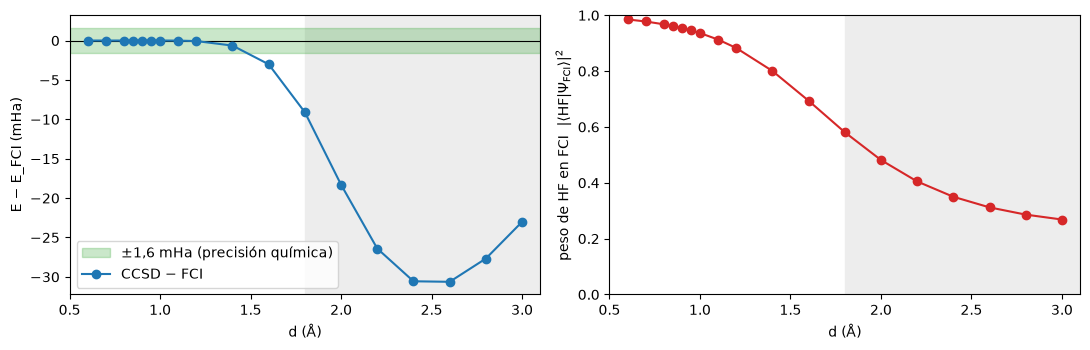

In [4]:
from h4vqe import config
from h4vqe.hamiltonian import validation_table
val = pd.DataFrame(validation_table(config.DISTANCES))
print(f"{len(val)} distancias | máx |<HF|H|HF> − E_HF| = {val.err_hf.abs().max():.1e} Ha | "
      f"máx |E_0(H, sector 2α2β) − E_FCI| = {val.err_fci.abs().max():.1e} Ha | máx |S²| = {val.s2.abs().max():.1e}")
worst = val.loc[val.ccsd_minus_fci_mHa.idxmin()]
print(f"CCSD convergió en todas: {val.ccsd_converged.all()} | peor CCSD − FCI = {worst.ccsd_minus_fci_mHa:.1f} mHa a {worst.d} Å")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for a in (a1, a2):
    a.axvspan(config.STRETCHED_FROM, val.d.max() + 0.1, color="0.93", zorder=0)
    a.set_xlabel("d (Å)"); a.set_xlim(val.d.min() - 0.1, val.d.max() + 0.1)
a1.axhspan(-1e3 * config.CHEM_ACC, 1e3 * config.CHEM_ACC, color="tab:green", alpha=0.25, label="±1,6 mHa (precisión química)")
a1.axhline(0, color="k", lw=0.8)
a1.plot(val.d, val.ccsd_minus_fci_mHa, "o-", label="CCSD − FCI")
a1.set_ylabel("E − E_FCI (mHa)"); a1.legend(loc="lower left")
a2.plot(val.d, val.w_hf, "o-", color="tab:red")
a2.set_ylabel(r"peso de HF en FCI  $|\langle \mathrm{HF}|\Psi_\mathrm{FCI}\rangle|^2$"); a2.set_ylim(0, 1)
plt.tight_layout(); plt.show()

### 1.6 Por qué CCSD falla al estirar

El gráfico de arriba muestra el error de CCSD contra FCI (izquierda) y el peso del determinante HF en el estado exacto, $w_{\rm HF} = \lvert\langle \mathrm{HF}\vert\Psi_{\rm FCI}\rangle\rvert^2$ (derecha). La zona gris es la zona estirada ($d \ge 1{,}8$ Å).

CCSD escribe el estado como $\lvert\Psi_{\rm CC}\rangle = e^{\hat T}\lvert \mathrm{HF}\rangle$, con $\hat T = \hat T_1 + \hat T_2$ (excitaciones simples y dobles), y saca la energía y las amplitudes de ecuaciones **proyectadas**:

$$E_{\rm CCSD} = \langle \mathrm{HF}\rvert\, e^{-\hat T}\hat H e^{\hat T}\,\lvert \mathrm{HF}\rangle, \qquad \langle \Phi_{i}^{a}\rvert\, e^{-\hat T}\hat H e^{\hat T}\,\lvert \mathrm{HF}\rangle = \langle \Phi_{ij}^{ab}\rvert\, e^{-\hat T}\hat H e^{\hat T}\,\lvert \mathrm{HF}\rangle = 0.$$

- **Cerca del equilibrio** (0,9 Å) el estado exacto es casi HF ($w_{\rm HF}$ = 0,95) y CCSD es prácticamente exacto (+0,007 mHa).
- **Al estirar**, cada electrón se queda en su átomo y el estado exacto pasa a ser una mezcla de muchos determinantes con pesos parecidos: $w_{\rm HF}$ baja a 0,58 a 1,8 Å y a 0,27 a 3,0 Å (§1.4). CCSD solo incluye las excitaciones simples y dobles *conectadas*. Las triples y cuádruples aparecen solo como productos de las dobles ($\tfrac12\hat T_2^2$, …), y para 4 electrones FCI equivale a CCSDTQ: eso deja de alcanzar cuando HF ya no domina.
- **CCSD no es variacional.** Como $e^{-\hat T} \neq (e^{\hat T})^\dagger$, $E_{\rm CCSD}$ no es el valor esperado $\langle\Psi\rvert\hat H\lvert\Psi\rangle/\langle\Psi\vert\Psi\rangle$ de ningún estado, y no es una cota superior. Acá cae **por debajo** de FCI a partir de 1,1 Å: −9,1 mHa a 1,8 Å y −30,6 mHa a 2,6 Å, unas 19 veces la precisión química. Quedar por debajo no es "mejor": el error en valor absoluto es grande, y el signo muestra que el método salió de su rango de validez. CCSD convergió en las 18 distancias, así que no es un problema numérico.

**Por qué VQE le puede ganar.** VQE mide el valor esperado de un estado preparado por un circuito, así que para cualquier $\boldsymbol\theta$

$$E(\boldsymbol\theta) = \langle\psi(\boldsymbol\theta)\rvert\,\hat H\,\lvert\psi(\boldsymbol\theta)\rangle = \sum_n \lvert\langle E_n\vert\psi(\boldsymbol\theta)\rangle\rvert^2\, E_n \;\ge\; E_0 .$$

No puede quedar por debajo de FCI, salvo por el ruido estadístico de los shots, que cubre la barra $\pm\sigma$. Entre dos estados medidos, el de energía más baja es el mejor. Esa garantía es la base del argumento de confiabilidad (§6).


## 2 · Lo mínimo que pide la consigna: VQE con UCCSD
La primera versión que corrió de punta a punta fue el VQE "de libro". Sus tres piezas siguen siendo las mismas en la versión final; lo que cambia es cómo resolvemos cada una.

### 2.1 El ciclo variacional

$$\lvert \mathrm{HF}\rangle \xrightarrow{\ U(\boldsymbol\theta)\ } \lvert\psi(\boldsymbol\theta)\rangle \xrightarrow{\ \text{shots}\ } E(\boldsymbol\theta) \pm \sigma \xrightarrow{\ \text{optimizador clásico}\ } \boldsymbol\theta' \;\longrightarrow\; \cdots$$

La consigna deja buscar los parámetros como queramos, incluso sin ruido. Por eso separamos dos etapas:

1. **Buscar $\boldsymbol\theta^*$ sin ruido**, con un simulador numpy exacto del mismo circuito y gradiente analítico (L-BFGS-B).
2. **Medir $E(\boldsymbol\theta^*)$ con shots** en `SamplerV2` de `qiskit_aer`. Esa es la energía que se reporta, con su $\sigma$.

### 2.2 El ansatz UCCSD

UCCSD aplica a HF la exponencial de las excitaciones simples y dobles:

$$\lvert\psi(\boldsymbol\theta)\rangle = e^{\hat T(\boldsymbol\theta) - \hat T^\dagger(\boldsymbol\theta)}\lvert \mathrm{HF}\rangle, \qquad \hat T(\boldsymbol\theta) = \sum_{i\in\text{occ},\,a\in\text{vir}} \theta_i^a\, a_a^\dagger a_i \;+\; \sum_{\substack{i<j\,\in\,\text{occ}\\ a<b\,\in\,\text{vir}}} \theta_{ij}^{ab}\, a_a^\dagger a_b^\dagger a_j a_i .$$

Con 2 electrones $\alpha$ y 2 $\beta$ en 4 orbitales, y conservando $S_z$, hay **8 simples** (4 por espín) y **18 dobles** (16 $\alpha\beta$, 1 $\alpha\alpha$ y 1 $\beta\beta$): 26 parámetros. Como las excitaciones no conmutan entre sí, el circuito usa la **factorización de Trotter**:

$$U(\boldsymbol\theta) = \prod_{r=1}^{n_{\rm rep}}\ \prod_{k=1}^{26} e^{-i\theta_{k,r}\hat G_k}, \qquad \hat G_k = i\big(\hat\tau_k - \hat\tau_k^\dagger\big),$$

donde $\hat\tau_k$ es la excitación $k$ y $n_{\rm rep}$ la cantidad de pasos ("UCCSD ×1", "×2"). Cada $\hat G_k$, escrito con Jordan-Wigner, es una suma de cadenas de Pauli **que conmutan entre sí**, así que `PauliEvolutionGate` implementa cada factor **exactamente**, sin error de Trotter adentro del factor. Además $\hat G_k^3 = \hat G_k$, lo que da una forma cerrada para el simulador numpy:

$$e^{-i\theta\hat G} = I + (\cos\theta - 1)\,\hat G^2 - i\sin\theta\ \hat G .$$

El gradiente sale con un barrido hacia atrás ("adjunto"), al costo de unas dos evaluaciones de la energía:

$$\frac{\partial E}{\partial\theta_k} = 2\,\mathrm{Re}\,\big\langle \lambda_k \big\rvert\, (-i\hat G_k)\, \big\lvert\psi_k\big\rangle, \qquad \lvert\psi_k\rangle = U_k\cdots U_1\lvert \mathrm{HF}\rangle,\quad \langle\lambda_k\rvert = \langle\psi\rvert\hat H\, U_n\cdots U_{k+1}.$$

En la curva, cada distancia arranca del $\boldsymbol\theta^*$ de la anterior (*warm start*).

### 2.3 Medir la energía con shots

Un shot no devuelve una energía: devuelve un bitstring. Por eso juntamos las cadenas de Pauli de $\hat H$ en **grupos** que se pueden medir con un mismo circuito:

$$\hat H = c_0\, I + \sum_{g=1}^{G} \hat O_g, \qquad \hat O_g = \sum_{k\in g} c_k P_k .$$

En un grupo QWC (*qubit-wise commuting*), en cada qubit todas las cadenas tienen la misma letra o $I$. Se mide rotando cada qubit a esa base ($H$ para $X$, $S^\dagger H$ para $Y$), **sin CZ extra**. Cada shot $s$ del grupo $g$ da el bitstring $x_s$ y el valor $o_g(x_s) = \sum_{k\in g} c_k\, (-1)^{\,x_s\cdot\mathrm{sop}(P_k)}$. Con $N_g$ shots por grupo:

$$\hat E = c_0 + \sum_{g} \bar o_g, \qquad \sigma^2 = \sum_{g} \frac{s_g^2}{N_g},$$

donde $\bar o_g$ es la media muestral y $s_g^2$ la varianza muestral de $o_g$ (incluye las covarianzas entre las cadenas del grupo). Los grupos usan shots distintos, así que sus errores son independientes y las varianzas se suman. **La σ sale de las propias muestras**, no de una fórmula fija.

En la versión mínima: 46 grupos QWC (el coloreo de `group_commuting` de Qiskit) y **8 M de shots por punto**, repartidos en dos etapas (piloto + Neyman, ver §4).

### 2.4 Lo mínimo, recalculado

La celda de abajo arma UCCSD ×1 y ×2 en cuatro distancias estiradas y calcula, **sin shots y con el estado exacto** (solo para elegir el ansatz), el error contra FCI, $\langle S^2\rangle$ (0 para el singulete) y el costo: CZ con conectividad total y con qubits en línea, y la probabilidad de que ninguna CZ falle con 0,1 % de error por CZ.


In [5]:
# Lo mínimo: UCCSD ×1 y ×2. Error SIN ruido (con el estado: solo para elegir el ansatz), S² y costo.
import time
from h4vqe.historia import minimum_table
t0 = time.time()
minimo = minimum_table((1.8, 2.0, 2.4, 3.0))
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(minimo)
for a, g in minimo.groupby("ansatz"):
    w = g.loc[g["error sin ruido (mHa)"].idxmax()]
    print(f"{a}: error máx. {w['error sin ruido (mHa)']:.3g} mHa (a {w.d} Å), S² máx. {g['S²'].max():.2f}, "
          f"{w['CZ en línea']} CZ en línea -> P(ninguna CZ falla) = {w['P(ninguna CZ falla), línea']:.2f}")
print(f"({time.time() - t0:.0f} s)")

,ansatz,d,parámetros,CZ todos con todos,CZ en línea,"P(ninguna CZ falla), línea",error sin ruido (mHa),S²,|CCSD − FCI| (mHa)
0,UCCSD ×1,1.8,26,292,806,0.446,3.27,7.47e-06,9.11
1,UCCSD ×1,2,26,292,806,0.446,4.46,3.76e-05,18.3
2,UCCSD ×1,2.4,26,292,806,0.446,1.77,0.626,30.6
3,UCCSD ×1,3,26,292,806,0.446,0.315,0.848,23
4,UCCSD ×2,1.8,52,582,1648,0.192,6.3e-07,4.49e-09,9.11
5,UCCSD ×2,2,52,582,1648,0.192,3.11e-07,6.81e-10,18.3
6,UCCSD ×2,2.4,52,582,1648,0.192,3.35e-07,1.08e-08,30.6
7,UCCSD ×2,3,52,582,1648,0.192,6.53e-08,6.14e-08,23


UCCSD ×1: error máx. 4.46 mHa (a 2.0 Å), S² máx. 0.85, 806 CZ en línea -> P(ninguna CZ falla) = 0.45
UCCSD ×2: error máx. 6.3e-07 mHa (a 1.8 Å), S² máx. 0.00, 1648 CZ en línea -> P(ninguna CZ falla) = 0.19
(5 s)


### 2.5 Qué dio lo mínimo y qué nos dejó pensando

**UCCSD ×1** (26 parámetros, 292 CZ) ya le gana a CCSD en toda la zona estirada, pero **no llega a precisión química** (hasta 4,5 mHa a 2,0 Å) y **rompe el espín**: a 3,0 Å $\langle S^2\rangle$ llega a 0,85 (0 es singulete y 2 es triplete), porque converge a una mezcla de los dos. Duplicar los pasos de Trotter (**UCCSD ×2**, 52 parámetros) llega a FCI con error < 0,001 mHa en toda la curva. Esa fue nuestra primera entrega completa, y en esa corrida (18 distancias, 8 M de shots por punto):

- le ganaba a CCSD en 7 de 7 puntos estirados, con precisión química en los 7 (error máximo medido: 0,74 mHa);
- $\sigma$ = 0,65–0,78 mHa por punto;
- $R_e$ = 0,8932 ± 0,0018 Å con un ajuste cuadrático de 5 puntos, y $D_e$ = 312,95 ± 0,83 mHa;
- la varianza, las simetrías y la comparación con UCCSD ×1 se calculaban con el estado del simulador.

O sea: **la consigna mínima ya estaba cumplida**. Pero al mirar los números aparecieron cinco problemas, y cada uno se convirtió en una hipótesis y en un capítulo de este notebook:

| # | qué observamos | hipótesis | qué probamos | capítulo |
|---|---|---|---|---|
| 1 | UCCSD ×2 usa **582 CZ** (1648 con qubits en línea). Con 0,1 % de error por CZ, menos de 1 de cada 5 shots sale sin error. | No todas las excitaciones aportan lo mismo: alcanza con las que más bajan la energía. | ADAPT-VQE (elige por gradiente) y un ruteo propio con fSWAP para la línea | §3 |
| 2 | Hacen falta **8 M de shots** por punto para $\sigma \approx$ 0,7 mHa, y en 60 repeticiones la dispersión de $z = (E - E_{\rm exacta})/\sigma$ dio **1,16** en lugar de 1. | La varianza depende de cómo se agrupan y reparten los shots. Y el 1,16 puede ser fluctuación estadística de solo 60 repeticiones. | *Sorted insertion*, Neyman en dos etapas, conmutación general y 3600 repeticiones con bootstrap | §4 |
| 3 | $R_e$ salía de un ajuste cuadrático (0,8932 ± 0,0018 Å) y lo comparábamos con FCI **ajustado con el mismo modelo** (0,8964 Å). Esa comparación esconde el error del ajuste: el mínimo FCI verdadero está en 0,8886 Å. | El modelo de ajuste tiene un sesgo propio, porque la curva es asimétrica alrededor del mínimo. | Aplicar cada modelo a FCI en la misma grilla y compararlo con el mínimo FCI exacto | §5 |
| 4 | La confiabilidad se argumentaba con el **estado del simulador**, que en hardware no existe. | La varianza y las simetrías se pueden **medir**, y un eco de Loschmidt resuelve varianzas de $10^{-6}$ Ha². | Varianza por grupos, eco, $N_\alpha$, $N_\beta$, $S^2$ medidos y convergencia con la profundidad | §6 |
| 5 | Con el modelo de ruido, UCCSD ×2 queda **peor que Hartree-Fock**. | Hacen falta unas 100 veces menos CZ. En 8 qubits un ansatz químico no llega; sacando qubits con simetrías, uno nativo de la línea sí. | Tapering 8 → 6 → 5 qubits, ansatz de 16 CZ, mitigación y FakeFez | §7–§9 |

Los cinco se atacaron en paralelo. La versión final del ansatz de la curva es ADAPT con 15 operadores.


## 3 · Problema 1, demasiadas CZ: ADAPT-VQE
**Observación.** UCCSD ×2 llega a FCI, pero con 582 CZ (1648 en línea). Con 0,1 % de error por CZ eso no sirve, y el jurado mira las CZ.

**Hipótesis.** No todas las 26 excitaciones aportan lo mismo. Si agregamos al circuito solo las que más bajan la energía, deberíamos llegar a precisión química con muchas menos CZ.

### 3.1 Cómo funciona ADAPT-VQE

ADAPT-VQE (Grimsley *et al.*, *Nat. Commun.* 10, 3007, 2019) arma el ansatz de a un operador. Arranca de $\lvert\psi^{(0)}\rangle = \lvert \mathrm{HF}\rangle$ y, en el paso $n$, mira cuánto bajaría la energía si agregara cada excitación $\hat A_k = \hat\tau_k - \hat\tau_k^\dagger$ del *pool* (las 26 de UCCSD, que se pueden repetir):

$$g_k = \frac{\partial}{\partial\theta}\,\big\langle\psi^{(n)}\big\rvert\, e^{-\theta\hat A_k}\,\hat H\, e^{\theta\hat A_k}\big\lvert\psi^{(n)}\big\rangle\Big\rvert_{\theta=0} = \big\langle\psi^{(n)}\big\rvert\,[\hat H, \hat A_k]\,\big\lvert\psi^{(n)}\big\rangle .$$

Agrega el de $\lvert g_k\rvert$ máximo, $\lvert\psi^{(n+1)}\rangle = e^{\theta_{n+1}\hat A_{k^*}}\lvert\psi^{(n)}\rangle$, reoptimiza **todos** los $\theta$ y repite. El gradiente es exacto y barato con el simulador (`adapt.py`).

**Una lista común para toda la curva.** En vez de un circuito distinto por distancia, en cada paso elegimos el operador con mayor gradiente en *cualquiera* de las 18 distancias,

$$k^* = \arg\max_k\ \max_{d}\ \lvert g_k(d)\rvert ,$$

y reoptimizamos cada distancia por separado. Así el circuito, y por lo tanto la cantidad de CZ, es el mismo en todos los puntos; solo cambian los $\theta$.

**Dónde cortar sin usar FCI.** La varianza de la energía,

$$\mathrm{Var}(\hat H) = \langle\hat H^2\rangle - \langle\hat H\rangle^2 \;\ge\; 0,$$

vale 0 solo en un autoestado, así que mide qué tan lejos estamos de uno sin conocer $E_0$. La tabla de abajo la calcula con el estado del simulador (solo para elegir el corte; en §6 la **medimos** con shots) al ir agregando operadores en el orden en que ADAPT los eligió. El error contra FCI aparece solo como comprobación.


In [6]:
# ADAPT al ir agregando operadores (en el orden en que los eligió), en las 18 distancias.
# Var(H) no usa FCI: es el criterio de corte. El error contra FCI es solo comprobación.
from h4vqe.adapt import ADAPT_FERMIONIC
from h4vqe.historia import adapt_convergence, exc_label
t0 = time.time()
conv_adapt = adapt_convergence(config.DISTANCES, ks=(8, 10, 12, 13, 15))
by_k, by_k_est = conv_adapt.groupby("operadores"), conv_adapt[conv_adapt.d >= config.STRETCHED_FROM].groupby("operadores")
res_adapt = pd.DataFrame({
    "CZ (todos con todos)": by_k.CZ.first(),
    "Var(H) máx., d ≥ 1,8 Å (Ha²)": by_k_est["Var(H) (Ha²)"].max(),
    "Var(H) máx., toda la curva (Ha²)": by_k["Var(H) (Ha²)"].max(),
    "error máx., toda la curva (mHa)": by_k["error (mHa)"].max(),
    "S² máx.": by_k["S²"].max()})
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(res_adapt)
print("lista final (15): " + " | ".join(f"{i + 1}: {exc_label(e)}" for i, e in enumerate(ADAPT_FERMIONIC)))
print(f"({time.time() - t0:.0f} s)")

,CZ (todos con todos),"Var(H) máx., d ≥ 1,8 Å (Ha²)","Var(H) máx., toda la curva (Ha²)","error máx., toda la curva (mHa)",S² máx.
operadores,,,,,
8,134,0.00549,0.00624,7.4,0.141
10,162,0.00443,0.00443,5.22,9.84e-11
12,169,0.00315,0.00315,3.71,0.0128
13,185,0.000261,0.000475,0.592,0.0132
15,194,0.000187,0.000475,0.382,0.0166


lista final (15): 1: 1α 1β → 3α 3β | 2: 0α 1β → 3α 2β | 3: 0α 0β → 2α 2β | 4: 1α 0β → 2α 3β | 5: 1α 1β → 2α 2β | 6: 0α 1β → 2α 3β | 7: 0α 0β → 3α 3β | 8: 1α 0β → 3α 2β | 9: 0α 1α → 2α 3α | 10: 0β 1β → 2β 3β | 11: 0α → 2α | 12: 0β → 2β | 13: 1β → 3β | 14: 1α → 3α | 15: 0α 1β → 2α 3β
(8 s)


### 3.2 Qué dio ADAPT y cómo lo cerramos

**El corte en 13 operadores.** Los primeros 8 son dobles $\alpha\beta$ (un electrón $\alpha$ y uno $\beta$ que saltan juntos), después vienen las dos dobles del mismo espín y recién ahí las simples. En la zona estirada, la varianza máxima cae **12 veces** al pasar de 12 a 13 operadores (de ~3·10⁻³ a ~3·10⁻⁴ Ha², tabla de arriba), y el error máximo de la curva, de 3,7 a 0,6 mHa. Cerca del equilibrio la varianza ya era chica y casi no cambia (con 13 operadores, el máximo de toda la curva queda a 1,2 Å, con 0,3 mHa de error). La primera lista cortó ahí: **13 operadores y 185 CZ**, contra 582 de UCCSD ×2.

**Completar los pares de espín.** Entre los 13 operadores, ADAPT eligió las simples $0_\alpha \to 2_\alpha$ y $1_\beta \to 3_\beta$, pero no sus pares $0_\beta \to 2_\beta$ y $1_\alpha \to 3_\alpha$. El estado rompía un poco el espín ($\langle S^2\rangle$ hasta 0,013). Agregamos esas dos simples **al lado de su pareja** (`ADAPT_FERMIONIC`, 15 operadores): el error máximo baja de 0,59 a **0,38 mHa** en toda la curva y $\langle S^2\rangle$ a ≤ 6,5·10⁻³, por 9 CZ más (194 en total). Corriendo ADAPT con dos operadores más, el algoritmo elige justamente esas dos simples: la corrección coincide con lo que pide el gradiente.

**Dos arranques en la optimización.** Solo con *warm start* (el $\boldsymbol\theta^*$ de la distancia anterior), el optimizador caía en mínimos malos en algunos puntos: 2 mHa a 2,8 Å con la lista de 15. Ahora `optimize_params` prueba siempre el *warm start* **y** $\boldsymbol\theta = 0$ ($\lvert \mathrm{HF}\rangle$), y se queda con la energía más baja. Como el método es variacional, la más baja es siempre la mejor.

### 3.3 Qubits en línea: ruteo propio con fSWAP
**Observación.** Con qubits en línea (como en el modelo de ruido y en muchos chips) el transpiler de Qiskit agrega SWAP y multiplica las CZ ~2,8×: ADAPT pasa de 194 a ~530.

**Hipótesis.** Una excitación fermiónica solo necesita que sus modos estén **contiguos**. Si movemos los modos con *fermionic SWAP* en lugar de SWAP comunes, el signo de Jordan-Wigner viaja con el modo y no hay que deshacer nada.

$$\mathrm{fSWAP}_{j,j+1} = \begin{pmatrix} 1&0&0&0\\ 0&0&1&0\\ 0&1&0&0\\ 0&0&0&-1 \end{pmatrix} = \mathrm{CZ}\cdot\mathrm{SWAP} .$$

Intercambia dos modos e incluye el signo $-1$ cuando los dos están ocupados, que es justo lo que pide el anticonmutador. Es un iSWAP salvo fases de un qubit, así que cuesta **2 CZ**, contra 3 de un SWAP común.

Nuestro ruteo (`h4vqe/routing.py`, inspirado en las redes fSWAP de Kivlichan *et al.*, 2018, y en Co-ADAPT de Ramôa *et al.*, 2026):

1. Antes de cada excitación junta sus modos en qubits **contiguos** con fSWAP.
2. **No deshace** la permutación: el orden de los modos se sigue de forma clásica.
3. Aplica cada doble con un circuito pensado para la línea (18 CZ, casi todas entre vecinos) y mide la energía con $\hat H$ escrito en el **orden final** de modos.

Los $\boldsymbol\theta$ son los mismos (las fSWAP solo reetiquetan modos), y la energía coincide hasta $10^{-15}$ (`tests/test_routing.py`). El orden inicial se eligió entre 72 candidatos: $[3_\alpha\, 3_\beta\, 1_\alpha\, 1_\beta\, 2_\alpha\, 2_\beta\, 0_\alpha\, 0_\beta]$. Resultado: **530 → 378 CZ en línea** (−29 %). El costo: $\hat H$ en el orden final se agrupa peor (69 grupos QWC contra 37), así que necesita más shots para la misma σ. Por eso la curva central se mide con el circuito sin rutear y $\hat H$ original (es el mismo estado), y el ruteado se usa para contar CZ en línea y para simular con ruido.

| ansatz | parámetros | CZ (todos con todos) | CZ (línea) | error máx. sin ruido | $\langle S^2\rangle$ máx. |
|---|---|---|---|---|---|
| UCCSD ×1 | 26 | 292 | 806 | 4,5 mHa (2,0 Å) | 0,85 |
| UCCSD ×2 (lo mínimo) | 52 | 582 | 1648 | < 0,001 mHa | ≈ 0 |
| ADAPT, 13 operadores | 13 | 185 | 526 (transpiler) / 370 (fSWAP) | 0,59 mHa (2,0 Å) | 0,013 |
| **ADAPT + pares de espín, 15 operadores (la curva)** | **15** | **194** | **~530 (transpiler) / 378 (fSWAP)** | **0,38 mHa** | **6,5·10⁻³** |

**Por qué funcionó.** En H₄ la correlación la llevan casi toda las dobles $\alpha\beta$ entre los dos orbitales ocupados y los dos vacíos. ADAPT las encuentra primero porque son las de mayor gradiente, y descarta las que UCCSD ×2 incluye "por las dudas". Bajar de 52 a 15 parámetros también hace la optimización más rápida y estable.

### 3.4 Qué no funcionó

- **Umbral de gradiente de 10⁻⁴** como criterio de parada: ADAPT se frena en mesetas a 1,6, 2,8 y 3,0 Å con 0,6–2 mHa de error, y después el gradiente vuelve a crecer. Con 10⁻⁵ llega a FCI en toda la curva. Por eso cortamos con la varianza.
- **Agregar las simples de espín al final de la lista** (y no al lado de su pareja), con el *warm start* entre distancias: cae en un mínimo malo (2,5 mHa, $\langle S^2\rangle$ = 0,52).
- **Reordenar los operadores** para necesitar menos fSWAP (314 CZ en línea): el error sube a 5,2 mHa. El orden de los operadores cambia el ansatz.
- **Co-ADAPT** (elegir cada operador por gradiente dividido por su costo en línea): necesita 16–19 operadores para precisión química y termina en ~460–470 CZ en línea. En H₄ casi todas las dobles hacen falta, así que penalizar por costo solo agrega operadores.
- **Circuitos explícitos de excitación sin ruteo propio** (escalera de CNOT + RY multicontrolada): exactos, pero el transpiler los rutea peor que `PauliEvolutionGate` (705 contra 526 CZ en línea).
- **Probar layouts y semillas del transpiler**: el mejor resultado fue ~515 CZ, contra ~526 por defecto.
- **Pool QEB** (excitaciones de qubit, sin cadenas Z): 159 CZ con conectividad total, pero ~451 en línea, peor que el ruteo fSWAP, y rompe más el espín ($\langle S^2\rangle$ hasta 0,074). Queda en la comparación de ansätze (§11).

La celda de abajo verifica el ansatz de la curva a 2,0 Å: $\hat H$ contra PySCF, que el circuito de Qiskit y el simulador numpy den el mismo estado, y las CZ en las tres variantes.


In [7]:
import importlib
import h4vqe
for mod in ["config", "hamiltonian", "ansatz", "optimize", "estimator", "adapt", "routing", "analysis",
            "pipeline", "reduction", "noise", "mitigation", "hardware", "geometry", "scaling", "historia"]:
    importlib.reload(importlib.import_module("h4vqe." + mod))
from qiskit.quantum_info import Statevector
from h4vqe import config
from h4vqe.hamiltonian import molecule, qubit_hamiltonian
from h4vqe.ansatz import build_ansatz, cz_count
from h4vqe.pipeline import curve_ansatz_kwargs, line_cz_fswap

m = molecule(2.0); H = qubit_hamiltonian(m)
ans = build_ansatz(m, **curve_ansatz_kwargs())   # config.ANSATZ
e_hf = Statevector(ans.fast.psi0).expectation_value(H).real
print(f"términos de Pauli: {len(H)} | qubits: {H.num_qubits}")
print(f"E_HF (PySCF) = {m['e_hf']:.8f}   <HF|H|HF> = {e_hf:.8f}")
print(f"E_FCI = {m['e_fci']:.8f}   E_CCSD = {m['e_ccsd']:.8f}  (CCSD − FCI = {1e3*(m['e_ccsd']-m['e_fci']):+.2f} mHa)")
x = np.random.default_rng(0).normal(0, .2, ans.num_parameters)
fid = abs(np.vdot(Statevector(ans.circuit.assign_parameters(x)).data, ans.fast.state(x)))**2
print(f"fidelidad circuito Qiskit vs simulador numpy = {fid:.12f}")
print(f"ansatz: {config.ANSATZ} | parámetros: {ans.num_parameters} | CZ: {cz_count(ans.circuit)} (todos con todos), "
      f"{cz_count(ans.circuit, 'line')} (línea, transpiler), {line_cz_fswap(m, ans)} (línea, ruteo fSWAP)")

términos de Pauli: 185 | qubits: 8
E_HF (PySCF) = -1.57561648   <HF|H|HF> = -1.57561648
E_FCI = -1.89778065   E_CCSD = -1.91608610  (CCSD − FCI = -18.31 mHa)
fidelidad circuito Qiskit vs simulador numpy = 1.000000000000
ansatz: adapt | parámetros: 15 | CZ: 194 (todos con todos), 543 (línea, transpiler), 378 (línea, ruteo fSWAP)


## 4 · Problema 2, demasiados shots y una σ dudosa
**Observación.** En lo mínimo, 8 M de shots por punto daban $\sigma \approx$ 0,7 mHa con 46 grupos QWC. Y al repetir 60 veces la medición del mismo circuito, la dispersión de $z = (E - E_{\rm exacta})/\sigma$ dio 1,16 en lugar de 1: o la $\sigma$ subestimaba el error, o era mala suerte.

**Hipótesis.** (a) La varianza total depende de **cómo se agrupan** los términos y de **cómo se reparten** los shots, así que se puede bajar sin tocar el circuito. (b) Con 60 repeticiones, un 1,16 puede ser pura fluctuación estadística.

### 4.1 Cuántos shots hacen falta: $\sigma = \sqrt{K/N}$

Si el grupo $g$ recibe $N_g = f_g N$ shots y su observable tiene varianza $V_g = \langle\hat O_g^2\rangle - \langle\hat O_g\rangle^2$ por shot,

$$\sigma^2 = \sum_g \frac{V_g}{N_g}.$$

Minimizar $\sigma^2$ con $\sum_g N_g = N$ fijo (multiplicadores de Lagrange) da el **reparto de Neyman**,

$$N_g = N\,\frac{\sqrt{V_g}}{\sum_h \sqrt{V_h}} \qquad\Longrightarrow\qquad \sigma^2_{\min} = \frac{\big(\sum_g \sqrt{V_g}\big)^2}{N} \equiv \frac{K}{N}.$$

La $\sigma$ baja como $1/\sqrt N$, y la constante $K$ resume qué tan buena es una estrategia de medición: **para la misma σ, los shots son proporcionales a $K$**. Como las $V_g$ no se conocen de antemano, medimos en **dos etapas**: un piloto con el 10 % de los shots y $N_g \propto \sum_{k\in g}\lvert c_k\rvert$ estima las $V_g$, y el resto se reparte con Neyman. Las muestras de las dos etapas se juntan.

### 4.2 Agrupar mejor: *sorted insertion* y conmutación general

- **Coloreo QWC** (lo mínimo): `group_commuting` de Qiskit arma 46 grupos.
- ***Sorted insertion*** (Crawford *et al.*, *Quantum* 5, 385, 2021): se recorren los términos por $\lvert c_k\rvert$ decreciente, y cada uno va al primer grupo compatible. Quedan 37 grupos, y los términos grandes quedan juntos. Sus covarianzas, muchas veces negativas, se compensan dentro del grupo y bajan $V_g$.
- **Conmutación general (GC)**: términos que conmutan, aunque no qubit a qubit. Quedan 9 grupos. Cada uno se diagonaliza con un Clifford $C$: se toman generadores independientes del grupo (en $\mathrm{GF}(2)$), se arma el estado estabilizador $C\lvert 0\rangle$ que fijan y se mide en $Z$ después de $C^\dagger$, porque $C^\dagger P C = \pm Z\cdots$ para todo $P$ del grupo. **Agrega CZ** al circuito medido.

La celda de abajo calcula $K$ con el estado del ansatz de la curva para las cuatro combinaciones. Es una cuenta para **planificar**: las $\sigma$ que se reportan salen siempre de las muestras.


In [8]:
# Shots para σ = 0,5 mHa con cada forma de agrupar (estado del ansatz de la curva; Neyman ideal).
# Solo para PLANIFICAR: las σ reportadas salen siempre de las muestras.
from h4vqe.historia import shots_table, GROUPINGS
t0 = time.time()
shots_tab = shots_table((0.9, 1.8, 2.4, 3.0))
tab = shots_tab.pivot_table(index="agrupamiento", columns="d", values="shots para σ = 0,5 mHa (M)")
tab = tab.loc[[name for _, _, name in GROUPINGS]].round(1)
tab.columns = [f"shots (M) a {d:g} Å" for d in tab.columns]
tab.insert(0, "grupos", shots_tab.groupby("agrupamiento").grupos.max())
display(tab)
s8 = shots_tab.pivot_table(index="agrupamiento", columns="d", values="σ con 8 M de shots (mHa)")
r = tab.iloc[0, 1:] / tab.iloc[1, 1:]
print(f"coloreo / sorted insertion (QWC): {r.min():.2f}–{r.max():.2f}× más shots | σ con 8 M de shots en la zona estirada: "
      f"{s8.loc[GROUPINGS[0][2], [1.8, 2.4, 3.0]].min():.2f}–{s8.loc[GROUPINGS[0][2], [1.8, 2.4, 3.0]].max():.2f} mHa (lo mínimo) -> "
      f"{s8.loc[GROUPINGS[1][2], [1.8, 2.4, 3.0]].min():.2f}–{s8.loc[GROUPINGS[1][2], [1.8, 2.4, 3.0]].max():.2f} mHa (la curva)")
print(f"({time.time() - t0:.0f} s)")

,grupos,shots (M) a 0.9 Å,shots (M) a 1.8 Å,shots (M) a 2.4 Å,shots (M) a 3 Å
agrupamiento,,,,,
"QWC, coloreo (lo mínimo)",46,17.6,16.5,15.0,15.0
"QWC, sorted insertion (la curva)",39,11.0,9.2,8.0,8.1
"GC, coloreo",9,5.3,7.2,5.8,4.8
"GC, sorted insertion",10,4.3,4.3,3.3,2.4


coloreo / sorted insertion (QWC): 1.60–1.88× más shots | σ con 8 M de shots en la zona estirada: 0.68–0.72 mHa (lo mínimo) -> 0.50–0.54 mHa (la curva)
(1 s)


**Qué dio.** *Sorted insertion* necesita **1,6–1,9 veces menos shots** que el coloreo para la misma $\sigma$, sin cambiar el circuito. Con los mismos 8 M de shots, la $\sigma$ predicha baja de ~0,70 a ~0,52 mHa en la zona estirada, que es lo que después se mide en la curva (§5). GC necesita otras 2–3 veces menos shots, pero agrega de 4 a 23 CZ por grupo (de 4 a 77 con qubits en línea).

**Decisión.** La curva se mide con **QWC + *sorted insertion* + dos etapas**, con 8 M de shots por punto ($\sigma$ = 0,50–0,60 mHa). Con ruido, cada CZ extra cuesta precisión, así que QWC además permite post-seleccionar por $N_\alpha$ y $N_\beta$ en los grupos que miden solo $Z$ (§8). GC queda como opción para una simulación sin ruido: 4 M de shots darían la misma $\sigma$.

**Por qué funcionó.** $K = (\sum_g \sqrt{V_g})^2$ crece con la cantidad de grupos y con la varianza de cada uno. *Sorted insertion* arma menos grupos y pone juntos los términos de coeficiente grande. Como dentro de un grupo se miden en el mismo shot, sus covarianzas entran en $V_g$ y en parte se compensan. Con 20 % menos grupos, $K$ baja casi a la mitad.

### 4.3 ¿La barra de error es honesta? Calibración de σ

Repetimos la medición del **mismo circuito** con semillas independientes y miramos

$$z = \frac{E - E_{\rm exacta}}{\sigma}, \qquad E_{\rm exacta} = \langle\psi\rvert\hat H\lvert\psi\rangle \text{ del circuito medido}.$$

Si $\sigma$ está bien estimada, $z \sim \mathcal N(0,1)$. Hicimos 500 repeticiones por configuración (300 para $\sum\lvert c\rvert$), a 2,0 y 3,0 Å: **17,8 mil millones de shots** en total (`scripts/calib_sigma.py`, ~35 min en 12 núcleos, por eso no se recalcula acá). También calculamos $\sigma$ por **bootstrap**: re-muestrear los shots de cada grupo y recalcular $E$, sin suponer normalidad.

| configuración | d (Å) | σ media (mHa) | σ predicha $\sqrt{K/N}$ | media de z | std de z [IC 95 %] | σ_boot / σ | \|z\| > 2 |
|---|---|---|---|---|---|---|---|
| QWC, 8 M, dos etapas | 2,0 | 0,519 | 0,519 | −0,02 ± 0,05 | 1,01 [0,95; 1,07] | 0,997 | 5,0 % |
| QWC, 8 M, dos etapas | 3,0 | 0,500 | 0,500 | +0,04 ± 0,05 | 1,00 [0,94; 1,06] | 0,998 | 4,4 % |
| QWC, 1 M, dos etapas | 2,0 | 1,467 | 1,467 | +0,04 ± 0,05 | 1,03 [0,97; 1,09] | 0,999 | 4,8 % |
| QWC, 1 M, dos etapas | 3,0 | 1,413 | 1,413 | −0,02 ± 0,05 | 1,04 [0,98; 1,11] | 0,999 | 6,2 % |
| QWC, 8 M, Σ\|c\| | 2,0 | 0,679 | 0,679 | −0,16 ± 0,06 | 0,98 [0,91; 1,06] | 0,997 | 5,3 % |
| QWC, 8 M, Σ\|c\| | 3,0 | 0,681 | 0,681 | −0,02 ± 0,06 | 1,03 [0,95; 1,12] | 1,001 | 5,0 % |
| GC, 4 M, dos etapas | 2,0 | 0,507 | 0,507 | +0,01 ± 0,04 | 0,96 [0,91; 1,03] | 0,996 | 3,4 % |
| GC, 4 M, dos etapas | 3,0 | 0,424 | 0,424 | +0,01 ± 0,05 | 1,04 [0,98; 1,11] | 0,994 | 5,8 % |

- **$\sigma$ está calibrada.** La dispersión de $z$ es compatible con 1 en las 8 configuraciones. Con las 3600 repeticiones juntas: media de $z$ = −0,006 ± 0,017, dispersión = 1,011 [0,988; 1,035], $\lvert z\rvert > 2$ en el 5,0 % de los casos (lo normal es 4,6 %), 11 casos con $\lvert z\rvert > 3$ (se esperan ~10) y la prueba KS contra $\mathcal N(0,1)$ da $p$ = 0,78. No hay correlación entre repeticiones seguidas ($\lvert r\rvert$ < 0,12).
- **$\sigma = \sqrt{K/N}$ predice la $\sigma$ medida hasta el tercer dígito**, y de 1 M a 8 M de shots la $\sigma$ baja en $\sqrt 8$ = 2,83 (medido: 2,83). Por eso la usamos para planificar.
- **El 1,16 de antes era ruido estadístico** (hipótesis b confirmada): con 60 repeticiones, aunque $\sigma$ sea exacta, la dispersión de $z$ cae en [0,82; 1,18] el 95 % de las veces.
- **El bootstrap coincide** con la $\sigma$ analítica dentro de 0,7 %.
- La media de $z$ = −0,16 ± 0,06 ($\sum\lvert c\rvert$ a 2,0 Å) es un desvío de 2,7σ entre unas 18 pruebas, algo que por azar pasa ~10 % de las veces. El mismo circuito medido en dos etapas da −0,02 ± 0,05.

### 4.4 Semillas: el error que sí encontramos

Al principio cada grupo usaba semillas consecutivas de Aer, y vimos **errores correlacionados entre grupos**, con desvíos de 4σ: la $\sigma$ quedaba subestimada. Ahora cada grupo y cada etapa tienen su propia semilla, derivada con `numpy.random.SeedSequence`. Más tarde vimos ~3σ seguidos en 0,7–0,9 Å con 200 k shots: las 18 distancias usaban **la misma** semilla, y el ruido de shots quedaba correlacionado entre puntos vecinos. Eso sesga el ajuste de $R_e$ y achica su $\sigma$ de Monte Carlo, que supone errores independientes. Ahora cada distancia y cada diagnóstico tienen su propia semilla.

### 4.5 Qué no funcionó

- **Neyman con las varianzas del estado HF**: 11 veces peor que el piloto. HF es un estado de la base computacional, así que da varianza cero a todos los grupos que miden solo $Z$ y les asigna muy pocos shots.
- **Reusar shots entre grupos** (cada base QWC también estima los Pauli compatibles de otros grupos): sobre el coloreo ganaba 1,4–2,3×, pero sobre *sorted insertion* casi no suma, y en la zona estirada empeora un poco porque el promedio ignora las covarianzas. No lo implementamos.
- **Calibrar con 60 repeticiones**: no alcanza para distinguir 1,16 de 1.

**Limitación.** La calibración es **sin ruido**: verifica la estadística de los shots, no el sesgo del ruido de compuertas, que se trata en §7–§8.


## 5 · Resultado central: la curva, $R_e$ y $D_e$
Con las mejoras de §3 y §4, el flujo para cada distancia es:

$$d \;\to\; \hat H(d)\ \text{(PySCF + Jordan-Wigner)} \;\to\; \boldsymbol\theta^*(d) = \arg\min_{\boldsymbol\theta} E(\boldsymbol\theta)\ \text{(sin ruido; warm start y } \boldsymbol\theta = 0\text{)} \;\to\; E(d) \pm \sigma\ \text{(8 M shots, SamplerV2)} .$$

- **Ansatz:** ADAPT con 15 operadores, el mismo circuito en las 18 distancias (194 CZ con conectividad total).
- **Medición:** 37 grupos QWC (*sorted insertion*), piloto + Neyman, semilla propia por punto.
- **Tabla** (lo que pide la consigna): por punto, la energía medida `E_vqe`, su error `sigma_mHa`, los `shots` y las CZ. Hay tres conteos de CZ: todos con todos (`cz_all`), en línea con el transpiler de Qiskit (`cz_line`) y en línea con nuestro ruteo fSWAP (`cz_line_fswap`, §3.3). Después vienen las referencias clásicas (`E_fci`, `E_ccsd`), los errores en mHa y los dos criterios: `beats_ccsd`, $\lvert E_{\rm VQE} - E_{\rm FCI}\rvert + \sigma < \lvert E_{\rm CCSD} - E_{\rm FCI}\rvert$, que solo se evalúa para $d \ge 1{,}8$ Å, y `chem_acc`, error < 1,6 mHa.

La $\sigma$ es **solo estadística** (la dispersión de los shots, calibrada en §4.3). Sin ruido de compuertas no hay otro sesgo que el del ansatz, ≤ 0,38 mHa (§3).


In [9]:
from h4vqe.pipeline import run_curve
QUICK = False   # True: 4 distancias y menos shots, para probar rápido
dists = [0.7, 0.9, 1.8, 3.0] if QUICK else config.DISTANCES
shots = 400_000 if QUICK else config.SHOTS_PER_POINT
t0 = time.time()
rows, ctxs = run_curve(dists, shots=shots)
print(f"total: {time.time()-t0:.0f} s")

d=0.60 Å  E=-1.960988 ± 0.59 mHa  |E-FCI|=0.79 mHa  |CCSD-FCI|=0.00 mHa  CZ=194  (2s)


d=0.70 Å  E=-2.105850 ± 0.58 mHa  |E-FCI|=1.15 mHa  |CCSD-FCI|=0.00 mHa  CZ=194  (3s)


d=0.80 Å  E=-2.167708 ± 0.58 mHa  |E-FCI|=0.15 mHa  |CCSD-FCI|=0.00 mHa  CZ=194  (3s)


d=0.85 Å  E=-2.177530 ± 0.55 mHa  |E-FCI|=0.78 mHa  |CCSD-FCI|=0.01 mHa  CZ=194  (3s)


d=0.90 Å  E=-2.179990 ± 0.59 mHa  |E-FCI|=0.33 mHa  |CCSD-FCI|=0.01 mHa  CZ=194  (3s)


d=0.95 Å  E=-2.176401 ± 0.60 mHa  |E-FCI|=0.62 mHa  |CCSD-FCI|=0.01 mHa  CZ=194  (3s)


... (8 outputs left out)

d=2.40 Å  E=-1.874095 ± 0.50 mHa  |E-FCI|=0.56 mHa  |CCSD-FCI|=30.56 mHa  CZ=194  (4s)


d=2.60 Å  E=-1.870658 ± 0.50 mHa  |E-FCI|=0.19 mHa  |CCSD-FCI|=30.63 mHa  CZ=194  (4s)


d=2.80 Å  E=-1.868846 ± 0.51 mHa  |E-FCI|=0.50 mHa  |CCSD-FCI|=27.67 mHa  CZ=194  (3s)


d=3.00 Å  E=-1.867339 ± 0.51 mHa  |E-FCI|=0.05 mHa  |CCSD-FCI|=23.01 mHa  CZ=194  (3s)
total: 60 s


In [10]:
from h4vqe.analysis import results_table
df = results_table(rows)
cols = ["d","E_vqe","sigma_mHa","shots","cz_all","cz_line","cz_line_fswap","E_fci","E_ccsd","err_vqe_mHa","err_ccsd_mHa","beats_ccsd","chem_acc"]
pd.set_option("display.float_format", lambda v: f"{v:.6f}")
df[cols]

,d,E_vqe,sigma_mHa,shots,cz_all,cz_line,cz_line_fswap,E_fci,E_ccsd,err_vqe_mHa,err_ccsd_mHa,beats_ccsd,chem_acc
0,0.600000,-1.960988,0.588574,7999980,194,543,378,-1.960194,-1.960189,0.794317,0.004758,NaN,True
1,0.700000,-2.105850,0.581550,7999978,194,543,378,-2.106997,-2.106993,1.146774,0.004243,NaN,True
2,0.800000,-2.167708,0.580017,7999978,194,543,378,-2.167561,-2.167556,0.147764,0.004957,NaN,True
3,0.850000,-2.177530,0.548940,7999982,194,543,378,-2.178314,-2.178308,0.783825,0.005956,NaN,True
4,0.900000,-2.179990,0.589954,7999983,194,543,378,-2.180317,-2.180309,0.327018,0.007204,NaN,True
5,0.950000,-2.176401,0.595121,7999980,194,543,378,-2.175780,-2.175772,0.620517,0.008205,NaN,True
6,1.000000,-2.165495,0.594685,7999979,194,543,378,-2.166387,-2.166380,0.892498,0.007928,NaN,True
7,1.100000,-2.138347,0.592905,7999981,194,543,378,-2.137971,-2.137975,0.376736,0.004921,NaN,True
8,1.200000,-2.102567,0.593412,7999981,194,543,378,-2.102608,-2.102671,0.041191,0.062659,NaN,True
9,1.400000,-2.027987,0.579450,7999983,194,543,378,-2.029070,-2.029707,1.083653,0.636448,NaN,True


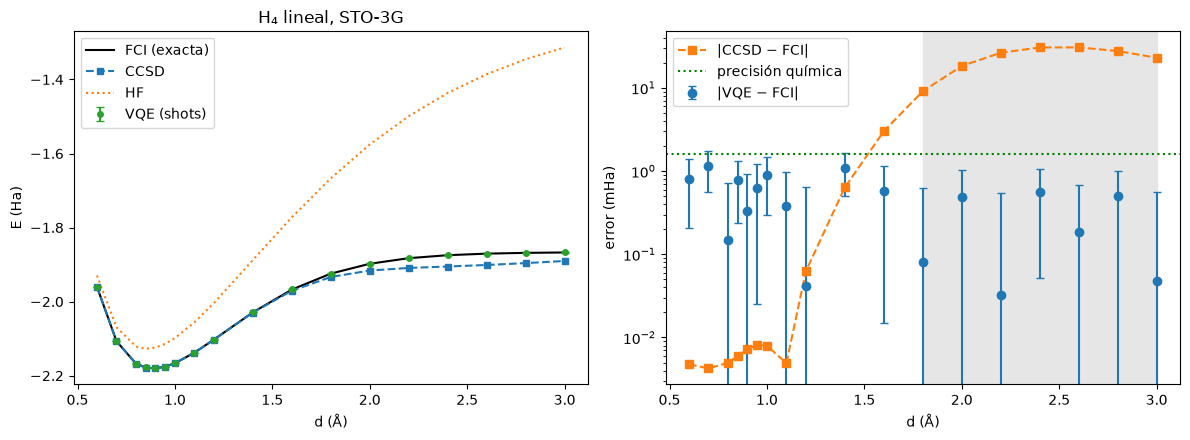

In [11]:
from h4vqe.analysis import plot_curve
fig = plot_curve(df, "curva_h4.png")

### 5.1 $R_e$ y $D_e$, y el problema 3: el ajuste tenía sesgo
El mínimo sale de ajustar un polinomio a las energías medidas cerca de 0,9 Å, pesando cada punto con $1/\sigma_i$:

$$E(d) \approx \sum_{j=0}^{n} a_j\, d^{\,j}, \qquad R_e:\ E'(R_e) = 0,\ E''(R_e) > 0, \qquad D_e = E(3{,}0\ \text{Å}) - E(R_e), \qquad \sigma_{D_e} = \sqrt{\sigma_{3,0}^2 + \sigma_{E(R_e)}^2}.$$

La incertidumbre sale por **Monte Carlo**: re-muestreamos cada energía con su $\sigma$ ($E_i \to E_i + \mathcal N(0, \sigma_i^2)$), volvemos a ajustar (incluida la elección de la ventana de puntos) y tomamos la dispersión de $R_e$ y de $E(R_e)$ en 2000 réplicas.

**Observación.** En lo mínimo usábamos un cuadrático en 5 puntos y comparábamos con FCI *ajustado con el mismo modelo*. Así el error del ajuste se cancela en la comparación y no se ve.

**Hipótesis.** La curva es asimétrica (sube más rápido hacia la izquierda), y una parábola corre el mínimo hacia afuera. Para medir ese sesgo sin mirar el VQE, aplicamos cada modelo a las energías **FCI de la misma grilla** y lo comparamos con el **mínimo FCI verdadero**, que sacamos minimizando PySCF en $d$ ($R_e$ = 0,8886 Å). Esa diferencia es el sesgo del *método de ajuste*. La celda de abajo prueba 7 modelos (columnas `sesgo R_e` y `sesgo E_min`):

- el cuadrático en 5 puntos (el de lo mínimo) tiene **+7,8 mÅ** de sesgo en $R_e$, unas 3σ: ese era el problema;
- el cúbico en 7 puntos casi no tiene sesgo en $R_e$, pero sí en la energía del mínimo (−575 µHa), que entra en $D_e$;
- el spline no tiene sesgo, pero pasa por cada punto con su ruido y queda 3 veces más ruidoso;
- **el cuártico en 7 puntos (0,7–1,1 Å)** es el único con sesgo chico en $R_e$ **y** en $E_{\min}$ a la vez (−0,9 mÅ y −16 µHa), con una $\sigma$ de las más chicas. **Lo elegimos.**

La elección tampoco depende de FCI: el cuártico en 7 puntos recupera el mínimo de una curva de Morse conocida en esta misma grilla, con error < 2 mÅ en $R_e$ y < 0,1 mHa en $E_{\min}$ (`tests/test_analysis.py`). La comparación con FCI solo elige un método numérico; no corrige ningún resultado.


In [12]:
from h4vqe.analysis import fit_minimum, dissociation_energy, fci_minimum, compare_fits, DEFAULT_FIT
# Referencia: mínimo FCI verdadero (minimizando PySCF en d), NO un ajuste sobre la grilla.
ref = fci_minimum()
far = df[df.d == df.d.max()].iloc[0]
De_fci = far.E_fci - ref["E_min"]
# Comparación de modelos. "sesgo" = modelo aplicado a FCI en la misma grilla − mínimo verdadero:
# mide el error del método de ajuste, sin mirar el VQE. Con eso elegimos el modelo.
cmp = compare_fits(df, ref)
display(cmp.round(3))
fit = fit_minimum(df.d, df.E_vqe, df.sigma, DEFAULT_FIT)
de = dissociation_energy(far.E_vqe, far.sigma, fit)
print(f"modelo: {fit['model']} sobre d = {fit['fit_points']}")
print(f"R_e (VQE) = {fit['R_e']:.4f} ± {fit['R_e_sigma']:.4f} Å   | R_e (FCI) = {ref['R_e']:.4f} Å   "
      f"→ diferencia {1e3*(fit['R_e']-ref['R_e']):+.1f} mÅ = {(fit['R_e']-ref['R_e'])/fit['R_e_sigma']:+.1f} σ")
print(f"D_e (VQE) = {1e3*de['D_e']:.2f} ± {1e3*de['D_e_sigma']:.2f} mHa | D_e (FCI) = {1e3*De_fci:.2f} mHa  "
      f"→ diferencia {1e3*(de['D_e']-De_fci):+.2f} mHa = {(de['D_e']-De_fci)/de['D_e_sigma']:+.1f} σ")
s = df[df.d >= config.STRETCHED_FROM]
print(f"zona estirada: le gana a CCSD en {int(s.beats_ccsd.sum())}/{len(s)} puntos; precisión química en {int(s.chem_acc.sum())}/{len(s)}")

,modelo,n_puntos,R_e (Å),σ R_e (mÅ),D_e (mHa),σ D_e (mHa),sesgo R_e (mÅ),sesgo E_min (µHa),R_e − R_e(FCI) (mÅ),D_e − D_e(FCI) (mHa)
0,cuadrático 3,3,0.895000,3.848000,312.677000,0.760000,1.755000,66.362000,6.774000,-0.538000
1,cuadrático 5,5,0.896000,1.369000,312.902000,0.650000,7.793000,125.928000,7.333000,-0.313000
2,cúbico 6,6,0.887000,1.972000,313.281000,0.632000,-2.067000,-169.819000,-1.415000,0.067000
3,cúbico 7,7,0.888000,1.499000,313.513000,0.590000,0.384000,-575.260000,-0.065000,0.299000
4,cuártico 7,7,0.887000,1.739000,313.002000,0.655000,-0.873000,-15.697000,-1.232000,-0.212000
5,cuártico 8,8,0.887000,1.485000,312.852000,0.610000,-1.918000,217.493000,-1.880000,-0.362000
6,"spline 0,6–1,6 Å",11,0.897000,8.142000,312.659000,0.747000,-0.510000,-4.759000,8.508000,-0.555000


modelo: cuártico 7 sobre d = [0.7, 0.8, 0.85, 0.9, 0.95, 1.0, 1.1]
R_e (VQE) = 0.8873 ± 0.0018 Å   | R_e (FCI) = 0.8886 Å   → diferencia -1.2 mÅ = -0.7 σ
D_e (VQE) = 313.00 ± 0.66 mHa | D_e (FCI) = 313.21 mHa  → diferencia -0.21 mHa = -0.3 σ
zona estirada: le gana a CCSD en 7/7 puntos; precisión química en 7/7


**Resultado** (ADAPT con 15 operadores, 194 CZ, 8 M de shots por punto; la celda de arriba lo recalcula):

| | VQE (medido) | FCI (referencia) | diferencia |
|---|---|---|---|
| $R_e$ | 0,8873 ± 0,0018 Å | 0,8886 Å | −1,2 mÅ (−0,7σ) |
| $D_e = E(3{,}0\ \text{Å}) - E(R_e)$ | 313,00 ± 0,66 mHa | 313,21 mHa | −0,21 mHa (−0,3σ) |

- **Zona estirada ($d \ge 1{,}8$ Å):** le ganamos a CCSD en **7 de 7** puntos contando la $\sigma$, y tenemos **precisión química en 7 de 7** (error máximo: 0,56 mHa, a 2,4 Å, contra 9–31 mHa de CCSD).
- **Toda la curva:** precisión química en las 18 distancias, con error máximo de 1,15 mHa a 0,7 Å, dentro de 2σ.
- Las dos diferencias con FCI están dentro de 1σ. El sesgo del ajuste (−0,9 mÅ) y el error de ADAPT sin ruido (≤ 0,38 mHa) quedan por debajo de la $\sigma$ de los shots. Para bajar la $\sigma$ de $D_e$ hacen falta más shots en el mínimo y a 3,0 Å, no un ajuste mejor.
- **Comparado con lo mínimo:** con el ajuste cuadrático de antes, los mismos datos darían $R_e$ con +7 mÅ de error (fila `cuadrático 5`). El cuártico lo baja a ~1 mÅ.


## 6 · Problema 4: ¿por qué confiar en la zona estirada sin mirar FCI?
**Observación.** La consigna pide argumentar la confiabilidad **antes** de comparar con FCI. En lo mínimo, la varianza, las simetrías y la comparación entre profundidades se calculaban con el estado del simulador, que en una computadora cuántica no existe.

**Hipótesis.** Todo eso se puede **medir con shots**. Para la varianza, que es una resta de números grandes, un eco de Loschmidt cuenta eventos raros y resuelve valores mucho más chicos.

En tres puntos estirados (1,8, 2,4 y 3,0 Å) comparamos cuatro estados preparados con circuitos y **medidos con shots**: **HF** ($\boldsymbol\theta = 0$), **ADAPT con 12 operadores** (el paso anterior al corte, 169 CZ), **el ansatz de la curva** (ADAPT con 15 operadores, 194 CZ) y **UCCSD ×2** (582 CZ), mucho más profundo. FCI aparece recién en la última tabla, como comprobación.

**1. Principio variacional.** Para cualquier estado, $E(\boldsymbol\theta) \ge E_0$ salvo ruido estadístico (§1.6). Entre estados variacionales, el que da la energía medida más baja es el mejor. CCSD no es variacional: en la zona estirada queda *por debajo* de la exacta, y ahí "más bajo" no quiere decir "mejor".

**2. Límite físico (sin FCI).** A 3,0 Å los átomos casi no interactúan, así que la energía no puede estar muy por debajo de la de 4 átomos de H separados, $4\,E_{\rm H} = -1{,}866327$ Ha. Con un solo electrón, HF es exacto en la base, así que es un número exacto y barato. La celda calcula cuánto queda cada método por debajo de ese límite.

**3. Varianza de la energía medida por grupos.** En un autoestado, $\mathrm{Var}(\hat H) = \langle\hat H^2\rangle - \langle\hat H\rangle^2 = 0$. La medimos como

$$\mathrm{Var}(\hat H) = \big\langle(\hat H - c)^2\big\rangle - \big(\langle\hat H\rangle - c\big)^2,$$

con $\langle(\hat H - c)^2\rangle$ medido con el mismo estimador que la energía: $(\hat H - c)^2$ tiene 1775 cadenas de Pauli, que se miden en 225 grupos QWC. Tomamos $c$ = término constante de $\hat H$ porque reduce la $\sigma$ a la mitad respecto de $c = E$. Con 2 M de shots, $\sigma \approx$ 1,5–2·10⁻³ Ha²: separa HF (0,12–0,18 Ha²) de los ansätze (compatibles con 0), pero no a los ansätze entre sí. Como es una resta, por ruido puede dar negativa; en la tabla se muestra recortada en 0, con su $\sigma$.

**4. Varianza por eco de Loschmidt.** El circuito prepara $\lvert\psi\rangle$, lo evoluciona con $e^{-i\hat Ht}$ y lo des-prepara con $U(\boldsymbol\theta)^\dagger$. La probabilidad de **no** volver a $\lvert 0\cdots 0\rangle$ es

$$P_{\rm eco} = 1 - \big\lvert\langle\psi\rvert e^{-i\hat Ht}\lvert\psi\rangle\big\rvert^2 = \mathrm{Var}(\hat H)\,t^2 + O(t^4).$$

En vez de restar dos números grandes, cuenta **eventos raros**: si $\psi$ es un autoestado, ningún shot vuelve "mal". Con $N$ shots y $k$ eventos, la cota superior del 95 % sale de Clopper-Pearson (con $k = 0$, $\mathrm{Var} \lesssim 3/(Nt^2)$). Usamos $t$ = 1 Ha⁻¹ y Suzuki-Trotter de 2º orden con 4 pasos. El error de Trotter lo verificamos sin FCI, comparando 2 contra 4 pasos: escala como $1/n^4$ y con 4 pasos es 9·10⁻⁸, debajo de la resolución de 10⁶ shots. A orden dominante el eco *subestima* la varianza (Mandelstam-Tamm); a $t$ = 1 la diferencia es ~8 % para UCCSD ×1.
*Costo:* el circuito de eco tiene $U(\boldsymbol\theta)$, la evolución y $U(\boldsymbol\theta)^\dagger$, más de 4000 CZ (columna `echo_cz`). **Es un diagnóstico de simulador sin ruido**: con 0,1 % de error por CZ, el ruido taparía la señal. En hardware, lo equivalente es la varianza por grupos con más shots.
*Qué implica:* por la cota de Weinstein hay un autovalor exacto de $\hat H$ a menos de $\sqrt{\mathrm{Var}}$ de la energía medida. Esa cota es floja; la que importa es la de segundo orden: si hay una brecha $\Delta$ al primer excitado del mismo sector,

$$E - E_0 \;\lesssim\; \frac{\mathrm{Var}(\hat H)}{\Delta}.$$

Con $\mathrm{Var} \sim 10^{-4}$ Ha², ese error queda debajo de la $\sigma$ de los shots (0,5 mHa) si $\Delta \gtrsim$ 0,2 Ha. No medimos $\Delta$; el punto 6 lo chequea de otra forma.

**5. Simetrías medidas.** H₄ tiene un fundamental singulete con $N_\alpha = N_\beta = 2$. Medimos $\langle N_\alpha\rangle$, $\langle N_\beta\rangle$ y $\langle S^2\rangle$ con shots, donde

$$\hat S^2 = \hat S_-\hat S_+ + \hat S_z^2 + \hat S_z, \qquad \hat S_+ = \sum_p a^\dagger_{p\alpha}a_{p\beta},\quad \hat S_z = \tfrac12(\hat N_\alpha - \hat N_\beta).$$

$S^2$ es la prueba que discrimina estados de espín mezclado. Al estirar, el singulete y el triplete se acercan (a 3,0 Å están a 0,95 mHa): una energía "buena" puede ser el estado equivocado. UCCSD ×1 converge a una mezcla, con $\langle S^2\rangle$ medido de 0,64 a 2,4 Å y 0,85 a 3,0 Å, y a 3,0 Å su energía medida no se distingue de la buena. La energía sola no lo delata; la $S^2$ medida sí.

**6. Convergencia con la profundidad.** Si el ansatz de la curva convergió, uno menos profundo tiene que dar una energía medida más alta y una varianza mayor, y uno mucho más profundo no tiene que bajar la energía más allá de la $\sigma$.

**7. Barras de error calibradas** (§4.3): $z$ tiene dispersión 1,01 en 3600 repeticiones.


In [13]:
# Límite físico sin FCI: 4 átomos de H separados (con 1 electrón, HF es exacto en la base).
from h4vqe.historia import isolated_atoms_energy
E_atoms = isolated_atoms_energy()
lejos = df[df.d == df.d.max()].iloc[0]
print(f"4 átomos de H separados: 4·E_H = {E_atoms:.6f} Ha")
for nombre, E in [("VQE (medido)", lejos.E_vqe), ("CCSD", lejos.E_ccsd)]:
    print(f"  a {lejos.d:.1f} Å, {nombre:12s}: E − 4·E_H = {1e3 * (E - E_atoms):+7.2f} mHa")

4 átomos de H separados: 4·E_H = -1.866327 Ha
  a 3.0 Å, VQE (medido): E − 4·E_H =   -1.01 mHa
  a 3.0 Å, CCSD        : E − 4·E_H =  -23.98 mHa


In [14]:
from h4vqe.pipeline import run_reliability
# Tres puntos de la zona estirada; en cada uno, HF, un ansatz menos profundo (ADAPT 12 ops),
# el de la curva (ADAPT 15 ops) y uno más profundo (UCCSD ×2). Ver pipeline.depth_references.
rel_d = [1.8, 3.0] if QUICK else [1.8, 2.4, 3.0]
t0 = time.time()
rel = pd.DataFrame(run_reliability(ctxs, rel_d, shots=shots,
                                   var_shots=500_000 if QUICK else 2_000_000,
                                   echo_shots=200_000 if QUICK else 1_000_000,
                                   sym_shots=100_000 if QUICK else 200_000))
print(f"total: {time.time()-t0:.0f} s")
# Var(grupos) puede salir negativa por ruido (σ ≈ 2e-3 Ha²): se muestra recortada en 0, con su σ.
# Solo separa HF del resto; la que resuelve es la del eco.
rel["var_grupos (≥0)"] = rel["var"].clip(lower=0)
# echo_cz: CZ del circuito de eco (U, e^{−iHt}, U†). Es un diagnóstico de simulador, no de hardware.
show = rel[["d","rol","estado","cz","E","sigma","var_grupos (≥0)","var_sigma","var_echo","var_echo_up95","echo_events",
            "echo_cz","N_alpha","N_alpha_sigma","N_beta","N_beta_sigma","S2","S2_sigma","var_exacta"]]
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(show)

d=1.80 HF                   E=-1.667211±0.50 mHa  Var(grupos)=1.2e-01±2e-03  Var(eco)=1.1e-01 (≤1e-01)  N_α=2.000 N_β=2.000 S²=0.002  (12s)


d=1.80 ADAPT 12 ops (12 θ)  E=-1.921157±0.54 mHa  Var(grupos)=2.6e-03±2e-03  Var(eco)=2.9e-03 (≤3e-03)  N_α=2.000 N_β=2.000 S²=0.001  (8s)


d=1.80 curva (15 θ)         E=-1.923536±0.54 mHa  Var(grupos)=-7.5e-04±2e-03  Var(eco)=1.9e-04 (≤2e-04)  N_α=2.000 N_β=2.000 S²=-0.001  (8s)


d=1.80 UCCSD ×2 (52 θ)      E=-1.924183±0.53 mHa  Var(grupos)=1.8e-03±2e-03  Var(eco)=0.0e+00 (≤3e-06)  N_α=2.000 N_β=2.000 S²=0.006  (13s)


d=2.40 HF                   E=-1.435514±0.53 mHa  Var(grupos)=1.5e-01±2e-03  Var(eco)=1.4e-01 (≤1e-01)  N_α=2.000 N_β=2.000 S²=0.011  (12s)


d=2.40 ADAPT 12 ops (12 θ)  E=-1.873091±0.51 mHa  Var(grupos)=1.1e-03±2e-03  Var(eco)=6.2e-04 (≤7e-04)  N_α=2.000 N_β=2.000 S²=0.008  (8s)


... (3 outputs left out)

d=3.00 ADAPT 12 ops (12 θ)  E=-1.866925±0.51 mHa  Var(grupos)=-6.2e-04±1e-03  Var(eco)=8.9e-05 (≤1e-04)  N_α=2.000 N_β=2.000 S²=0.002  (9s)


d=3.00 curva (15 θ)         E=-1.866331±0.51 mHa  Var(grupos)=1.8e-03±1e-03  Var(eco)=5.0e-06 (≤1e-05)  N_α=2.000 N_β=2.000 S²=0.011  (9s)


d=3.00 UCCSD ×2 (52 θ)      E=-1.867443±0.50 mHa  Var(grupos)=8.3e-05±1e-03  Var(eco)=0.0e+00 (≤3e-06)  N_α=2.000 N_β=2.000 S²=-0.013  (15s)
total: 136 s


,d,rol,estado,cz,E,sigma,var_grupos (≥0),var_sigma,var_echo,var_echo_up95,echo_events,echo_cz,N_alpha,N_alpha_sigma,N_beta,N_beta_sigma,S2,S2_sigma,var_exacta
0,1.8,HF,HF,0,-1.67,0.000505,0.118,0.00192,0.108,0.109,108066,4130,2,0,2,0,0.00246,0.0109,0.115
1,1.8,menos profundo,ADAPT 12 ops (12 θ),169,-1.92,0.000542,0.00259,0.002,0.00291,0.003,2910,4560,2,0,2,0,0.00101,0.0116,0.00315
2,1.8,curva,curva (15 θ),194,-1.92,0.000537,0,0.00199,0.000189,0.000213,189,4622,2,0,2,0,-0.00122,0.0118,0.000187
3,1.8,más profundo,UCCSD ×2 (52 θ),582,-1.92,0.000534,0.00179,0.00198,0,3e-06,0,5018,2,0,2,0,0.00591,0.0117,5.18e-10
4,2.4,HF,HF,0,-1.44,0.000527,0.15,0.00153,0.139,0.139,138768,4130,2,0,2,0,0.0106,0.0109,0.148
5,2.4,menos profundo,ADAPT 12 ops (12 θ),169,-1.87,0.00051,0.00109,0.00159,0.000624,0.000667,624,4560,2,0,2,0,0.0083,0.0118,0.000722
6,2.4,curva,curva (15 θ),194,-1.87,0.000504,0,0.00158,9.2e-05,0.000109,92,4622,2,0,2,0,0.00994,0.0117,8.74e-05
7,2.4,más profundo,UCCSD ×2 (52 θ),582,-1.87,0.0005,0,0.00157,0,3e-06,0,5018,2,0,2,0,0.0142,0.0114,3.17e-10
8,3,HF,HF,0,-1.31,0.000546,0.177,0.00141,0.163,0.164,163464,4130,2,0,2,0,-0.00403,0.0109,0.176
9,3,menos profundo,ADAPT 12 ops (12 θ),169,-1.87,0.000506,0,0.00149,8.9e-05,0.000106,89,4560,2,0,2,0,0.00152,0.0117,8.3e-05


In [15]:
# Convergencia con la profundidad (sin FCI). Si el ansatz de la curva convergió:
#   - el menos profundo da una energía MEDIDA más alta y una varianza (eco) mayor;
#   - el más profundo (muchas más CZ) no baja la energía medida más allá de σ.
E = rel.pivot(index="d", columns="rol", values="E")
S = rel.pivot(index="d", columns="rol", values="sigma")
by = lambda rol, col: rel[rel.rol == rol].set_index("d")[col]
conv = pd.DataFrame({
    "E(menos) − E(curva) [mHa]": 1e3*(E["menos profundo"] - E["curva"]),
    "σ₁ [mHa]": 1e3*np.hypot(S["menos profundo"], S["curva"]),
})
if "más profundo" in E:
    conv["E(curva) − E(más) [mHa]"] = 1e3*(E["curva"] - E["más profundo"])
    conv["σ₂ [mHa]"] = 1e3*np.hypot(S["curva"], S["más profundo"])
conv["Var eco menos [Ha²]"] = by("menos profundo", "var_echo")
conv["Var eco curva ≤ [Ha²] (95 %)"] = by("curva", "var_echo_up95")
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(conv)
# Recién ahora, como comprobación: el error real contra FCI.
chk = df.set_index("d").loc[rel_d, ["err_vqe_mHa", "sigma_mHa", "err_ccsd_mHa"]]
chk

,E(menos) − E(curva) [mHa],σ₁ [mHa],E(curva) − E(más) [mHa],σ₂ [mHa],Var eco menos [Ha²],Var eco curva ≤ [Ha²] (95 %)
d,,,,,,
1.8,2.38,0.763,0.647,0.757,0.00291,0.000213
2.4,1.35,0.717,-0.148,0.71,0.000624,0.000109
3,-0.594,0.717,1.11,0.713,8.9e-05,1.05e-05


,err_vqe_mHa,sigma_mHa,err_ccsd_mHa
d,,,
1.800000,0.080282,0.537071,9.107638
2.400000,0.556582,0.504567,30.559966
3.000000,0.047958,0.507951,23.013003


### 6.1 Qué dicen las mediciones

- **Límite físico:** a 3,0 Å el VQE queda ~1 mHa por debajo de 4 átomos separados, lo esperable para una interacción débil. CCSD queda **24 mHa** por debajo: sería una "unión" 24 veces más fuerte que la que medimos, algo imposible a esa distancia. Se ve sin FCI.
- **Varianza por eco:** con 10⁶ shots, el ansatz de la curva da $\mathrm{Var}$ = 1,9·10⁻⁴ (1,8 Å), 9·10⁻⁵ (2,4 Å) y 5·10⁻⁶ Ha² (3,0 Å), igual que la calculada con el estado (`var_exacta`). ADAPT con 12 operadores da entre 7 y 18 veces más, UCCSD ×2 no tiene ningún evento ($\mathrm{Var} \le$ 3·10⁻⁶ Ha²) y HF da 0,11–0,16 Ha².
- **Simetrías:** $N_\alpha$ y $N_\beta$ dan **exactamente 2 en todos los shots** (el ansatz de excitaciones conserva el número de partículas), y $\lvert\langle S^2\rangle\rvert \le$ 0,011 ± 0,012, compatible con 0: es un singulete.
- **Profundidad, hacia abajo** (12 → 15 operadores): la energía medida baja 2,4 ± 0,8 mHa a 1,8 Å y 1,4 ± 0,7 mHa a 2,4 Å; a 3,0 Å no cambia dentro del ruido. Los operadores 13 a 15 hacen falta.
- **Profundidad, hacia arriba** (15 operadores → UCCSD ×2, con 3 veces más CZ): la energía medida cambia menos de 1,6σ en los tres puntos. La varianza de UCCSD ×2 sí es menor (ADAPT no es un autoestado exacto), pero los shots no distinguen sus energías. Por eso elegimos el circuito con menos CZ.

**Conclusión sin FCI:** el ansatz de la curva es el estado variacional más bajo que encontramos, tiene las simetrías correctas, su varianza medida es al menos 500 veces menor que la de HF y agregar mucha profundidad no lo mejora más allá de la $\sigma$. Con $\mathrm{Var}/\Delta$ por debajo de la $\sigma$, el error que queda es el estadístico. **Recién ahora**, como comprobación, la última tabla compara con FCI: errores de 0,05–0,56 mHa, contra 9–31 mHa de CCSD.


## 7 · Problema 5, el ruido: las CZ deciden
Desde acá empiezan los **extras** de la consigna. El desafío central ya está cumplido (§5–§6). La pregunta ahora es si el método sobrevive al ruido de una computadora real.

### 7.1 El modelo de ruido

La consigna describe un modelo con compuertas `cz`, `sx`, `x` y `rz`, qubits conectados **en línea** y error de 0,1 % por CZ y 0,005 % por compuerta de un qubit. El archivo `ruido.py` que menciona no se distribuye (los organizadores aclararon que quedó de una versión anterior), así que implementamos el **mismo modelo como propio** (`h4vqe/noise.py`): canales despolarizantes después de cada compuerta,

$$\mathcal E_p(\rho) = (1 - p)\,\rho + p\,\frac{I}{2^n}, \qquad p_{\rm CZ} = 10^{-3}\ (n = 2), \qquad p_{1q} = 5\cdot 10^{-5}\ (n = 1).$$

Con $n_{\rm CZ}$ compuertas de dos qubits y $n_{1q}$ de uno, la probabilidad de que el circuito corra sin ningún error es

$$P_{\rm limpio} = (1 - p_{\rm CZ})^{n_{\rm CZ}}\,(1 - p_{1q})^{n_{1q}} \approx e^{-n_{\rm CZ}/1000}.$$

**Observación.** Con este modelo, el VQE "de libro" no sirve: UCCSD ×2 en línea tiene ~1550 CZ, $P_{\rm limpio} \approx$ 0,2, y el estado se mezcla con ruido. ADAPT baja a 313 CZ con el ruteo fSWAP, pero sigue siendo demasiado.

**Hipótesis.** El sesgo escala con la cantidad de compuertas. Para bajarlo a algo que la mitigación pueda corregir (unos pocos mHa) hacen falta **unas 100 veces menos CZ**. Un ansatz químico en 8 qubits no llega ahí; uno nativo de la línea, en menos qubits, sí.

La celda de abajo lo verifica a 2,4 Å con tres ansätze que sin ruido llegan a ≤ 0,4 mHa de FCI. Calcula el valor esperado **exacto** con ruido (probabilidades con matriz densidad, sin shots), o sea, el sesgo que el ruido deja y que más shots no sacan. Los circuitos se transpilan a la línea y $\hat H$ se reordena con el layout final.


In [16]:
# Los tres candidatos con el modelo de ruido (qubits en línea), a 2,4 Å: valor esperado EXACTO con
# matriz densidad (sin shots), o sea el sesgo que deja el ruido y que más shots no sacan.
from h4vqe.historia import noisy_ansatz_bias
t0 = time.time()
ruido_tab, ruido_ctx = noisy_ansatz_bias(2.4)
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(ruido_tab)
print(f"CCSD − FCI a 2,4 Å = {1e3 * (ruido_ctx['m']['e_ccsd'] - ruido_ctx['m']['e_fci']):+.1f} mHa  ({time.time() - t0:.0f} s)")

compacto 5 qubits (L = 8)       16 CZ  sin ruido   +0.000 mHa  con ruido    +13.7 mHa  (0 s)


ADAPT 15 + ruteo fSWAP         313 CZ  sin ruido   +0.234 mHa  con ruido   +182.2 mHa  (8 s)


UCCSD ×2 (lo mínimo)          1546 CZ  sin ruido   +0.000 mHa  con ruido   +549.6 mHa  (18 s)


,ansatz,qubits,CZ (línea),compuertas de 1 qubit,P(ningún error),error sin ruido (mHa),"error con ruido, sin mitigar (mHa)"
0,compacto 5 qubits (L = 8),5,16,146,0.977,1.8e-11,13.7
1,ADAPT 15 + ruteo fSWAP,8,313,1410,0.681,0.234,182
2,UCCSD ×2 (lo mínimo),8,1546,3798,0.176,9.5e-07,550
3,HF (sin circuito),8,0,4,1,438,438


CCSD − FCI a 2,4 Å = -30.6 mHa  (30 s)


**Qué dio.** Sin mitigar, UCCSD ×2 (lo mínimo) queda **peor que no hacer nada**: su error con ruido supera al de HF, que no necesita ningún circuito. ADAPT mejora tres veces, pero sigue a cientos de mHa. Solo el compacto de 16 CZ deja un sesgo de pocos mHa, que la mitigación (§8) puede sacar. Las dos subsecciones que siguen explican cómo se llega a ese circuito.

### 7.2 Menos qubits: tapering con simetrías ($8 \to 6 \to 5$)

$\hat H$ conmuta con tres operadores de tipo $Z$ (`h4vqe/reduction.py`):

$$P_\alpha = Z_0Z_1Z_2Z_3 = (-1)^{N_\alpha}, \qquad P_\beta = Z_4Z_5Z_6Z_7 = (-1)^{N_\beta}, \qquad P_u = \prod_{p\,\in\,u} Z_{p}\,Z_{p+4},$$

donde $u$ son los orbitales moleculares **impares** ante la inversión de la cadena (átomo $i \leftrightarrow$ átomo $3-i$). Cada orbital es par o impar, y el producto de las paridades de los ocupados se conserva. En el estado que buscamos, las tres tienen un valor fijo (el del determinante HF).

El *tapering* (Bravyi, Gambetta, Mezzacapo y Temme, 2017) usa cada simetría $g_i$ para eliminar un qubit $q_i$. Primero se llevan los generadores a forma escalonada en $\mathrm{GF}(2)$, para que cada uno tenga un qubit "exclusivo". Con el Clifford

$$U_i = \frac{X_{q_i} + g_i}{\sqrt 2}, \qquad U_i\, g_i\, U_i = X_{q_i},$$

en $U\hat HU$ el qubit $q_i$ aparece solo como $I$ o $X_{q_i}$, y $X_{q_i}$ se reemplaza por el autovalor $\pm 1$ de $g_i$ en el sector HF. El hamiltoniano queda con un qubit menos por simetría, y su espectro en ese sector es el mismo.

- **6 qubits** (solo $P_\alpha$ y $P_\beta$): equivale al mapeo de paridad con la reducción de 2 qubits, que es lo que pide el extra. Toda excitación conserva $N_\alpha$ y $N_\beta$, así que **los 26 operadores del pool de UCCSD/ADAPT se reducen** y el ansatz químico funciona igual. No depende de los orbitales.
- **5 qubits** (además $P_u$): elimina un qubit más, pero exige orbitales canónicos (con paridad definida), y solo se reducen las excitaciones simétricas ante la inversión (14 de 26).

### 7.3 Un ansatz nativo de la línea: 16 CZ

En 5 qubits usamos un ansatz **en ladrillo** (*brickwork*): $X$ sobre el HF reducido, una capa de $R_Y$ y $L$ capas de [CZ entre vecinos en pares alternados + $R_Y$ en cada qubit]:

$$\lvert\psi(\boldsymbol\theta)\rangle = \prod_{l=1}^{L}\Big[\textstyle\bigotimes_q R_Y(\theta_{l,q})\ \prod_{(q,q+1)\,\in\,\mathcal B_l}\mathrm{CZ}_{q,q+1}\Big]\ \bigotimes_q R_Y(\theta_{0,q})\,\lvert \mathrm{HF}_5\rangle ,$$

donde $\mathcal B_l$ alterna entre los pares $(0,1),(2,3)$ y $(1,2),(3,4)$. Con $L = 8$ tiene **16 CZ, ninguna SWAP con qubits en línea** y 45 parámetros. Como no conserva $N$ ni $S^2$ por construcción, la búsqueda de $\boldsymbol\theta^*$ minimiza $E(\boldsymbol\theta) + \mu\,\langle S^2\rangle$ con $\mu$ = 0,5 (la energía que se reporta es solo $E$). **Sin esa penalización, una corrida convergió al triplete con 0,95 mHa de error**: "precisión química" con el estado equivocado. Por eso también hay que medir $S^2$.

La celda de abajo valida el tapering en las 18 distancias, muestra cuánto cambia la medición en 8, 6 y 5 qubits y compara el compacto con UCCSD ×2 sin ruido a 2,0 Å.


In [17]:
from h4vqe.reduction import reduction_table, levels_table, compare_ansatze
red = pd.DataFrame(reduction_table(config.DISTANCES))
print(f"{len(red)} distancias | máx |E_0(Ĥ₆, Ĥ₅) − E_FCI| = {red.err_fci.abs().max():.1e} Ha | "
      f"máx |<HF|Ĥ₆, Ĥ₅|HF> − E_HF| = {red.err_hf.abs().max():.1e} Ha")
print(f"8 → 6 → 5 qubits | términos de Pauli: {red.paulis_8q.max()} → {red.paulis_6q.max()} → {red.paulis_5q.max()} | "
      f"grupos QWC (máx. en la curva): {red.groups_8q.max()} → {red.groups_6q.max()} → {red.groups_5q.max()}")
display(pd.DataFrame(levels_table(2.4)))   # zona estirada
pd.DataFrame(compare_ansatze(2.0))

18 distancias | máx |E_0(Ĥ₆, Ĥ₅) − E_FCI| = 7.5e-15 Ha | máx |<HF|Ĥ₆, Ĥ₅|HF> − E_HF| = 4.4e-15 Ha
8 → 6 → 5 qubits | términos de Pauli: 185 → 165 → 132 | grupos QWC (máx. en la curva): 41 → 41 → 36


,qubits,simetrías,términos de Pauli,grupos QWC,shots (misma σ),excitaciones del pool
0,8,—,185,37,1.000000,26/26
1,6,"N_α, N_β (paridad)",165,37,1.020000,26/26
2,5,+ inversión,132,35,1.130000,14/26


,ansatz,qubits,parámetros,CZ (todos con todos),CZ (línea),grupos QWC,error sin ruido (mHa)
0,UCCSD ×2,8,52,582,1648,37,0.000000
1,compacto L=8,5,45,16,16,35,0.000000


**Qué dio la reducción.**

- **Validación** (primera línea de la salida): en las 18 distancias, el fundamental de $\hat H_6$ y $\hat H_5$ coincide con $E_{\rm FCI}$, y $\langle \mathrm{HF}\rvert\hat H\lvert \mathrm{HF}\rangle$ con $E_{\rm HF}$, con error < $10^{-13}$ Ha. `tests/test_reduction.py` chequea además que un ansatz con los 26 operadores reducidos a 6 qubits da la misma energía que en 8 (diferencia de $10^{-16}$ Ha).
- **Medición:** de 8 a 5 qubits los términos de Pauli bajan de 185 a 132, pero los grupos QWC casi no cambian (37 → 35 a 2,4 Å), y los términos que quedan tienen más varianza. Para la misma $\sigma$ hacen falta ~1,1 veces **más** shots en 5 qubits. La reducción no ahorra shots: **ahorra compuertas**.
- **Ansatz:** el compacto de 5 qubits llega a FCI sin ruido (error < $10^{-9}$ mHa a 2,0 Å) con **16 CZ, 100 veces menos** que las 1648 de UCCSD ×2 en línea. El mismo ansatz en 6 qubits necesita $L$ = 10 (25 CZ). La inversión ahorra 9 CZ y 21 parámetros.

**Por qué funcionó.** Las simetrías son información que ya conocemos (cuántos electrones $\alpha$ y $\beta$ hay, y la paridad ante la inversión), y guardarla en qubits es un desperdicio. Al sacarla, el espacio que el ansatz tiene que recorrer baja de 256 estados a 32, y un circuito genérico en ladrillo alcanza para llegar al fundamental. La geometría en línea de ese circuito coincide con la del chip, así que no hace falta ninguna SWAP.

**Qué no funcionó y qué cuesta**

- Con $L$ = 6 capas aparecen mínimos locales (hasta 3,8 mHa de error). Con $L$ = 7 (14 CZ) ya llega a FCI; $L$ = 8 da margen.
- Si cada capa pone **todas** las CZ a la vez (0-1, 1-2, 2-3, 3-4), el ansatz se traba en una fidelidad de 0,961, que no mejora con más capas. Con el patrón en ladrillo llega a 1.
- Los orbitales localizados (enlaces 1-2 y 3-4) no tienen paridad definida ante la inversión: con ellos solo se puede bajar a 6 qubits.
- El ansatz en ladrillo **no conserva $N$ ni $S^2$** por construcción: por eso la penalización de $S^2$ y la medición de $N$ y $S^2$. A diferencia del tapering, **no escala** a moléculas grandes (§12): es una solución para H₄, no un método general.


## 8 · Mitigación de errores: precisión química con ruido
**Observación.** Con 16 CZ, el compacto queda a unos +14 mHa de FCI (§7.1). En hardware real se suma el **error de lectura**: cada qubit medido puede devolver el bit equivocado.

**Hipótesis.** Los tres sesgos tienen orígenes distintos y se pueden corregir por separado: la lectura con una calibración, los errores que cambian $N_\alpha$ o $N_\beta$ descartando esos shots, y el ruido de compuertas extrapolando a ruido cero. Combinados, deberían bajar el sesgo por debajo de la $\sigma$ de los shots.

Agregamos al modelo de §7.1 un **error de lectura de 2 % por qubit** (el modelo base no trae y el hardware real sí) y probamos (`h4vqe/mitigation.py`):

**1. Corrección de lectura (RO).** Para cada qubit, la matriz de confusión $A^{(q)}$ con $A^{(q)}_{ij} = P(\text{leer } i \mid \text{estado } j)$ se calibra preparando todo en $\lvert 0\rangle$ y todo en $\lvert 1\rangle$ (20 M de shots por estado). Si los errores son independientes, $\vec p_{\rm leído} = \big(A^{(n-1)}\otimes\cdots\otimes A^{(0)}\big)\,\vec p_{\rm real} \equiv A\,\vec p_{\rm real}$. En lugar de invertir histogramas, corregimos la **tabla de valores** de cada grupo:

$$\langle\hat O_g\rangle = \vec v_g\cdot\vec p_{\rm real} = \big((A^{-1})^{T}\,\vec v_g\big)\cdot\vec p_{\rm leído},$$

así cada shot sigue dando una muestra (con el valor corregido) y la $\sigma$ sigue saliendo de las muestras.

**2. Post-selección por simetría (PS).** $\hat N_\alpha$ y $\hat N_\beta$ siguen siendo diagonales (solo $Z$) después de la reducción a 5 qubits. En un grupo que mide en $Z$ todos los qubits de su soporte, cada shot trae su $N_\alpha$ y $N_\beta$, y si alguno es distinto de 2 el shot tuvo un error seguro y se descarta. Con lectura corregida usamos un **estimador de cociente** por grupo:

$$E_g = \frac{\overline{u}}{\overline{w}}, \qquad u(x) = \mathrm{keep}(x)\,v_g(x),\quad w(x) = \mathrm{keep}(x)\quad(\text{los dos corregidos con } (A^{-1})^T),$$

con la $\sigma$ por el método delta. Se puede chequear en 5 de los 35 grupos, que son los de más peso (~45 % de $\sum\lvert c\rvert$).

**3. Extrapolación a ruido cero (ZNE).** Se **pliega** el circuito, $C \to C\,(C^\dagger C)^k$, que hace la misma operación con $\lambda = 2k+1$ veces más compuertas, y por lo tanto más ruido. Después se extrapola a $\lambda = 0$:

$$E(0) \approx \sum_i \gamma_i\, E(\lambda_i), \qquad \gamma_i = \prod_{j\neq i}\frac{\lambda_j}{\lambda_j - \lambda_i}, \qquad \sigma_0^2 = \sum_i \gamma_i^2\,\sigma_i^2 .$$

Lineal con $\lambda = (1, 3)$: $E(0) = \tfrac32 E(1) - \tfrac12 E(3)$. Richardson con $(1, 3, 5)$: $\gamma = \big(\tfrac{15}{8}, -\tfrac{5}{4}, \tfrac38\big)$. El precio es que los $\gamma_i$ amplifican la $\sigma$.

**4. Eco + ZNE.** El circuito $C\,C^\dagger\lvert 0\rangle$ debería volver a $\lvert 0\cdots 0\rangle$. Su probabilidad de volver mide la fidelidad por pasada $F$ ($P_0 = F^2 + (1 - F^2)/2^n$). Con un ruido despolarizante global, $E_\lambda = F^\lambda E + (1 - F^\lambda)\,E_{\rm mix}$, con $E_{\rm mix} = \mathrm{Tr}(\hat H)/2^n$, así que se puede reescalar antes de extrapolar:

$$E'_\lambda = \frac{E_\lambda - (1 - F^{\lambda})\,E_{\rm mix}}{F^{\lambda}} .$$

**Hallazgo: hay que plegar también la rotación de medición.** Cada grupo agrega 2–3 compuertas de un qubit por qubit para rotar a su base ($R$). Si se pliega solo el ansatz $C$ y se agrega $R$ después, el ruido de $R$ no escala con $\lambda$ y deja un sesgo que la extrapolación no saca. Plegando $R\cdot C$ entero, ese sesgo desaparece (sesgo exacto a 1,8 Å):

| plegado | ZNE lineal (1, 3) | eco + ZNE lineal | Richardson (1, 3, 5) |
|---|---|---|---|
| solo $C$, $R$ después | +0,53 mHa | +0,19 mHa | +0,16 mHa |
| **$R\cdot C$ entero** | **+0,38 mHa** | **+0,030 mHa** | **+0,002 mHa** |

La celda de abajo calcula el **sesgo exacto** de cada combinación a 2,4 Å (probabilidades con matriz densidad, sin shots), con el mismo circuito, $\hat H_5$ y $\boldsymbol\theta^*$ de §7.1, y los shots que necesitaría cada una para $\sigma$ = 0,5 mHa. Sirve para **elegir la técnica antes de gastar shots**.


In [18]:
# Sesgo EXACTO de cada técnica (sin shots: probabilidades con matriz densidad), a 2,4 Å, con el
# ansatz compacto (5 qubits, 16 CZ), el modelo de noise.py y 2 % de error de lectura.
# Molécula, Ĥ₅ y θ* son los de §7.1 (MISMO proceso: ver "qué no funcionó").
from qiskit.quantum_info import Statevector
from h4vqe import mitigation as mt
from h4vqe.estimator import measurement_groups, split_constant
from h4vqe.noise import to_line
from h4vqe.reduction import reduced_number_operators
t0 = time.time()
d, m, H5 = ruido_ctx["d"], ruido_ctx["m"], ruido_ctx["H5"]
P_RO, SIG = 0.02, 0.5e-3
ops = reduced_number_operators(m)
bound = ruido_ctx["compact"].circuit.assign_parameters(ruido_ctx["x_compact"]); isa = to_line(bound)
E0 = Statevector(bound).expectation_value(H5).real
groups = measurement_groups(H5); sym = [(ops["N_alpha"], 2), (ops["N_beta"], 2)]
ro = mt.readout_matrices(H5.num_qubits, P_RO)
P = {l: mt.exact_probabilities(isa, groups, p_ro=P_RO, lam=l) for l in (1, 3, 5)}
tabs = {"sin mitigar": mt.mitigation_tables(groups), "RO": mt.mitigation_tables(groups, readout=ro),
        "PS + RO": mt.mitigation_tables(groups, symmetries=sym, readout=ro)}
est = {k: {l: mt.exact_estimate(P[l], H5, U, W) for l in (1, 3, 5)} for k, (U, W, _) in tabs.items()}
F, emix = mt.echo_fidelity_exact(isa), split_constant(H5)[0]
def gam(lams):
    lams = np.asarray(lams, float)
    return np.array([np.prod([b / (b - a) for j, b in enumerate(lams) if j != i]) for i, a in enumerate(lams)])
mitig_rows = []
def add(name, base, lams, rescale=False):
    E = np.array([est[base][l]["E"] for l in lams]); K = np.array([est[base][l]["K"] for l in lams])
    if rescale:   # eco: E' = (E − (1 − F^λ) E_mix) / F^λ
        fl = F ** np.asarray(lams, float); E, K = (E - (1 - fl) * emix) / fl, K / fl ** 2
    g = gam(lams)
    mitig_rows.append({"técnica": name, "sesgo (mHa)": 1e3 * (g @ E - E0),
                       "shots para σ = 0,5 mHa (M)": float(np.sum(np.abs(g) * np.sqrt(K)) ** 2) / SIG ** 2 / 1e6})
for k in tabs: add(k, k, (1,))
add("ZNE lineal (1,3) + PS + RO", "PS + RO", (1, 3))
add("eco + ZNE lineal (1,3) + RO", "RO", (1, 3), rescale=True)
add("ZNE Richardson (1,3,5) + PS + RO", "PS + RO", (1, 3, 5))
mitig = pd.DataFrame(mitig_rows).round(3)
print(f"d = {d} Å | {int(isa.count_ops()['cz'])} CZ | F(eco) = {F:.4f} | E0 − FCI = {1e3*(E0 - m['e_fci']):.1e} mHa | "
      f"CCSD − FCI = {1e3*(m['e_ccsd']-m['e_fci']):.1f} mHa | {time.time()-t0:.0f} s")
mitig

d = 2.4 Å | 16 CZ | F(eco) = 0.9809 | E0 − FCI = 1.9e-11 mHa | CCSD − FCI = -30.6 mHa | 1 s


,técnica,sesgo (mHa),"shots para σ = 0,5 mHa (M)"
0,sin mitigar,109.113000,10.245000
1,RO,13.719000,14.181000
2,PS + RO,11.028000,13.329000
3,"ZNE lineal (1,3) + PS + RO",0.285000,53.481000
4,"eco + ZNE lineal (1,3) + RO",0.008000,60.676000
5,"ZNE Richardson (1,3,5) + PS + RO",-0.003000,164.415000


**Sesgo exacto** (tabla de arriba, 2,4 Å; los valores cambian unas décimas de mHa con el $\boldsymbol\theta^*$ que encuentre el optimizador): sin mitigar, ~+109 mHa, que es casi todo error de lectura; con RO, ~+14 mHa, el ruido de las 16 CZ y de las compuertas de un qubit; con PS + RO, ~+11 mHa; con ZNE lineal + PS + RO, ~+0,3 mHa; **con eco + ZNE lineal + RO, ~0,01 mHa**; y con Richardson, ~0,003 mHa, pero a 12 veces el costo en shots.

**Con shots** (`scripts/mitigation_shots.py`, ~20 min por punto, por eso no se recalcula acá; todas las energías medidas con `SamplerV2`, error = $E - E_{\rm FCI}$ en mHa ± σ; entre paréntesis, los shots por punto, incluidos los del eco):

| d (Å) | sin mitigar (10 M) | RO (14 M) | PS + RO (14 M) | ZNE lineal + PS + RO (54 M) | **eco + ZNE lineal + RO (60 M)** | CCSD − FCI |
|---|---|---|---|---|---|---|
| 1,8 | +110,4 ± 0,6 | +14,2 ± 0,6 | +10,3 ± 0,5 | −0,5 ± 0,5 | **+0,3 ± 0,6** | −9,1 |
| 2,4 | +109,0 ± 0,5 | +14,4 ± 0,5 | +11,3 ± 0,5 | −0,1 ± 0,5 | **−1,0 ± 0,5** | −30,6 |
| 3,0 | +110,5 ± 0,5 | +14,2 ± 0,5 | +10,6 ± 0,5 | +0,3 ± 0,5 | **+0,1 ± 0,5** | −23,0 |

- **Con mitigación, las 6 energías quedan dentro de la precisión química** ($\lvert E - E_{\rm FCI}\rvert$ < 1,6 mHa) y a menos de 2σ de FCI, **con ruido**. Las dos técnicas recomendadas le ganan a CCSD por 9 a 31 mHa. Esto cumple el extra "precisión química en toda la zona estirada" también con ruido, con un circuito de 16 CZ.
- **Las 15 mediciones coinciden con el sesgo exacto** que predecía el estudio sin shots: $\chi^2$ = 15,4 con 15 grados de libertad ($p$ = 0,42), y ningún desvío pasa de 1,9σ. La $\sigma$ con ruido y mitigación también está bien calibrada.
- **La calibración de la lectura deja un error sistemático** de −0,15, −0,05 y +0,00 mHa a 1,8, 2,4 y 3,0 Å (comparando la matriz calibrada con la exacta). No entra en la $\sigma$, pero es menor que $\sigma/3$.

**Por qué funcionó**

- **La corrección de lectura es imprescindible y barata.** Con 2 % de error por qubit, la lectura agrega ~95 mHa, mucho más que las 16 CZ. Plegar el circuito no repite la medición, así que la ZNE sola no puede sacar ese error. Cuesta 1,4× en shots.
- **La post-selección es gratis, pero rinde poco:** baja el sesgo un 15–26 % sin costo en shots (se descarta menos del 1 % de los shots). Solo se puede chequear en 5 de 35 grupos, y los errores de fase ($Z$) no cambian $N$, así que no se detectan.
- **La ZNE funciona porque el ruido escala con el plegado** (en nuestro modelo, exactamente), y el eco corrige la curvatura que la extrapolación lineal no ve. **Recomendado: eco + ZNE lineal + RO**: deja ≤ 0,03 mHa de sesgo y cuesta ~4 veces los shots de una medición con solo RO (~60 M por punto para $\sigma$ = 0,5 mHa).

**Qué no funcionó**

- **Plegar solo las CZ:** deja 4 mHa de sesgo, porque las ~150 compuertas de un qubit también suman ruido y no se escalan. El plegado tiene que ser global.
- **Plegar solo el ansatz y no la rotación de medición** (lo que hacía `noise.zne` al principio): deja 0,16–0,23 mHa de sesgo, escondido debajo de $\sigma \approx$ 1 mHa.
- **Un $C^\dagger$ con otras compuertas que $C$:** transpilado con `optimization_level=0`, $C^\dagger$ salía con 368 `rz` contra 72, y el factor de ruido dejaba de ser $\lambda$: la extrapolación se pasaba ~4 mHa. Ahora `noise._inverse` lo chequea.
- **El eco solo, sin ZNE:** sobrecorrige (queda ~1,5 mHa **por debajo** de FCI), porque el ruido es local y no global.
- **Combinar el eco con la post-selección:** el reescalado supone que el ruido lleva al estado totalmente mezclado, y post-seleccionar cambia esa referencia.
- **Guardar solo $\boldsymbol\theta^*$ para usarlo en otro proceso:** el signo de los orbitales de PySCF puede cambiar entre procesos, y con otro signo cambian términos de $\hat H$. Un $\boldsymbol\theta^*$ reusado así dio +668 mHa en vez de 0. Por eso acá $\boldsymbol\theta^*$ y $\hat H_5$ salen siempre del mismo proceso.

**Limitaciones:** el modelo de ruido es propio, y la corrección de lectura supone errores independientes por qubit. La ZNE supone que el ruido escala con el plegado, algo exacto en nuestro modelo y aproximado en hardware real. La post-selección solo sirve en los grupos que miden en $Z$ el soporte de $N_\alpha$ o $N_\beta$.


## 9 · Ruido de hardware real: FakeFez
**Pregunta.** Nuestro modelo de ruido es simple y controlado. ¿La receta (5 qubits, 16 CZ, lectura + ZNE) sobrevive al ruido de un chip real, con errores distintos en cada qubit, relajación ($T_1$, $T_2$) y lectura asimétrica?

`FakeFez` es una copia simulada del procesador IBM Fez (Heron r2, 156 qubits) con su calibración real: el error de cada compuerta, $T_1$/$T_2$ y el error de lectura de cada qubit. Corrimos un punto estirado (2,4 Å) con el ansatz compacto de 5 qubits y 16 CZ (§7.3).

**Cómo lo ubicamos en el chip.**

- El compacto solo usa CZ entre vecinos de una línea, así que entra en el chip **sin SWAP**. Probamos las 856 líneas de 5 qubits de Fez y elegimos la de menos errores esperados, $\sum_{\rm compuertas}\epsilon_g + \sum_{\rm qubits}\epsilon^{\rm lectura}_q$ con la calibración del backend: la mitad que la mediana.
- UCCSD ×2 ubicado en Fez necesita ~1940 CZ por los SWAP. Con los errores de CZ de Fez, a ese circuito no le queda señal.
- Simulamos con el modelo de ruido de Fez restringido a esos 5 qubits, con matriz densidad. Da el mismo valor esperado que el chip completo de 156 qubits (`tests/test_hardware.py`) y es unas 20 veces más rápido.

**Mitigación**, con las energías medidas con shots (tabla de abajo):

- **Sin mitigar:** unos +76 mHa, peor que CCSD.
- **Corrigiendo la lectura** (errores de 0,4 % a 0,8 % por qubit en esa línea, calibrados con 500 k shots por estado): unos +49 mHa, que es el sesgo de las compuertas. El valor esperado exacto con el ruido de Fez y sin error de lectura da 49 mHa: la corrección hace exactamente lo que tiene que hacer.
- **ZNE global ($\lambda$ = 1, 3, 5, Richardson) + lectura:** **compatible con FCI** dentro de 1σ ($\sigma \approx$ 1,2 mHa) y muy lejos de CCSD (−30,6 mHa). Usa 12 veces más shots, porque la extrapolación amplifica la $\sigma$.

**Qué no funcionó:** la ZNE sola no alcanza. En una prueba aparte, ZNE (1, 3) sin corregir la lectura dejó +32 mHa, porque plegar el circuito no amplifica el error de lectura. Hay que corregir las dos cosas, igual que con nuestro modelo (§8).

**Limitaciones:** la simulación no incluye el ruido de los qubits que esperan sin compuertas (no agregamos *delays*) ni la diafonía entre qubits, y la corrección de lectura supone errores independientes por qubit. Con $\sigma \approx$ 1,2 mHa el valor central queda dentro de la precisión química, pero la barra no alcanza para afirmarlo con confianza: harían falta ~6 veces más shots.


In [19]:
from h4vqe.hardware import run_fez
fz = run_fez(2.4)
print(f"línea de Fez: qubits {fz['line']} | errores esperados {fz['expected_errors']:.3f} "
      f"(mediana de las {fz['n_lines']} líneas posibles: {fz['median_expected_errors']:.3f})")
print(f"CZ: compacto {fz['cz']} (sin SWAP) | UCCSD ×2 ubicado en Fez: {fz['cz_uccsd_fez']} | "
      f"error del compacto sin ruido: {fz['err_exact_mHa']:.1e} mHa")
print("lectura por qubit, P(1|0) / P(0|1): " + ", ".join(f"{a:.2%} / {b:.2%}" for a, b in fz["readout"]))
pd.DataFrame(fz["rows"]).astype({"shots": "Int64"})

línea de Fez: qubits (140, 141, 142, 143, 136) | errores esperados 0.087 (mediana de las 856 líneas posibles: 0.172)
CZ: compacto 16 (sin SWAP) | UCCSD ×2 ubicado en Fez: 1939 | error del compacto sin ruido: 2.0e-11 mHa
lectura por qubit, P(1|0) / P(0|1): 0.81% / 0.82%, 0.50% / 0.50%, 0.62% / 0.65%, 0.44% / 0.46%, 0.48% / 0.50%


,método,E,sigma_mHa,E − FCI (mHa),shots
0,"VQE en Fez, sin mitigar",-1.798542,1.129112,76.109358,1999983
1,"VQE en Fez, corrigiendo la lectura",-1.824612,1.182971,50.039749,1999983
2,"VQE en Fez, ZNE (1,3,5) + lectura",-1.875361,1.232008,-0.709169,23999947
3,CCSD,-1.905212,NaN,-30.559966,<NA>
4,HF,-1.436459,NaN,438.193042,<NA>


## 10 · Otra geometría: H₄ cuadrado y en zigzag
**Pregunta.** ¿El método depende de que la molécula sea una cadena recta, o anda igual con otra forma? Repetimos el mismo flujo (UCCSD ×2, $\boldsymbol\theta^*$ sin ruido y energía medida con shots) cambiando **solo** dónde están los átomos (`h4_geometry(d, shape)`):

- **Cuadrado de lado $d$.** Por simetría, los dos orbitales del medio son degenerados. RHF tiene que ocupar uno solo y queda con una brecha HOMO-LUMO chica: 0,42 Ha a 0,9 Å, contra 0,76 Ha en la cadena recta. Por eso hay correlación estática fuerte **incluso cerca del equilibrio**: es el caso difícil para los métodos de un determinante.
- **Zigzag:** una cadena con ángulo H-H-H de 120°, una variante de la recta.

Usamos UCCSD ×2 y no ADAPT porque la lista de ADAPT se eligió para la cadena recta. UCCSD es general y su circuito no depende de la geometría (582 CZ, 1648 en línea). Medimos 5 distancias por forma con 2 M de shots por punto.

**Un problema de reproducibilidad que encontramos al revisar.** En el cuadrado, el SCF de RHF a veces termina en una solución **inestable** (un punto silla), según el entorno: a 1,2 Å queda 76 mHa por encima del RHF estable, y con esa referencia CCSD da +180 mHa en vez de −6,5 mHa. Ahora `hamiltonian.molecule` sigue las inestabilidades internas de RHF (`stability()` de PySCF) hasta llegar a una solución estable. En la cadena recta y en el zigzag RHF ya era estable en las 18 distancias, así que la curva principal no cambia. VQE no tenía ese problema: llega a FCI desde cualquiera de las dos referencias, porque FCI no depende de los orbitales.


square d=0.70 Å  VQE−FCI =  -0.06 ± 0.90 mHa  CCSD−FCI =   +9.44 mHa


square d=1.20 Å  VQE−FCI =  -0.36 ± 0.95 mHa  CCSD−FCI =   -6.50 mHa


square d=1.80 Å  VQE−FCI =  +0.83 ± 0.93 mHa  CCSD−FCI =  -18.90 mHa


square d=2.40 Å  VQE−FCI =  -1.06 ± 0.93 mHa  CCSD−FCI =  -14.32 mHa


square d=3.00 Å  VQE−FCI =  -0.52 ± 0.86 mHa  CCSD−FCI =   +2.28 mHa (CCSD no convergió)


zigzag d=0.70 Å  VQE−FCI =  +1.07 ± 1.00 mHa  CCSD−FCI =   -0.00 mHa


zigzag d=1.20 Å  VQE−FCI =  +0.63 ± 1.13 mHa  CCSD−FCI =   -0.07 mHa


zigzag d=1.80 Å  VQE−FCI =  +1.05 ± 1.05 mHa  CCSD−FCI =   -9.34 mHa


zigzag d=2.40 Å  VQE−FCI =  +1.12 ± 0.98 mHa  CCSD−FCI =  -31.58 mHa


zigzag d=3.00 Å  VQE−FCI =  -0.34 ± 0.98 mHa  CCSD−FCI =  -24.28 mHa


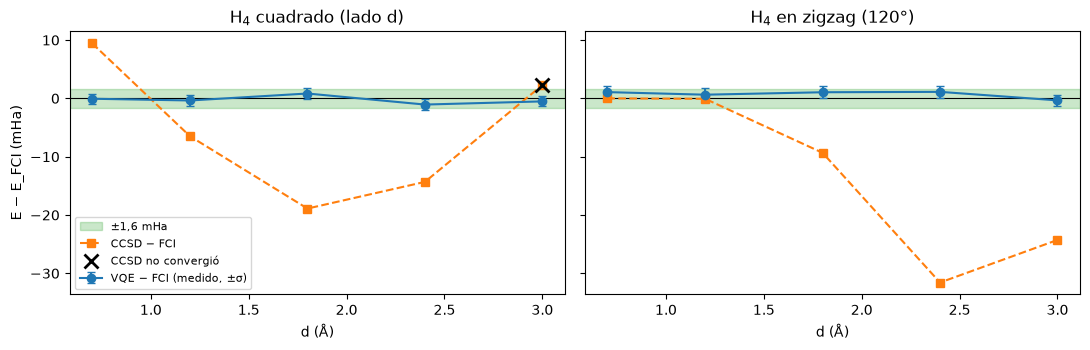

,shape,d,E_vqe,sigma,err_vqe_mHa,err_sin_ruido_mHa,err_ccsd_mHa,ccsd_converged,w_hf,beats_ccsd,cz_all,cz_line
0,square,0.700000,-1.539443,0.000897,-0.063288,0.000001,9.444815,True,0.000000,True,582,1648
1,square,1.200000,-1.967912,0.000950,-0.361929,0.000001,-6.495924,True,0.461237,True,582,1648
2,square,1.800000,-1.917221,0.000930,0.833282,0.000001,-18.895474,True,0.378209,True,582,1648
3,square,2.400000,-1.876902,0.000927,-1.061022,0.000002,-14.323018,True,0.272437,True,582,1648
4,square,3.000000,-1.868012,0.000863,-0.516820,0.000041,2.283375,False,0.215939,True,582,1648
5,zigzag,0.700000,-2.043068,0.000997,1.073715,0.000217,-0.000873,True,0.978412,False,582,1648
6,zigzag,1.200000,-2.089453,0.001129,0.630898,0.000001,-0.072615,True,0.882871,False,582,1648
7,zigzag,1.800000,-1.922460,0.001046,1.050264,0.000001,-9.336630,True,0.580439,True,582,1648
8,zigzag,2.400000,-1.873515,0.000984,1.116420,0.000001,-31.581302,True,0.349558,True,582,1648
9,zigzag,3.000000,-1.867633,0.000983,-0.341866,0.000001,-24.278063,True,0.268307,True,582,1648


In [20]:
from h4vqe.geometry import scan_geometry
from h4vqe.hamiltonian import ZIGZAG_ANGLE
GEO_D = [0.7, 1.2, 1.8, 2.4, 3.0]
GEO_SHOTS = 2_000_000
geo = pd.DataFrame(scan_geometry("square", GEO_D, GEO_SHOTS) + scan_geometry("zigzag", GEO_D, GEO_SHOTS))
geo["beats_ccsd"] = geo.err_vqe_mHa.abs() + 1e3 * geo.sigma < geo.err_ccsd_mHa.abs()
geo["err_sin_ruido_mHa"] = 1e3 * (geo.E_opt_exact - geo.E_fci)   # θ* con el estado exacto (sin shots)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, shape, title in zip(axs, ["square", "zigzag"], ["H$_4$ cuadrado (lado d)", f"H$_4$ en zigzag ({ZIGZAG_ANGLE:.0f}°)"]):
    g = geo[geo["shape"] == shape]
    a.axhspan(-1e3 * config.CHEM_ACC, 1e3 * config.CHEM_ACC, color="tab:green", alpha=0.25, label="±1,6 mHa")
    a.axhline(0, color="k", lw=0.8)
    a.errorbar(g.d, g.err_vqe_mHa, yerr=1e3 * g.sigma, fmt="o-", capsize=3, label="VQE − FCI (medido, ±σ)")
    a.plot(g.d, g.err_ccsd_mHa, "s--", color="tab:orange", label="CCSD − FCI")
    bad = g[~g.ccsd_converged]
    a.plot(bad.d, bad.err_ccsd_mHa, "x", color="k", ms=10, mew=2, label="CCSD no convergió")
    a.set_title(title); a.set_xlabel("d (Å)")
axs[0].set_ylabel("E − E_FCI (mHa)"); axs[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()
geo[["shape", "d", "E_vqe", "sigma", "err_vqe_mHa", "err_sin_ruido_mHa", "err_ccsd_mHa", "ccsd_converged", "w_hf",
     "beats_ccsd", "cz_all", "cz_line"]]

**Qué dio** (gráfico y tabla de arriba):

- **Cuadrado.** HF ya se equivoca en 124 mHa a 0,7 Å (en el zigzag, en 37 mHa). A 0,7 Å el determinante HF tiene **peso nulo** en el estado exacto (columna `w_hf`), por simetría. CCSD queda 9,4 mHa **por encima** de FCI a 0,7 Å, y 6,5, 18,9 y 14,3 mHa por debajo a 1,2, 1,8 y 2,4 Å. A 3,0 Å no converge, así que su número ahí no sirve (cruz negra en el gráfico).
- **Zigzag.** Se comporta como la cadena recta: CCSD es exacto cerca del equilibrio ($w_{\rm HF}$ = 0,98) y falla al estirar, hasta 31,6 mHa por debajo de FCI a 2,4 Å.
- **VQE.** Sin ruido llega a FCI en todos los puntos de las dos geometrías (columna `err_sin_ruido_mHa`), **incluso donde HF pesa cero**: las excitaciones dobles de UCCSD conectan HF con los determinantes que sí pesan. Con la energía medida (2 M de shots por punto), los errores son del orden de la $\sigma$. En la zona estirada, VQE le gana a CCSD con el criterio de la consigna en todos los puntos donde CCSD converge (columna `beats_ccsd`). En el cuadrado a 3,0 Å, CCSD no converge y su error ahí puede ser chico por casualidad, así que ese punto no cuenta.
- **Costo:** es el mismo circuito que UCCSD ×2 en la cadena (582 CZ, 1648 en línea), porque solo depende de la cantidad de orbitales y de electrones.

**Por qué funcionó.** VQE no necesita que HF sea una buena aproximación: solo necesita que el ansatz pueda llegar al estado exacto desde HF. CCSD, en cambio, se apoya en que HF domine, y falla justo en los casos de correlación estática, sea por estirar o por la simetría del cuadrado.

**Limitación:** con 2 M de shots, $\sigma \approx$ 0,6–1,1 mHa no alcanza para afirmar precisión química punto por punto; para eso harían falta los 8 M de shots de la curva principal.


## 11 · Comparación de ansätze: ¿cuál conviene y cuándo?
Para cerrar la parte de circuitos, juntamos en una tabla todos los ansätze que probamos. **Sin ruido, en las 18 distancias** (`scripts/compare_ansatze.py`, varios minutos, por eso no se recalcula acá; los $\boldsymbol\theta$ se optimizan como en la curva y FCI se usa solo para reportar el error; CZ y grupos a 2,4 Å):

| ansatz | qubits | θ | CZ todos con todos | CZ en línea | grupos | error máx. | error máx. ($d \ge 1{,}8$ Å) | $\langle S^2\rangle$ máx. |
|---|---|---|---|---|---|---|---|---|
| UCCSD ×1 | 8 | 26 | 292 | 804 | 37 | 4,46 mHa | 4,46 mHa | 0,85 |
| UCCSD ×2 (lo mínimo) | 8 | 52 | 582 | 1648 | 37 | 0,001 mHa | < 0,001 mHa | ≈ 0 |
| ADAPT 13 | 8 | 13 | 185 | 370 (fSWAP) | 37 | 0,59 mHa | 0,59 mHa | 0,013 |
| **ADAPT 15 (la curva)** | 8 | 15 | 194 | **378 (fSWAP)** | 37 | **0,38 mHa** | 0,38 mHa | ≤ 7·10⁻³ |
| ADAPT 15 reducido | 6 | 15 | 194 | ~510 | 37 | 0,38 mHa | 0,38 mHa | ≤ 7·10⁻³ |
| ADAPT 15 reducido | 5 | 15 | 172 | 427 | 35 | 0,38 mHa | 0,38 mHa | ≤ 7·10⁻³ |
| ADAPT-QEB 15 | 8 | 15 | 159 | 453 | 37 | 0,81 mHa | 0,81 mHa | 0,07–0,14 |
| compacto, $L$ = 5 | 5 | 30 | 10 | 10 | 35 | 56 mHa | 50 mHa | 0,025 |
| compacto, $L$ = 6 | 5 | 35 | 12 | 12 | 35 | 3,8 mHa | 3,8 mHa | 3·10⁻³ |
| **compacto, $L$ = 7** | 5 | 40 | **14** | **14** | 35 | **< 0,001 mHa** | < 0,001 mHa | ≈ 0 |
| compacto, $L$ = 8 (el que usamos con ruido) | 5 | 45 | 16 | 16 | 35 | < 0,001 mHa | < 0,001 mHa | ≈ 0 |

**Con ruido, a 2,4 Å** (`scripts/noise_ansatze.py`; modelo de §7.1 con qubits en línea; 500 k shots sin mitigar y 2 M con ZNE de plegado global, $\lambda$ = 1, 3; CCSD − FCI = −30,6 mHa). El sesgo exacto de §7.1 coincide con estas mediciones dentro de 2σ:

| ansatz | CZ (línea) | compuertas de 1 qubit | error sin ruido | con ruido, sin mitigar | con ZNE |
|---|---|---|---|---|---|
| compacto 5q, $L$ = 8 | 16 | 141 | 0,0 mHa | +12,9 ± 2,2 mHa | **+0,2 ± 2,2 mHa** |
| ADAPT 15 + fSWAP | 313 | 1377 | 0,2 mHa | +178 ± 3 mHa | +70 ± 3 mHa |
| UCCSD ×2 | 1546 | 3801 | 0,0 mHa | +548 ± 2 mHa | — |

**Qué muestran las dos tablas**

- **Sin ruido, el ansatz químico gana en significado y escala:** ADAPT 15 llega a 0,38 mHa con 3,5 veces menos parámetros y 3 veces menos CZ que UCCSD ×2. Conserva $N$ exactamente y $S^2$ casi exactamente, sus parámetros tienen sentido físico (cada uno es una excitación) y se puede justificar sin FCI con la varianza. QEB ahorra CZ con conectividad total, pero en línea queda peor que el ruteo fSWAP y rompe más el espín.
- **Reducir qubits no le sirve a ADAPT:** la energía es idéntica en 8, 6 y 5 qubits (la reducción está bien hecha), pero las CZ casi no bajan, y en línea quedan peor que con el ruteo fSWAP de 8 qubits. La reducción mezcla los modos y las excitaciones dejan de ser locales.
- **La reducción sí rinde con el compacto:** en 5 qubits, un ansatz en ladrillo de $R_Y$ + CZ entre vecinos (sin SWAP) llega a FCI con **14 CZ** ($L$ = 7). Con 12 ya falla (3,8 mHa). Es *hardware-efficient*, no químico: no conserva $N$ ni $S^2$ por construcción, solo por la penalización.
- **Con ruido, la cantidad de compuertas decide todo:** los tres ansätze son igual de buenos sin ruido, pero con 0,1 % por CZ solo el de 16 CZ le gana a CCSD. La ZNE no alcanza a salvar 313 CZ.

**Cuál usar.** Sin ruido (la curva central), **ADAPT 15**: químico, pocos parámetros, justificable sin FCI y con un método que escala a moléculas más grandes. Con ruido (los extras), **el compacto de 5 qubits**.


## 12 · ¿Y la nitrogenasa? Cuánto costaría la molécula real
La consigna arranca con la nitrogenasa: su cofactor **FeMoco** es el sistema que motiva todo esto. Como cierre, medimos **cómo crecen los recursos de VQE** al alargar la cadena de hidrógenos (H₄, H₆, …, H₁₄) y los extrapolamos al tamaño de FeMoco. Es la parte del *análisis de limitaciones*: hasta dónde llega el método y por qué.

**Hipótesis (a confirmar o refutar con los datos).** VQE escala de forma polinomial en qubits y compuertas, pero la cantidad de mediciones y la acumulación de ruido lo vuelven impracticable para FeMoco.

**La perilla: cadenas H$_N$** lineales y equiespaciadas en STO-3G, igual que el desafío: $N$ átomos → $N$ orbitales → $2N$ qubits y $N$ electrones. Hay un electrón por orbital, igual que en el modelo (54e, 54o) de FeMoco de Reiher *et al.* (2017), así que las fórmulas valen para $N$ = 54. Usamos dos distancias: $d$ = 0,894 Å (el $R_e$ de H₄) y 2,0 Å (estirada).

**Qué se cuenta para cada $N$** (`h4vqe/scaling.py`):

- **Términos de Pauli, grupos QWC (*sorted insertion*) y $\sum\lvert c_k\rvert$**: se construye $\hat H$ y se cuenta, hasta $N$ = 14 (28 qubits).
- **Parámetros de UCCSD** con la fórmula exacta. Con $o = v = N/2$ orbitales ocupados y vacíos por espín:

$$n_\theta = \underbrace{2\,o\,v}_{\text{simples}} + \underbrace{(o\,v)^2}_{\text{dobles }\alpha\beta} + \underbrace{2\binom{o}{2}\binom{v}{2}}_{\text{dobles }\alpha\alpha,\ \beta\beta}\qquad (N = 4:\ 8 + 16 + 2 = 26).$$

- **CZ de UCCSD ×1**, transpiladas como en §2 (hasta $N$ = 14), y una cota exacta por fórmula: 4 CZ por simple y 14 por doble, más 2 por cada qubit espectador de la cadena de Jordan-Wigner.
- **Shots por evaluación de energía** para $\sigma$ = 1,6 mHa, con Neyman (§4.1). La cota de peor caso, $\sqrt{V_g} \le \sum_{k\in g}\lvert c_k\rvert$, da

$$M \;=\; \frac{\big(\sum_g \sqrt{V_g}\big)^2}{\varepsilon^2} \;\le\; \frac{\big(\sum_{k}\lvert c_k\rvert\big)^2}{\varepsilon^2}.$$

  Calculamos el valor **exacto** con el estado FCI y los grupos reales hasta $N$ = 12 (24 qubits), y la cota para todo $N$.
- **Probabilidad de que ninguna CZ falle** con 0,1 % por CZ: $\log_{10} P = n_{\rm CZ}\,\log_{10}(1 - 10^{-3})$.
- **CCSD contra FCI** hasta $N$ = 14 (FCI de 11,8 millones de determinantes).

El cálculo pesado (N = 10 a 14, ~1 h en una PC) está precalculado (`scripts/scaling.py` → `results/scaling/`), y sus datos van en `h4vqe/escalado_recursos.csv`, que se escribe al principio del notebook. La celda de abajo **recalcula en vivo** $N$ = 4, 6 y 8 y los compara con lo guardado, para mostrar que es reproducible. Después ajusta leyes de potencia $y = a\,N^b$ con $N \ge 6$ y extrapola a FeMoco.


recalculado en vivo N = 4, 6, 8: máxima diferencia relativa con lo guardado = 1.5e-02 | |ΔCCSD| máx. = 6.6e-05 mHa
CZ de UCCSD ×1 para H₄ transpilado acá: 292 (guardado: 292; §2: 292)
d = 0.894 Å  (ajuste log-log con N = [6, 8, 10, 12, 14])
  terminos        ~ N^4.02 ± 0.00   (N = [6, 8, 10, 12, 14])
  grupos_qwc      ~ N^4.00 ± 0.02   (N = [6, 8, 10, 12, 14])
  suma_abs_c      ~ N^2.22 ± 0.00   (N = [6, 8, 10, 12, 14])
  cz_transpilado  ~ N^4.06 ± 0.00   (N = [6, 8, 10, 12, 14])
  cz_cota         ~ N^4.63 ± 0.02   (N = [6, 8, 10, 12, 14])
  shots_cota      ~ N^4.44 ± 0.00   (N = [6, 8, 10, 12, 14])
  shots_fci       ~ N^4.73 ± 0.14   (N = [6, 8, 10])
  shots exactos / cota (N = [6, 8, 10]): [0.048, 0.049, 0.055]
d = 2.0 Å  (ajuste log-log con N = [6, 8, 10, 12, 14])
  terminos        ~ N^4.02 ± 0.00   (N = [6, 8, 10, 12, 14])
  grupos_qwc      ~ N^4.06 ± 0.03   (N = [6, 8, 10, 12, 14])
  suma_abs_c      ~ N^2.32 ± 0.00   (N = [6, 8, 10, 12, 14])
  cz_transpilado  ~ N^4.06 ± 0.00   (N 

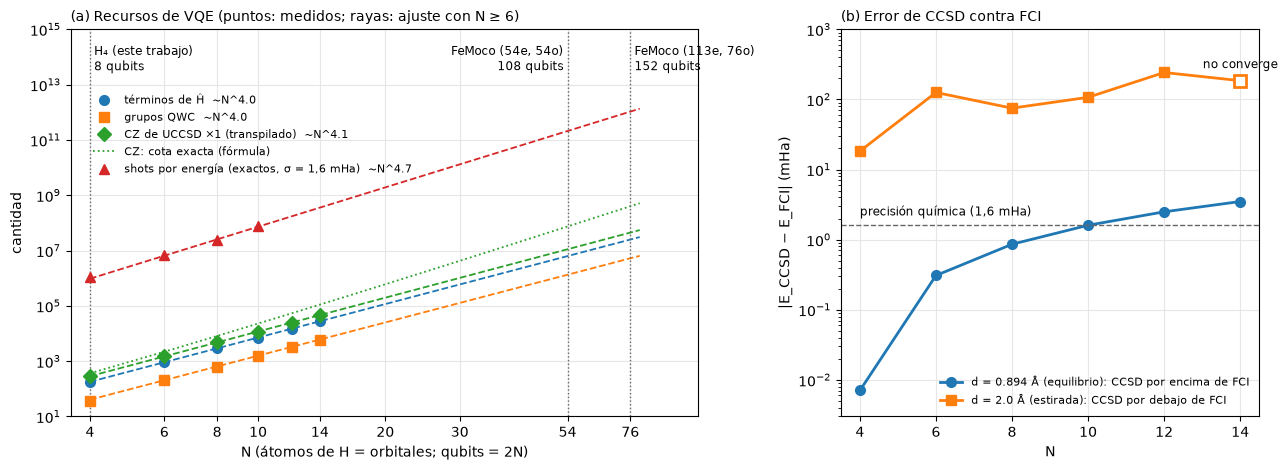

,sistema,qubits,términos,grupos QWC,parámetros UCCSD,CZ UCCSD ×1,log10 P(ninguna CZ falla),"shots por energía (σ = 1,6 mHa)",|CCSD − FCI| (mHa)
0,H4,8,184,37,26,292,-0.127,8.34e+05,18.3
1,H10,20,7.15e+03,1.54e+03,875,1.18e+04,-5.15,7.3e+07,107
2,H14,28,2.77e+04,5.9e+03,3381,4.65e+04,-20.2,NaN,185
3,"FeMoco, Reiher 2017 (extrapolado)",108,6.32e+06,1.42e+06,779301,1.12e+07,-4.85e+03,3.39e+11,NaN
4,"FeMoco, Li y Chan 2019 (extrapolado)",152,2.5e+07,5.7e+06,1780679,4.47e+07,-1.94e+04,1.87e+12,NaN


(a 2.0 Å; 1 s)


In [21]:
from h4vqe.scaling import D_EQ, D_STRETCH, chain_resources, extrapolate, plot_scaling, uccsd_cz_transpiled
t0 = time.time()
esc = pd.read_csv("h4vqe/escalado_recursos.csv")    # precalculado (scripts/scaling.py): N = 4…14
# Reproducibilidad: recalculamos en vivo N = 4, 6 y 8 y comparamos con lo guardado.
vivo = pd.DataFrame([chain_resources(n, dd, verbose=False) for n in (4, 6, 8) for dd in (D_EQ, D_STRETCH)])
jj = vivo.merge(esc, on=["N", "d"], suffixes=("", "_guardado"))
dif = max(float(np.max(np.abs(jj[c] / jj[c + "_guardado"] - 1))) for c in ["terminos", "grupos_qwc", "params", "cz_cota", "shots_fci"])
print(f"recalculado en vivo N = 4, 6, 8: máxima diferencia relativa con lo guardado = {dif:.1e} "
      f"| |ΔCCSD| máx. = {np.max(np.abs(jj.ccsd_menos_fci_mHa - jj.ccsd_menos_fci_mHa_guardado)):.1e} mHa")
print(f"CZ de UCCSD ×1 para H₄ transpilado acá: {uccsd_cz_transpiled(4)} (guardado: "
      f"{int(esc.cz_transpilado[esc.N == 4].iloc[0])}; §2: {int(minimo.loc[minimo.ansatz == 'UCCSD ×1', 'CZ todos con todos'].iloc[0])})")
ext, lineas = extrapolate(esc)
print("\n".join(lineas))
fig = plot_scaling(esc); plt.show()
filas = []
for N in (4, 10, 14):
    r = esc[(esc.N == N) & np.isclose(esc.d, D_STRETCH)].iloc[0]
    filas.append({"sistema": f"H{N}", "qubits": 2 * N, "términos": r.terminos, "grupos QWC": r.grupos_qwc,
                  "parámetros UCCSD": r.params, "CZ UCCSD ×1": r.cz_transpilado, "log10 P(ninguna CZ falla)": r.log10_p_sin_error,
                  "shots por energía (σ = 1,6 mHa)": r.shots_fci, "|CCSD − FCI| (mHa)": abs(r.ccsd_menos_fci_mHa)})
for _, r in ext[np.isclose(ext.d, D_STRETCH)].iterrows():
    filas.append({"sistema": f"FeMoco, {r.modelo} (extrapolado)", "qubits": r.qubits, "términos": r.terminos,
                  "grupos QWC": r.grupos_qwc, "parámetros UCCSD": r.params, "CZ UCCSD ×1": r.cz_transpilado,
                  "log10 P(ninguna CZ falla)": r.log10_p_sin_error, "shots por energía (σ = 1,6 mHa)": r.shots_fci,
                  "|CCSD − FCI| (mHa)": np.nan})
escala = pd.DataFrame(filas)
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(escala)
print(f"(a {D_STRETCH} Å; {time.time() - t0:.0f} s)")

**Qué dio** (salida, gráfico y tabla de arriba):

- **Lo cuántico crece como un polinomio.** Los términos de $\hat H$ y los grupos QWC crecen como $\sim N^{4}$, y las CZ de UCCSD también (~$N^{4{,}1}$). Los shots por evaluación de energía crecen más rápido, entre $N^{4{,}7}$ (equilibrio) y $N^{5}$ (estirada). Los shots exactos, con el estado FCI, son el 5–10 % de la cota de peor caso: la cota sirve para el orden de magnitud, pero exagera.
- **Pero los números absolutos no cierran.** Para FeMoco (54 orbitales, 108 qubits), UCCSD tendría ~780 mil parámetros y ~10⁷ CZ. Con 0,1 % de error por CZ, la probabilidad de que el circuito corra sin errores es $10^{-4850}$. Cada **evaluación** de la energía con $\sigma$ = 1,6 mHa pediría ~2–3·10¹¹ shots, y un VQE necesita miles de evaluaciones.
- **Lo clásico crece como una exponencial.** FCI pasa de 36 determinantes en H₄ a 11,8 millones en H₁₄ (8 minutos en una PC), y a ~4·10³⁰ en el modelo (54e, 54o) de FeMoco.
- **CCSD empeora con el tamaño.** En la zona estirada su error pasa de 18 mHa (H₄) a 242 mHa (H₁₂), y en H₁₄ no converge. Incluso **cerca del equilibrio** supera la precisión química desde H₁₀.

**Hipótesis confirmada.** VQE escala de forma polinomial en qubits y compuertas, pero la cantidad de mediciones y la acumulación de ruido lo vuelven impracticable para FeMoco sin corrección de errores. Por eso las estimaciones serias para FeMoco usan estimación de fase con corrección de errores: Lee *et al.* (*PRX Quantum* 2, 030305, 2021) calculan ~4 millones de qubits físicos y menos de 4 días. Lo que muestra H₄ es la parte que sí escala: **la confiabilidad se puede argumentar sin FCI y la cuenta de recursos se puede hacer antes de gastar un solo shot**.

**Limitaciones:** H$_N$ no es FeMoco: no tiene metales de transición, orbitales $d$ ni estados de espín casi degenerados. La extrapolación vale para **contar recursos** (qubits, términos, compuertas, shots), no para predecir la precisión ni la dificultad de optimizar. Además, el ajuste tiene pocos puntos (N = 6 a 14), así que el exponente tiene incertidumbre, y UCCSD es el caso pesimista: con ADAPT las CZ serían menos.


## 13 · Resumen final: de lo mínimo a nuestro resultado

La celda de abajo **no recalcula nada**: junta los números que salieron de las celdas anteriores en tres tablas y un gráfico.

1. **Nuestros mejores resultados**, uno por fila.
2. **Lo mínimo contra lo final**: el mismo problema resuelto con el VQE "de libro" del principio (UCCSD ×2, coloreo QWC, ajuste cuadrático, diagnósticos con el estado) y con la versión final. Los valores de esa primera corrida que ya no se recalculan están marcados como tales; el resto sale de este notebook.
3. **La evolución con ruido**: cuántas CZ usa cada etapa con qubits en línea y qué error deja el ruido a 2,4 Å. Es el sesgo exacto con matriz densidad de §7.1 y §8, así que las etapas se comparan sin ruido de shots.


1) NUESTROS MEJORES RESULTADOS


,qué,resultado,comparación
0,"Curva central, d ≥ 1,8 Å (8 M shots por punto)",error ≤ 0.56 mHa con σ = 0.50–0.54 mHa,7/7 le gana a CCSD (9–31 mHa); 7/7 con precisión química
1,"Curva central, las 18 distancias",error ≤ 1.15 mHa,18/18 con precisión química
2,R_e,0.8873 ± 0.0018 Å,FCI: 0.8886 Å (-0.7σ)
3,D_e,313.00 ± 0.66 mHa,FCI: 313.21 mHa (-0.3σ)
4,"Confiabilidad medida (sin FCI), 1,8–3,0 Å",Var(eco) ≤ 2.1e-04 Ha²; |S²| ≤ 0.011; N_α = N_β = 2 en todos los shots,HF: Var = 0.11–0.16 Ha²
5,"Con ruido (0,1 %/CZ, 2 % de lectura), 2,4 Å: compacto 5q + eco + ZNE + RO","sesgo exacto +0.008 mHa (61 M shots para σ = 0,5 mHa)","medido con shots (§8): 6/6 con precisión química en 1,8, 2,4 y 3,0 Å"
6,"FakeFez (ruido de IBM Fez), 2,4 Å: lectura + ZNE",-0.71 ± 1.23 mHa,sin mitigar: +76.1 mHa; CCSD: -30.6 mHa
7,"Otras geometrías, d ≥ 1,8 Å donde CCSD converge (UCCSD ×2, 2 M shots)",|VQE − FCI| ≤ 1.12 mHa (σ ≈ 1.0 mHa),le gana a CCSD en 5/5 puntos (9–32 mHa)
8,"Escalado a FeMoco (54 orbitales, 108 qubits)","7.79e+05 parámetros, 1.1e+07 CZ, 3.4e+11 shots por energía",P(ninguna CZ falla) = 10^-4850


2) LO MÍNIMO CONTRA LO FINAL


,,lo mínimo,final,cómo
0,ansatz,UCCSD ×2 (Trotter),"ADAPT-VQE, 15 operadores",elegidos por gradiente
1,parámetros,52,15,3.5× menos
2,"CZ, todos con todos",582,194,3.0× menos
3,"CZ, qubits en línea",1648,378,4.4× menos (ruteo fSWAP)
4,grupos de medición (QWC),46,37,sorted insertion
5,"shots para σ = 0,5 mHa a 2,4 Å",15.0 M,8.0 M,1.9× menos
6,"σ con 8 M de shots, d ≥ 1,8 Å","0,65–0,72 mHa (primera corrida)",0.50–0.54 mHa (medida),misma cantidad de shots
7,"error sin ruido máx., d ≥ 1,8 Å",6.3e-07 mHa,0.38 mHa,ambos muy por debajo de σ
8,"error medido máx., d ≥ 1,8 Å","0,74 mHa (primera corrida)",0.56 mHa,7/7 contra CCSD en los dos
9,R_e − R_e(FCI),"+7.3 mÅ (cuadrático, mismos datos)",-1.2 ± 1.8 mÅ (cuártico),ajuste elegido por su sesgo


3) LA EVOLUCIÓN CON RUIDO (2,4 Å, sesgo exacto con matriz densidad)


,etapa,CZ en línea,error sin ruido (mHa),error con ruido (mHa),|CCSD − FCI| (mHa)
0,UCCSD ×2 (lo mínimo),1546,9.5e-07,550,30.6
1,ADAPT 15 + fSWAP (la curva),313,0.234,182,30.6
2,"compacto, 5 qubits",16,1.8e-11,13.7,30.6
3,compacto + eco + ZNE + lectura,16,1.8e-11,0.008,30.6


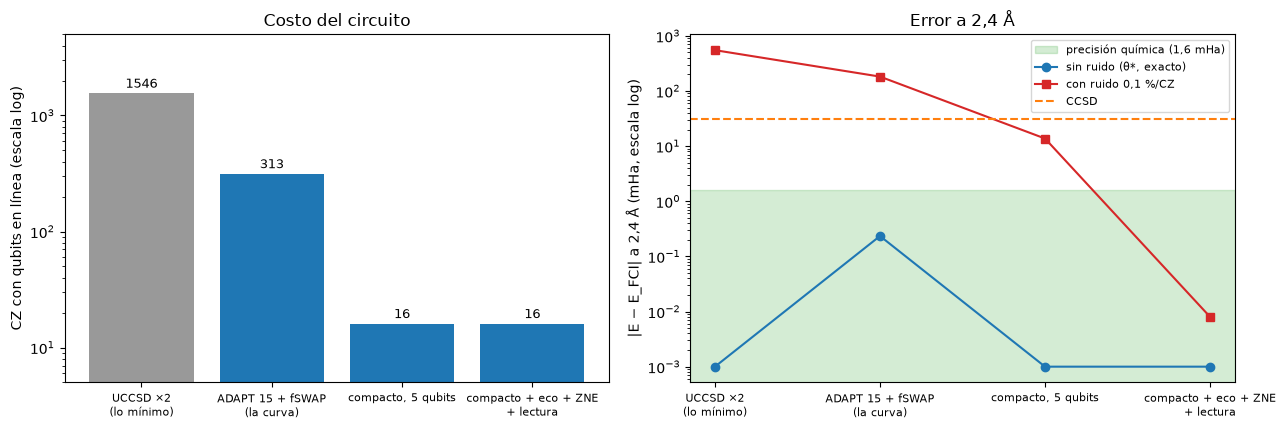

tiempo total de ejecución del notebook: 6 min


In [22]:
# Resumen: todo sale de las celdas de arriba (acá no se recalcula nada).
from h4vqe.historia import plot_evolution
st = df[df.d >= config.STRETCHED_FROM]
u2 = minimo[minimo.ansatz == "UCCSD ×2"]
cuad = cmp.set_index("modelo").loc["cuadrático 5"]
sh = shots_tab.set_index(["d", "agrupamiento"])
rz = ruido_tab.set_index("ansatz")
mi = mitig.set_index("técnica")
fzr = pd.DataFrame(fz["rows"]).set_index("método")
cur = rel[rel.rol == "curva"]
gs = geo[(geo.d >= config.STRETCHED_FROM) & geo.ccsd_converged]
fem = ext[np.isclose(ext.d, D_STRETCH) & (ext.modelo == "Reiher 2017")].iloc[0]
rng = lambda s, f="{:.2f}": f"{f.format(s.min())}–{f.format(s.max())}"
ccsd24 = 1e3 * abs(ruido_ctx["m"]["e_ccsd"] - ruido_ctx["m"]["e_fci"])
fez_z = fzr.loc["VQE en Fez, ZNE (1,3,5) + lectura"]

print("1) NUESTROS MEJORES RESULTADOS")
mejores = pd.DataFrame([
    ("Curva central, d ≥ 1,8 Å (8 M shots por punto)",
     f"error ≤ {st.err_vqe_mHa.max():.2f} mHa con σ = {rng(st.sigma_mHa)} mHa",
     f"{int(st.beats_ccsd.sum())}/{len(st)} le gana a CCSD ({rng(st.err_ccsd_mHa, '{:.0f}')} mHa); {int(st.chem_acc.sum())}/{len(st)} con precisión química"),
    ("Curva central, las 18 distancias", f"error ≤ {df.err_vqe_mHa.max():.2f} mHa",
     f"{int(df.chem_acc.sum())}/{len(df)} con precisión química"),
    ("R_e", f"{fit['R_e']:.4f} ± {fit['R_e_sigma']:.4f} Å", f"FCI: {ref['R_e']:.4f} Å ({(fit['R_e'] - ref['R_e']) / fit['R_e_sigma']:+.1f}σ)"),
    ("D_e", f"{1e3 * de['D_e']:.2f} ± {1e3 * de['D_e_sigma']:.2f} mHa", f"FCI: {1e3 * De_fci:.2f} mHa ({(de['D_e'] - De_fci) / de['D_e_sigma']:+.1f}σ)"),
    ("Confiabilidad medida (sin FCI), 1,8–3,0 Å",
     f"Var(eco) ≤ {cur.var_echo_up95.max():.1e} Ha²; |S²| ≤ {cur.S2.abs().max():.3f}; N_α = N_β = {cur.N_alpha.mean():.0f} en todos los shots",
     f"HF: Var = {rng(rel[rel.rol == 'HF'].var_echo)} Ha²"),
    ("Con ruido (0,1 %/CZ, 2 % de lectura), 2,4 Å: compacto 5q + eco + ZNE + RO",
     f"sesgo exacto {mi.loc['eco + ZNE lineal (1,3) + RO', 'sesgo (mHa)']:+.3f} mHa ({mi.loc['eco + ZNE lineal (1,3) + RO', 'shots para σ = 0,5 mHa (M)']:.0f} M shots para σ = 0,5 mHa)",
     "medido con shots (§8): 6/6 con precisión química en 1,8, 2,4 y 3,0 Å"),
    ("FakeFez (ruido de IBM Fez), 2,4 Å: lectura + ZNE",
     f"{fez_z['E − FCI (mHa)']:+.2f} ± {fez_z['sigma_mHa']:.2f} mHa",
     f"sin mitigar: {fzr.loc['VQE en Fez, sin mitigar', 'E − FCI (mHa)']:+.1f} mHa; CCSD: {fzr.loc['CCSD', 'E − FCI (mHa)']:+.1f} mHa"),
    ("Otras geometrías, d ≥ 1,8 Å donde CCSD converge (UCCSD ×2, 2 M shots)",
     f"|VQE − FCI| ≤ {gs.err_vqe_mHa.abs().max():.2f} mHa (σ ≈ {1e3 * gs.sigma.mean():.1f} mHa)",
     f"le gana a CCSD en {int(gs.beats_ccsd.sum())}/{len(gs)} puntos ({rng(gs.err_ccsd_mHa.abs(), '{:.0f}')} mHa)"),
    ("Escalado a FeMoco (54 orbitales, 108 qubits)",
     f"{fem.params:.2e} parámetros, {fem.cz_transpilado:.1e} CZ, {fem.shots_fci:.1e} shots por energía",
     f"P(ninguna CZ falla) = 10^{fem.log10_p_sin_error:.0f}"),
], columns=["qué", "resultado", "comparación"])
with pd.option_context("display.max_colwidth", 140):
    display(mejores)

print("2) LO MÍNIMO CONTRA LO FINAL")
uccsd_err = u2[u2.d >= config.STRETCHED_FROM]["error sin ruido (mHa)"].max()
adapt_err = 1e3 * (st.E_opt_exact - st.E_fci).max()
lvf = pd.DataFrame([
    ("ansatz", "UCCSD ×2 (Trotter)", "ADAPT-VQE, 15 operadores", "elegidos por gradiente"),
    ("parámetros", int(u2["parámetros"].iloc[0]), int(df.n_params.iloc[0]), f"{u2['parámetros'].iloc[0] / df.n_params.iloc[0]:.1f}× menos"),
    ("CZ, todos con todos", int(u2["CZ todos con todos"].iloc[0]), int(df.cz_all.iloc[0]), f"{u2['CZ todos con todos'].iloc[0] / df.cz_all.iloc[0]:.1f}× menos"),
    ("CZ, qubits en línea", int(u2["CZ en línea"].iloc[0]), int(df.cz_line_fswap.iloc[0]), f"{u2['CZ en línea'].iloc[0] / df.cz_line_fswap.iloc[0]:.1f}× menos (ruteo fSWAP)"),
    ("grupos de medición (QWC)", int(sh.loc[(2.4, GROUPINGS[0][2]), "grupos"]), int(sh.loc[(2.4, GROUPINGS[1][2]), "grupos"]), "sorted insertion"),
    ("shots para σ = 0,5 mHa a 2,4 Å", f"{sh.loc[(2.4, GROUPINGS[0][2]), 'shots para σ = 0,5 mHa (M)']:.1f} M", f"{sh.loc[(2.4, GROUPINGS[1][2]), 'shots para σ = 0,5 mHa (M)']:.1f} M",
     f"{sh.loc[(2.4, GROUPINGS[0][2]), 'shots para σ = 0,5 mHa (M)'] / sh.loc[(2.4, GROUPINGS[1][2]), 'shots para σ = 0,5 mHa (M)']:.1f}× menos"),
    ("σ con 8 M de shots, d ≥ 1,8 Å", "0,65–0,72 mHa (primera corrida)", f"{rng(st.sigma_mHa)} mHa (medida)", "misma cantidad de shots"),
    ("error sin ruido máx., d ≥ 1,8 Å", f"{uccsd_err:.1e} mHa", f"{adapt_err:.2f} mHa", "ambos muy por debajo de σ"),
    ("error medido máx., d ≥ 1,8 Å", "0,74 mHa (primera corrida)", f"{st.err_vqe_mHa.max():.2f} mHa", "7/7 contra CCSD en los dos"),
    ("R_e − R_e(FCI)", f"{1e3 * (cuad['R_e (Å)'] - ref['R_e']):+.1f} mÅ (cuadrático, mismos datos)", f"{1e3 * (fit['R_e'] - ref['R_e']):+.1f} ± {1e3 * fit['R_e_sigma']:.1f} mÅ (cuártico)", "ajuste elegido por su sesgo"),
    ("confiabilidad", "con el estado del simulador", "medida con shots (eco, S², N, profundidad)", "sin FCI y sin el estado"),
    ("error con ruido a 2,4 Å, sin mitigar", f"{rz.loc['UCCSD ×2 (lo mínimo)', 'error con ruido, sin mitigar (mHa)']:+.0f} mHa (peor que HF: {rz.loc['HF (sin circuito)', 'error con ruido, sin mitigar (mHa)']:+.0f})",
     f"{rz.loc['ADAPT 15 + ruteo fSWAP', 'error con ruido, sin mitigar (mHa)']:+.0f} mHa (ADAPT); {rz.loc['compacto 5 qubits (L = 8)', 'error con ruido, sin mitigar (mHa)']:+.1f} mHa (compacto 5q)", "§7"),
    ("error con ruido a 2,4 Å, mitigado", "—", f"{mi.loc['eco + ZNE lineal (1,3) + RO', 'sesgo (mHa)']:+.3f} mHa (exacto); −1,0 ± 0,5 y −0,1 ± 0,5 mHa (medidos)", "§8"),
], columns=["", "lo mínimo", "final", "cómo"])
with pd.option_context("display.max_colwidth", 120):
    display(lvf)

print("3) LA EVOLUCIÓN CON RUIDO (2,4 Å, sesgo exacto con matriz densidad)")
cp = rz.loc["compacto 5 qubits (L = 8)"]
evo = pd.DataFrame([
    {"etapa": "UCCSD ×2\n(lo mínimo)", **rz.loc["UCCSD ×2 (lo mínimo)", ["CZ (línea)", "error sin ruido (mHa)", "error con ruido, sin mitigar (mHa)"]].to_dict()},
    {"etapa": "ADAPT 15 + fSWAP\n(la curva)", **rz.loc["ADAPT 15 + ruteo fSWAP", ["CZ (línea)", "error sin ruido (mHa)", "error con ruido, sin mitigar (mHa)"]].to_dict()},
    {"etapa": "compacto, 5 qubits", **cp[["CZ (línea)", "error sin ruido (mHa)", "error con ruido, sin mitigar (mHa)"]].to_dict()},
    {"etapa": "compacto + eco + ZNE\n+ lectura", "CZ (línea)": cp["CZ (línea)"], "error sin ruido (mHa)": cp["error sin ruido (mHa)"],
     "error con ruido, sin mitigar (mHa)": mi.loc["eco + ZNE lineal (1,3) + RO", "sesgo (mHa)"]},
]).rename(columns={"CZ (línea)": "CZ en línea", "error con ruido, sin mitigar (mHa)": "error con ruido (mHa)"})
evo["|CCSD − FCI| (mHa)"] = ccsd24
evo["CZ en línea"] = evo["CZ en línea"].astype(int)
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(evo.assign(etapa=evo.etapa.str.replace("\n", " ")))
fig = plot_evolution(evo); plt.show()
print(f"tiempo total de ejecución del notebook: {(time.time() - T_INICIO) / 60:.0f} min")

### 13.1 Qué hicimos y qué cambió

| qué hicimos | qué cambió |
|---|---|
| **Lo mínimo:** UCCSD ×2, 8 M de shots, ajuste cuadrático | Cumple la consigna (7/7 contra CCSD), pero con 1648 CZ en línea |
| Ajuste elegido por su sesgo contra el mínimo FCI verdadero; diagnósticos medidos con shots | $R_e$: sesgo de +7,8 a −0,9 mÅ |
| **ADAPT-VQE** con lista común (13 operadores) | 582 → 185 CZ |
| ***Sorted insertion*** + estudio analítico de shots | 1,6–1,9× menos shots para la misma σ |
| Semilla propia por punto; medición por conmutación general | Ruido de shots independiente entre distancias |
| **Tapering a 5 qubits**, ansatz compacto de 16 CZ, modelo de ruido; otra geometría | Primer circuito que sobrevive al ruido |
| **Ruteo fSWAP** para qubits en línea | 515 → 370 CZ en línea |
| **FakeFez** con lectura + ZNE | Compatible con FCI con ruido de hardware real |
| **Calibración de σ** (3600 repeticiones, 17,8 G shots) | La barra de error es honesta (std de z = 1,01) |
| Mitigación: post-selección, lectura combinable, **plegado de R·C** | Sesgo de la ZNE de 0,16 a 0,002 mHa |
| ADAPT de **15 operadores** (pares de espín) y doble arranque | Error de 0,59 a 0,38 mHa; $S^2$ a la mitad |
| Reducción a **6 qubits** (lo que pide el extra) | Tabla 8 → 6 → 5 |
| ADAPT 15 integrado como ansatz de la curva | 194 CZ (378 en línea) en las 18 distancias |
| **Mitigación con shots** | 6/6 con precisión química con ruido |
| Comparación de ansätze sin y con ruido | El criterio "cuál usar y cuándo" |
| **Escalado** H₄ → H₁₄ → FeMoco | Hasta dónde llega el método |

### 13.2 Las decisiones y por qué mejoraron el resultado

| decisión | por qué funcionó | alternativa descartada |
|---|---|---|
| **ADAPT-VQE** con una lista común de 15 operadores | En H₄ la correlación la llevan unas pocas dobles $\alpha\beta$, y ADAPT las encuentra por gradiente. El mismo circuito en toda la curva, con 3 veces menos CZ que UCCSD ×2 | UCCSD ×2: exacto, pero con 582 CZ (1648 en línea) y 52 parámetros |
| Cortar ADAPT con la **varianza** y completar los **pares de espín** | La varianza no necesita FCI y cae un orden de magnitud justo cuando el error lo hace; los pares de espín arreglan $S^2$ y bajan el error a 0,38 mHa | Cortar por gradiente < 10⁻⁴: se frena en mesetas |
| **Ruteo fSWAP** propio | Un fSWAP mueve modos fermiónicos con su signo, en 2 CZ, y no hay que deshacerlo | SWAP del transpiler: ~2,8× más CZ en línea |
| **QWC con *sorted insertion*** + Neyman en dos etapas | Menos grupos y covarianzas que se compensan: 1,6–1,9× menos shots, sin CZ extra | Coloreo QWC (46 grupos); GC: menos shots pero agrega CZ |
| σ **desde las muestras**, semilla propia por grupo y por punto, calibrada con 3600 repeticiones | Barras honestas (std de z = 1,01) y errores independientes entre puntos | EstimatorV2 con `precision` fija; semillas consecutivas (desvíos de 4σ) |
| $\boldsymbol\theta^*$ **sin ruido** con gradiente analítico y doble arranque | Lo permite la consigna; segundos por punto y sin mínimos malos | SPSA con shots: lento y ruidoso; solo *warm start*: mínimos malos |
| **Cuártico en 7 puntos** elegido por su sesgo contra el mínimo FCI exacto | Mide el error del método de ajuste sin mirar el VQE | Cuadrático en 5 puntos: +7,8 mÅ de sesgo; comparar contra FCI ajustado igual |
| Confiabilidad **medida**: eco de Loschmidt, $S^2$, profundidad, límite físico | Cuenta eventos raros (resuelve $10^{-6}$ Ha²) y detecta el estado de espín equivocado | Varianza por grupos sola: $\sigma \approx 2\cdot10^{-3}$ Ha², no separa ansätze |
| Con ruido: **tapering a 5 qubits + compacto de 16 CZ** | Las simetrías son información conocida; sacarlas deja un espacio de 32 estados que un circuito nativo de la línea recorre sin SWAP | ADAPT o UCCSD con ruido: 181 y 548 mHa de error |
| Mitigación: **lectura + eco + ZNE con plegado de R·C** | Cada técnica ataca un sesgo distinto; plegar también la rotación de medición escala todo el ruido | ZNE sola (no toca la lectura); plegar solo las CZ (4 mHa de sesgo) |

### 13.3 Hasta dónde llega el método (limitaciones)

- **La curva central es sin ruido de compuertas.** La $\sigma$ es solo estadística. Con 0,1 % de error por CZ, el ansatz de la curva (194 CZ, 378 en línea) tendría un sesgo de ~180 mHa. Con ruido, el resultado que vale es el del compacto de 5 qubits con mitigación, que **no escala** a moléculas grandes.
- **Los parámetros se buscan sin ruido**, como permite la consigna. La curva mide qué tan expresivo es el ansatz más el ruido de los shots, no la dificultad de optimizar con mediciones ruidosas.
- **Shots:** 8 M por punto (144 M en la curva) para $\sigma \approx$ 0,5 mHa; la mitigación multiplica eso por ~4.
- **El eco de Loschmidt** es un diagnóstico de simulador (más de 4000 CZ). En hardware, lo equivalente es la varianza por grupos con más shots.
- **FakeFez** no modela los tiempos muertos ni la diafonía, y su $\sigma \approx$ 1,2 mHa no alcanza para afirmar precisión química.
- **Escalado (§12):** los conteos crecen como potencias de $N$, pero los shots y la probabilidad de un circuito sin errores vuelven inviable un VQE así para FeMoco. Las estimaciones serias para FeMoco usan estimación de fase con corrección de errores.

### 13.4 Lo que no hicimos y haríamos después

- **VQE contra SQD** (extra de la consigna): no llegamos. Con 8 qubits, SQD es trivial (hasta muestras al azar dan la respuesta), así que el experimento interesante es el de §12: un tope al subespacio en cadenas más largas.
- **Un pool adaptado al espín** (pares de dobles $\alpha\beta$ con un mismo parámetro) para que $S^2$ sea exactamente 0, y operadores CEO de 9 CNOT para bajar más las CZ.
- **GC en 5 qubits** para el compacto con ruido: menos shots a cambio de unas pocas CZ.
- **Hardware real**: la receta de §9 (línea elegida por calibración, lectura + ZNE) está lista para un backend de IBM con `QiskitRuntimeService`.
